# Amazon Polarity shortcut analysis

This notebook reproduces the non-PCA IMDB experiments on Amazon Polarity. The IMDB-specific numeric/non-numeric split is replaced with an Amazon-specific explicit rating-proxy/non-rating-proxy split. A separate final section analyzes genuinely contiguous salient bigrams and trigrams.


### The three splits

Amazon Polarity originally provides:
- Official train set: 3,600,000 reviews
- Official test set:    400,000 reviews

We split the official training set using: DATA_SPLIT_SEED = 1 into:
train_data:       3,550,000 reviews
validation_data:     50,000 reviews
test_data:          400,000 reviews

**train_data**

Used to update the model weights during fine-tuning.
train_data = dataset["train"]

**validation_data**

Taken out of the original training set before fine-tuning. It is used to measure performance during development, but it is not used for gradient updates.
validation_data = dataset["validation"]
Because train_test_split() creates two disjoint partitions, these 50,000 samples are not in train_data.

**test_data**

This is the unchanged official Amazon Polarity test set:
test_data = dataset["test"]
It was not part of the 3.6-million-example training pool and was not used to train the model.


**Predictions are aligned**

The .npz contains predictions for the official test set in its original order:
amazon_polarity_test_with_preds.npz

The notebook now loads the same:
test_data = dataset["test"]

It checks:
len(test_data) == len(test_preds) == 400_000
and also compares the labels and texts. Therefore:
test_preds[i] corresponds to test_data[i]

**What the seeds affects**

DATA_SPLIT_SEED = 1
determines which 50,000 examples are selected as validation. It does not affect the official test set.

MODEL_SEED = 1
controls model-training randomness.

For seeds 1, 2, and 42, keep:
DATA_SPLIT_SEED = 1
and change only MODEL_SEED.

---
## Setting up S1 Vocabulary

Imports

In [3]:
from pathlib import Path
from collections import Counter, defaultdict
import re
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import ClassLabel, Dataset, DatasetDict, load_dataset, load_from_disk
from mlxtend.frequent_patterns import fpgrowth
from mlxtend.preprocessing import TransactionEncoder
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import BertForSequenceClassification, BertModel, BertTokenizerFast


Load models and tokenizer: fine-tuned Amazon Polarity BERT and pretrained BERT

In [4]:
# Change only MODEL_SEED when analysing another fine-tuned model.
MODEL_SEED = 1

model_path = Path(f"./polarity_seed_{MODEL_SEED}/model")

if not model_path.exists():
    raise FileNotFoundError(
        f"Fine-tuned model not found at: {model_path.resolve()}"
    )

tokenizer = BertTokenizerFast.from_pretrained(str(model_path))
ft_bert = BertForSequenceClassification.from_pretrained(str(model_path))

pretrained_name = "bert-base-uncased"
pt_bert = BertModel.from_pretrained(pretrained_name)

print("Model seed:", MODEL_SEED)
print("Fine-tuned model:", model_path.resolve())


Model seed: 1
Fine-tuned model: /Users/leosteiner/Desktop/transformer-shortcut-mitigation/polarity_seed_1/model


Load Dataset

In [5]:
# DATA_SPLIT_SEED stays fixed so all models use the same train/validation split.
DATA_SPLIT_SEED = 1
VALIDATION_SIZE = 50_000

# Shared cache used by seed 1, seed 2, and seed 42 models.
# It is deliberately outside the polarity_seed_* model folders.
PROCESSED_DATASET_PATH = Path(
    f"./amazon_polarity_processed_split_seed_{DATA_SPLIT_SEED}"
)


def create_text_column(batch):
    """Combine title and review body into one text field."""
    texts = []

    for title, content in zip(batch["title"], batch["content"]):
        title = "" if title is None else str(title).strip()
        content = "" if content is None else str(content).strip()

        text = " ".join(
            part for part in (title, content) if part
        )
        texts.append(text)

    return {"text": texts}


if PROCESSED_DATASET_PATH.exists():
    print("Loading cached processed Amazon Polarity dataset...")
    dataset = load_from_disk(str(PROCESSED_DATASET_PATH))

else:
    print("No processed cache found.")
    print("Downloading and preprocessing Amazon Polarity once...")

    raw_dataset = load_dataset("fancyzhx/amazon_polarity")
    raw_train = raw_dataset["train"]

    # Stratified splitting requires a ClassLabel feature.
    if not isinstance(raw_train.features["label"], ClassLabel):
        raw_train = raw_train.class_encode_column("label")

    train_validation_split = raw_train.train_test_split(
        test_size=VALIDATION_SIZE,
        stratify_by_column="label",
        seed=DATA_SPLIT_SEED,
    )

    dataset = DatasetDict({
        "train": train_validation_split["train"],
        "validation": train_validation_split["test"],
        "test": raw_dataset["test"],
    })

    # After this mapping, every split contains only text and label.
    dataset = dataset.map(
        create_text_column,
        batched=True,
        remove_columns=["title", "content"],
        desc="Creating combined review text",
    )

    dataset.save_to_disk(str(PROCESSED_DATASET_PATH))
    print("Processed dataset saved to:")
    print(PROCESSED_DATASET_PATH.resolve())


# Safety checks against accidentally loading an incompatible cache.
expected_splits = {"train", "validation", "test"}
if set(dataset.keys()) != expected_splits:
    raise ValueError(f"Unexpected dataset splits: {dataset.keys()}")

for split_name in ("train", "validation", "test"):
    if set(dataset[split_name].column_names) != {"text", "label"}:
        raise ValueError(
            f"Unexpected columns in {split_name}: "
            f"{dataset[split_name].column_names}"
        )

print(dataset)
print("Data split seed:", DATA_SPLIT_SEED)
print("Processed dataset path:", PROCESSED_DATASET_PATH.resolve())


Loading cached processed Amazon Polarity dataset...
DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 3550000
    })
    validation: Dataset({
        features: ['label', 'text'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 400000
    })
})
Data split seed: 1
Processed dataset path: /Users/leosteiner/Desktop/transformer-shortcut-mitigation/amazon_polarity_processed_split_seed_1


In [6]:
train_data = dataset["train"]
validation_data = dataset["validation"]
official_test_data = dataset["test"]

# This notebook reproduces the test-set shortcut analysis used in the other notebooks.
pipeline_data = official_test_data
test_data = official_test_data

assert len(train_data) == 3_550_000
assert len(validation_data) == 50_000
assert len(test_data) == 400_000

print("Training examples:", len(train_data))
print("Validation examples:", len(validation_data))
print("Pipeline/test examples:", len(test_data))


Training examples: 3550000
Validation examples: 50000
Pipeline/test examples: 400000


## Set up device

In [7]:
# Device setup
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

pt_bert = pt_bert.to(device)
ft_bert = ft_bert.to(device)

pt_bert.eval()
ft_bert.eval()

print("Device:", device)


Device: mps


Method used to extract Saliency.

Source: [Understanding Text Classification Data and Models Using Aggregated Input Salience](https://arxiv.org/abs/2211.05485)

In [8]:
def grad_l2_saliency(
    text: str,
    model,
    tokenizer,
    device,
    target_class: int | None = None,
    max_length: int = 256
):
    """
    Compute Grad-L2 saliency for one input text.

    Returns:
        tokens: list[str]          # wordpiece tokens incl. special tokens
        saliency: np.ndarray       # shape (seq_len,)
        input_ids: np.ndarray      # token ids (same length as saliency)
    """
    model.eval()

    # 1) Tokenize
    enc = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=max_length
    )
    input_ids = enc["input_ids"].to(device)           # [1, L] L = sequence length
    attention_mask = enc["attention_mask"].to(device) # [1, L]
    token_type_ids = enc.get("token_type_ids")
    if token_type_ids is not None:
        token_type_ids = token_type_ids.to(device)

    # 2) Get word embeddings and make them a leaf tensor with grad
    with torch.no_grad():
        word_embeds = model.bert.embeddings.word_embeddings(input_ids)
    word_embeds = word_embeds.detach().requires_grad_(True)  # [1, L, H]

    # 3) Forward pass using inputs_embeds so we can backprop to embeddings
    model.zero_grad()
    outputs = model(
        inputs_embeds=word_embeds, #pass embeddings instead of input_ids
        attention_mask=attention_mask,
        token_type_ids=token_type_ids
    )
    logits = outputs.logits  # [1, num_labels]

    # 4) Choose the logit to explain: pick predicted label by default
    if target_class is None:
        target_class = logits.argmax(dim=-1).item()  # predicted label

    # using the predicted class as scalar for autograd
    score = logits[0, target_class] # standard tensor indexing: tensor[row_index, column_index]

    # 5) Backward: d score / d word_embeds # computes gradients of score with respect to all tensors that have requires_grad=True in the computation graph.
    score.backward()

    grads = word_embeds.grad  # [1, L, H] store gradient 

    # 6) L2 norm over hidden dimension -> one score per token
    saliency = torch.norm(grads, p=2, dim=-1).squeeze(0)  # [1,L,H ] -> [1,L] -> [L] collapsing H

    # 7) Move to CPU / numpy
    saliency = saliency.detach().cpu().numpy()
    input_ids_cpu = input_ids.squeeze(0).detach().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids_cpu)

    return tokens, saliency, input_ids_cpu


Predict Test Set in preparation for S1 Vocabulary

In [9]:
def predict_labels(
    dataset_split,
    model,
    tokenizer,
    device,
    batch_size=32,
    max_length=256,
):
    model.eval()

    loader = DataLoader(
        dataset_split,
        batch_size=batch_size,
        shuffle=False,
    )

    all_preds = []

    with torch.no_grad():
        for batch in loader:
            texts = batch["text"]

            enc = tokenizer(
                list(texts),
                return_tensors="pt",
                truncation=True,
                padding=True,
                max_length=max_length,
            ).to(device)

            logits = model(**enc).logits
            preds = logits.argmax(dim=-1).cpu()
            all_preds.extend(preds.tolist())

    return np.asarray(all_preds, dtype=np.int64)


# Existing predictions from the fine-tuning notebook.
npz_path = Path("amazon_polarity_test_with_preds.npz")

# Seed-specific fallback if predictions ever need to be recomputed.
npy_path = Path(f"test_preds_seed_{MODEL_SEED}.npy")


if npz_path.exists():
    saved_data = np.load(npz_path, allow_pickle=True)
    test_preds = saved_data["pred"].astype(np.int64)

    # Verify row-level alignment with the official Amazon Polarity test split.
    assert len(test_data) == len(test_preds) == 400_000
    assert np.array_equal(
        np.asarray(test_data["label"]),
        saved_data["label"],
    )

    if "seed" in saved_data.files:
        prediction_seed = int(
            np.asarray(saved_data["seed"]).reshape(-1)[0]
        )
        assert prediction_seed == MODEL_SEED, (
            f"The NPZ belongs to model seed {prediction_seed}, "
            f"but MODEL_SEED is {MODEL_SEED}."
        )

    if "text" in saved_data.files:
        chunk_size = 10_000

        for start in range(0, len(test_data), chunk_size):
            end = min(start + chunk_size, len(test_data))

            dataset_text = np.asarray(
                test_data[start:end]["text"],
                dtype=object,
            )
            saved_text = saved_data["text"][start:end]

            assert np.array_equal(dataset_text, saved_text)

    print("Loaded aligned predictions from:", npz_path)

elif npy_path.exists():
    test_preds = np.load(npy_path).astype(np.int64)

    assert len(test_data) == len(test_preds) == 400_000
    print("Loaded predictions from:", npy_path)

else:
    test_preds = predict_labels(
        test_data,
        ft_bert,
        tokenizer,
        device,
        max_length=256,
    )

    np.save(npy_path, test_preds)
    print("Generated and saved predictions to:", npy_path)


print("Number of predictions:", len(test_preds))


Loaded aligned predictions from: amazon_polarity_test_with_preds.npz
Number of predictions: 400000


Function to extract top 5 salient tokens per sentence.

In [10]:
def topk_vocab_tokens_with_maxpos(input_ids, saliency, top_k=5, exclude_special_ids=None):
    """
    For one sentence:
    - For each vocab token_id, keep the maximum |saliency| value observed in this sentence,
      and the token position where that maximum occurs.
    - Return the top_k token_ids ranked by that max |saliency|.

    Output format (length <= top_k):
      [{"token_id": int, "position": int, "saliency": float}, ...]
    """
    exclude_special_ids = set(exclude_special_ids or [])
    best = {}  # token_id -> (best_abs_saliency, position)

    for pos, (tok_id, s) in enumerate(zip(input_ids, saliency)):
        tok_id = int(tok_id)
        if tok_id in exclude_special_ids:
            continue

        a = abs(float(s))
        if (tok_id not in best) or (a > best[tok_id][0]):
            best[tok_id] = (a, int(pos))

    if not best:
        return []

    items = [(tok_id, a, pos) for tok_id, (a, pos) in best.items()]
    items.sort(key=lambda x: x[1], reverse=True)
    items = items[:top_k]

    return [{"token_id": tok_id, "saliency": a, "position": pos} for tok_id, a, pos in items]

Fill up row per sentence vectors for top-5 tokens:

---

**Build S1-Vocab**

This function converts the first n text examples into their salience-fingerprints (S1 vectors), stacks those into a matrix, normalizes them, and returns both the matrix and the original texts.

Text example -> Row

<pre>
          column dimension → |V| (the r vector)
        ┌──────────────────────────────────────────────┐
 row 1  │ r(1)[0]   r(1)[1]   r(1)[2]   ...   r(1)[V-1]│
 row 2  │ r(2)[0]   r(2)[1]   r(2)[2]   ...   r(2)[V-1]│
   .    │    .         .         .              .      │
 row N  │ r(N)[0]   r(N)[1]   r(N)[2]   ...   r(N)[V-1]│
        └──────────────────────────────────────────────┘
             ↑
             vocabulary-dimension (S1 vector)***
<pre>

In [11]:
def saliency_to_vocab_vector(input_ids, saliency, vocab_size, top_k=5):
    """
    Implements S1 from the paper: a |V|-dim vector with the
    max |saliency| per vocab item, zeroed except for top-k entries.
    """
    r = np.zeros(vocab_size, dtype=np.float32) # expecting vocab size of bert tokenzier

    for tok_id, s in zip(input_ids, saliency):
        tok_id = int(tok_id)
        r[tok_id] = max(r[tok_id], abs(float(s))) # get max saliency value

    if top_k is not None and top_k < vocab_size:
        # Keep only top-k entries, zero out the rest
        if np.count_nonzero(r) > top_k: # count how many positoons in r are not zero
            top_idx = np.argpartition(r, -top_k)[-top_k:] # Find the indices of the k largest values in r, argsort begin nlogn efficient
            mask = np.zeros_like(r)
            mask[top_idx] = r[top_idx]
            r = mask

    return r


def build_salience_vocab_matrix_from_indices(
    dataset_split,
    indices,
    model,
    tokenizer,
    device,
    top_k=5,
    max_length=256,
):
    """Build a row-normalized vocabulary salience matrix for selected dataset indices.

    For each text, computes token saliency, aggregates the top-k salient tokens into a
    vocabulary-sized vector, and returns the stacked matrix along with the source texts
    and per-example top-k token metadata including raw and normalized saliency scores.
    """
    vocab_size = tokenizer.vocab_size
    R_rows = []
    texts = []
    salient_token_info = [] # save positions

    special_ids = tokenizer.all_special_ids  


    for idx in tqdm(indices):
        text = dataset_split[idx]["text"]
        tokens, sal, ids = grad_l2_saliency(
            text, model, tokenizer, device, max_length=max_length
        )
        r = saliency_to_vocab_vector(ids, sal, vocab_size, top_k=top_k)
        R_rows.append(r)
        texts.append(text)


        # extract token_positions
        topk_vocab = topk_vocab_tokens_with_maxpos(
            ids, sal, top_k=top_k, exclude_special_ids=special_ids
        )
        salient_token_info.append({
            "dataset_idx": idx,
            "text": text,
            "topk_vocab": topk_vocab
        })

    R_vocab = np.stack(R_rows, axis=0)
    # row-wise L2 normalization as in the paper
    norms = np.linalg.norm(R_vocab, axis=1, keepdims=True) + 1e-12
    R_vocab = R_vocab / norms
    #store both raw + normalized saliency per token in salient_token_info
    for row_i, info in enumerate(salient_token_info):
        for item in info["topk_vocab"]:
            tok_id = int(item["token_id"])
            item["saliency_raw"] = float(item["saliency"])              # existing raw abs-saliency
            item["saliency_norm"] = float(R_vocab[row_i, tok_id])       # exact value from r_vocab row

    return R_vocab, texts, salient_token_info

In [12]:
# Select examples predicted as negative by the current model.
neg_indices = np.flatnonzero(test_preds == 0)

# This controls only which 2,500 test examples are sampled.
# Use 42, 1, and 2 for the three sampling repetitions.
SAMPLE_SEED = 2
SAMPLE_SIZE = 2_500

rng = np.random.default_rng(SAMPLE_SEED)

sample_size = min(SAMPLE_SIZE, len(neg_indices))
neg_sample_indices = rng.choice(
    neg_indices,
    size=sample_size,
    replace=False,
)

R_vocab_5_neg, texts_neg, salient_token_info_neg = (
    build_salience_vocab_matrix_from_indices(
        test_data,
        neg_sample_indices,
        ft_bert,
        tokenizer,
        device,
        top_k=5,
    )
)

print("Model seed:", MODEL_SEED)
print("Sample seed:", SAMPLE_SEED)
print("Negative sample size:", len(neg_sample_indices))


100%|██████████| 2500/2500 [02:47<00:00, 14.90it/s]


Model seed: 1
Sample seed: 2
Negative sample size: 2500


Create S1-Vocab for 2500 positively predicted samples

In [13]:
# Optional positive-class analysis.
#
# pos_indices = np.flatnonzero(test_preds == 1)
# rng_pos = np.random.default_rng(SAMPLE_SEED)
#
# pos_sample_indices = rng_pos.choice(
#     pos_indices,
#     size=min(SAMPLE_SIZE, len(pos_indices)),
#     replace=False,
# )
#
# R_vocab_5_pos, texts_pos, salient_token_info_pos = (
#     build_salience_vocab_matrix_from_indices(
#         test_data,
#         pos_sample_indices,
#         ft_bert,
#         tokenizer,
#         device,
#         top_k=5,
#     )
# )


## Original method: FP-growth over bags of salient tokens

This reproduces the IMDB pipeline. FP-growth receives unordered sets of salient token IDs. The `ordered_ids` column is added afterward for presentation and hidden-state experiments; these patterns are not yet guaranteed to be contiguous n-grams.


Imports

Setup Transactions and Lookup Table (Salient tokens per Sentence identified with L2-Grad Saliency Method)

In [14]:
transactions_neg_5 = []
pos_lookup_neg_5 = []   # list of dicts: token_id -> position (for this transaction)

for item in salient_token_info_neg:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]

    transactions_neg_5.append(toks)
    pos_lookup_neg_5.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

print("num transactions_neg_5:", len(transactions_neg_5))
print("avg len:", np.mean([len(t) for t in transactions_neg_5]))
print(transactions_neg_5[:5])

num transactions_neg_5: 2500
avg len: 5.0
[[5223, 2919, 12057, 2326, 8312], [4788, 5136, 14949, 3067, 3737], [3291, 2502, 2074, 6412, 2028], [25756, 5409, 29020, 3185, 2412], [9364, 17115, 10520, 2053, 2153]]


Running FP-Algorithm

In [15]:
te = TransactionEncoder() # Creates encoder that converts lists of tokens into a binary matrix (One hot encoded)
X = te.fit(transactions_neg_5).transform(transactions_neg_5) # fit and transform bool matrix to prepare for fp-growth

df = pd.DataFrame(X, columns=te.columns_) # to pandas

freq_itemsets_neg_5 = fpgrowth(
    df,
    min_support=0.002, # minimum frequency of items -> 0.002 = 0.2%
    use_colnames=True, # return column names not indices
    max_len=4 # max item size per pattern
)

freq_itemsets_neg_5["length"] = freq_itemsets_neg_5["itemsets"].apply(len) # add length column

def order_itemset_like_sentence(itemset):
    # pick a transaction and use its token positions as the order reference
    items = [int(x) for x in itemset]

    for tx, pm in zip(transactions_neg_5, pos_lookup_neg_5):
        if all(i in pm for i in items):
            return sorted(items, key=lambda i: pm[i])

    return items


freq_itemsets_neg_5["ordered_ids"] = freq_itemsets_neg_5["itemsets"].apply(order_itemset_like_sentence)
freq_itemsets_neg_5["ordered_tokens"] = freq_itemsets_neg_5["ordered_ids"].apply(lambda ids: tokenizer.convert_ids_to_tokens(ids))

Inspect frequent, high-support salient-token itemsets with length greater than one.

In [16]:
freq_itemsets_neg_5[freq_itemsets_neg_5["length"] > 1].sort_values("support", ascending=False).head(40)

,support,itemsets,length,ordered_ids,ordered_tokens
562,0.0092,"(2769, 5949)",2,"[5949, 2769]","[waste, money]"
532,0.0092,"(3737, 3532)",2,"[3532, 3737]","[poor, quality]"
549,0.0060,"(15640, 9364)",2,"[9364, 15640]","[disappointed, disappointing]"
555,0.0052,"(11488, 4487)",2,"[4487, 11488]","[di, ##ssa]"
566,0.0048,"(2048, 3340)",2,"[2048, 3340]","[two, stars]"
539,0.0048,"(1016, 3340)",2,"[1016, 3340]","[2, stars]"
552,0.0048,"(2025, 4276)",2,"[2025, 4276]","[not, worth]"
533,0.0044,"(2732, 2028)",2,"[2028, 2732]","[one, star]"
537,0.0036,"(2025, 9364)",2,"[2025, 9364]","[not, disappointed]"
538,0.0036,"(2732, 1015)",2,"[1015, 2732]","[1, star]"


### Creating negative R_Vocab with the top 10 salient tokens per sentence.

In [17]:
R_vocab_10_neg, texts_neg_10, salient_token_info_neg_10 = build_salience_vocab_matrix_from_indices(
    test_data,
    neg_sample_indices,
    ft_bert,
    tokenizer,
    device,
    top_k=10, ######################
)

100%|██████████| 2500/2500 [02:05<00:00, 19.99it/s]


Setup Transactions and Lookup Table (Salient tokens per Sentence identified with L2-Grad Saliency Method)

In [18]:
transactions_neg_10 = []
pos_lookup_10 = []   # list of dicts: token_id -> position (for this transaction)

for item in salient_token_info_neg_10:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]

    transactions_neg_10.append(toks)
    pos_lookup_10.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

print("num transactions_neg_10:", len(transactions_neg_10))
print("avg len:", np.mean([len(t) for t in transactions_neg_10]))
print(transactions_neg_10[:5])

num transactions_neg_10: 2500
avg len: 10.0
[[5223, 2919, 12057, 2326, 8312, 2578, 24970, 2009, 8875, 3976], [4788, 5136, 14949, 3067, 3737, 8875, 5684, 13131, 8000, 2659], [3291, 2502, 2074, 6412, 2028, 4965, 8875, 5633, 3179, 2544], [25756, 5409, 29020, 3185, 2412, 3085, 4276, 3422, 4524, 3294], [9364, 17115, 10520, 2053, 2153, 2186, 10917, 2062, 2296, 2197]]


Running FP-Algorithm

In [19]:
te = TransactionEncoder() # Creates encoder that converts lists of tokens into a binary matrix (One hot encoded)
X = te.fit(transactions_neg_10).transform(transactions_neg_10) # fit and transform bool matrix to prepare for fp-growth

df = pd.DataFrame(X, columns=te.columns_) # to pandas

freq_itemsets_neg_10 = fpgrowth(
    df,
    min_support=0.002, # minimum frequency of items -> 0.002 = 0.2%
    use_colnames=True, # return column names not indices
    max_len=4 # max item size per pattern
)

freq_itemsets_neg_10["length"] = freq_itemsets_neg_10["itemsets"].apply(len) # add length column

def order_itemset_like_sentence(itemset):
    # pick a transaction and use its token positions as the order reference
    items = [int(x) for x in itemset]

    for tx, pm in zip(transactions_neg_10, pos_lookup_10):
        if all(i in pm for i in items):
            return sorted(items, key=lambda i: pm[i])

    return items


freq_itemsets_neg_10["ordered_ids"] = freq_itemsets_neg_10["itemsets"].apply(order_itemset_like_sentence)
freq_itemsets_neg_10["ordered_tokens"] = freq_itemsets_neg_10["ordered_ids"].apply(lambda ids: tokenizer.convert_ids_to_tokens(ids))

Inspect frequent salient-token itemsets. Ordering alone does not yet imply contiguity.

In [20]:
freq_itemsets_neg_10[freq_itemsets_neg_10["length"] > 1].sort_values("support", ascending=False).head(40)

,support,itemsets,length,ordered_ids,ordered_tokens
1316,0.0272,"(2769, 5949)",2,"[5949, 2769]","[waste, money]"
1440,0.0140,"(2025, 2204)",2,"[2025, 2204]","[not, good]"
1205,0.0136,"(2025, 1012)",2,"[1012, 2025]","[., not]"
1241,0.0128,"(3737, 3532)",2,"[3532, 3737]","[poor, quality]"
1313,0.0112,"(1012, 5949)",2,"[5949, 1012]","[waste, .]"
1142,0.0108,"(2025, 4276)",2,"[2025, 4276]","[not, worth]"
1442,0.0108,"(2204, 1012)",2,"[2204, 1012]","[good, .]"
1341,0.0104,"(2769, 3828)",2,"[3828, 2769]","[save, money]"
1448,0.0100,"(2025, 2021)",2,"[2021, 2025]","[but, not]"
1334,0.0100,"(2200, 2025)",2,"[2025, 2200]","[not, very]"


In [21]:
freq_itemsets_neg_10[freq_itemsets_neg_10["length"] > 2].sort_values("support", ascending=False).head(40)

,support,itemsets,length,ordered_ids,ordered_tokens
1494,0.0056,"(11488, 8400, 4487)",3,"[4487, 11488, 8400]","[di, ##ssa, ##point]"
1558,0.0048,"(2769, 2115, 5949)",3,"[5949, 2115, 2769]","[waste, your, money]"
1323,0.0040,"(2769, 1012, 5949)",3,"[1012, 5949, 2769]","[., waste, money]"
1149,0.0032,"(2769, 4276, 2025)",3,"[2025, 4276, 2769]","[not, worth, money]"
1340,0.0032,"(2200, 2025, 2204)",3,"[2204, 2025, 2200]","[good, not, very]"
1446,0.0028,"(2025, 2204, 1012)",3,"[2025, 2204, 1012]","[not, good, .]"
1249,0.0028,"(3737, 16755, 3532)",3,"[3532, 3737, 16755]","[poor, quality, recommend]"
1321,0.0028,"(2769, 9364, 5949)",3,"[9364, 5949, 2769]","[disappointed, waste, money]"
1322,0.0028,"(2769, 5949, 2023)",3,"[2023, 5949, 2769]","[this, waste, money]"
1664,0.0028,"(11488, 3672, 4487)",3,"[4487, 11488, 3672]","[di, ##ssa, ##ment]"


---
## Experiment 1: Saliency and representation shifts of frequent salient-token itemsets

Add Saliency values per transaction

In [22]:
transactions_neg_10 = []
pos_lookup_neg_10 = []   # list of dicts: token_id -> position (per sample)
saliency_lookup = []   # list of dicts: token_id -> saliency_norm (per sample)


for item in salient_token_info_neg_10:
    toks = [int(t["token_id"]) for t in item["topk_vocab"]]

    transactions_neg_10.append(toks)
    pos_lookup_neg_10.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})

    saliency_lookup.append({int(t["token_id"]): float(t["saliency_norm"]) for t in item["topk_vocab"]})

print("transactions_neg_10:", len(transactions_neg_10))
print("avg transaction length:", np.mean([len(t) for t in transactions_neg_10]))
print(transactions_neg_10[:5])

# Convert transactions_neg_10 to matrix
te = TransactionEncoder()
X = te.fit(transactions_neg_10).transform(transactions_neg_10)
df = pd.DataFrame(X, columns=te.columns_)

print("transaction matrix shape:", df.shape)

#Run FP-Growth
freq_itemsets_neg_10 = fpgrowth(
    df,
    min_support=0.002, # minimum frequency of items -> 0.002 = 0.2%
    use_colnames=True, # return column names not indices
    max_len=4 # max item size per pattern
)

freq_itemsets_neg_10["length"] = freq_itemsets_neg_10["itemsets"].apply(len)

def order_itemset_like_sentence(itemset):
    # pick a transaction and use its token positions as the order reference
    items = [int(x) for x in itemset]

    for tx, pm in zip(transactions_neg_10, pos_lookup_neg_10):
        if all(i in pm for i in items):
            return sorted(items, key=lambda i: pm[i])

    return items

freq_itemsets_neg_10["ordered_ids"] = freq_itemsets_neg_10["itemsets"].apply(order_itemset_like_sentence)
freq_itemsets_neg_10["ordered_tokens"] = freq_itemsets_neg_10["ordered_ids"].apply(
    lambda ids: tokenizer.convert_ids_to_tokens([int(x) for x in ids])
)

# compute saliency only from the tokens in the itemset,
# and only in the supporting transactions_neg_10 of that itemset ===
def pattern_saliency(itemset):
    items = [int(t) for t in itemset]
    scores = []

    for tx, sm in zip(transactions_neg_10, saliency_lookup):
        if all(i in tx for i in items):   # supporting transaction
            for i in items:               # only itemset tokens
                scores.append(sm[i])

    return sum(scores) / len(scores) if scores else 0


freq_itemsets_neg_10["saliency_score"] = freq_itemsets_neg_10["itemsets"].apply(pattern_saliency)
freq_itemsets_neg_10["score"] = freq_itemsets_neg_10["support"] * freq_itemsets_neg_10["saliency_score"]

transactions_neg_10: 2500
avg transaction length: 10.0
[[5223, 2919, 12057, 2326, 8312, 2578, 24970, 2009, 8875, 3976], [4788, 5136, 14949, 3067, 3737, 8875, 5684, 13131, 8000, 2659], [3291, 2502, 2074, 6412, 2028, 4965, 8875, 5633, 3179, 2544], [25756, 5409, 29020, 3185, 2412, 3085, 4276, 3422, 4524, 3294], [9364, 17115, 10520, 2053, 2153, 2186, 10917, 2062, 2296, 2197]]
transaction matrix shape: (2500, 6455)


### Amazon-specific shortcut-candidate grouping

The IMDB notebook compared numeric patterns with non-numeric patterns because
explicit numeric ratings were treated as shortcut candidates.

For Amazon Polarity, the analogous shortcut group is **explicit rating-value
proxies**, for example:

- `1 star`, `2 stars`, `one star`, `two stars`;
- `1-star`, `five-star`;
- `1/5`, `2 out of 5`;
- `rating of 1`, `rated it 2`.

A number by itself is not classified as a shortcut because it may describe a
price, quantity, age, page count, model number, or another legitimate product
attribute. Likewise, `star` or `star rating` without a rating value is not
enough to determine sentiment.


In [23]:
# Amazon rating values represented as digits or words.
RATING_VALUE_PATTERN = (
    r"(?:[0-5]|zero|one|two|three|four|five|no)"
)

AMAZON_RATING_PROXY_PATTERNS = [
    # 1 star, two stars, five-star, no stars
    re.compile(
        rf"\b{RATING_VALUE_PATTERN}\s*(?:-\s*)?stars?\b",
        flags=re.IGNORECASE,
    ),

    # 1/5, 2 / 5
    re.compile(
        rf"\b{RATING_VALUE_PATTERN}\s*/\s*5\b",
        flags=re.IGNORECASE,
    ),

    # 1 out of 5, two out of five
    re.compile(
        rf"\b{RATING_VALUE_PATTERN}\s+out\s+of\s+(?:5|five)\b",
        flags=re.IGNORECASE,
    ),

    # rating 1, rating: 1, rating of two
    re.compile(
        rf"\brating\s*(?::|=|of)?\s*{RATING_VALUE_PATTERN}\b",
        flags=re.IGNORECASE,
    ),

    # rated 1, rated it two, rated this as 1
    re.compile(
        rf"\brated\s+(?:(?:it|this|product|the\s+product)\s+)?"
        rf"(?:(?:as|at)\s+)?{RATING_VALUE_PATTERN}\b",
        flags=re.IGNORECASE,
    ),
]


def candidate_tokens_to_text(ordered_tokens):
    """
    Convert BERT WordPiece tokens into normalized readable text.
    """
    if isinstance(ordered_tokens, (list, tuple)):
        text = tokenizer.convert_tokens_to_string(
            list(ordered_tokens)
        )
    else:
        text = str(ordered_tokens)

    text = text.lower()
    text = text.replace("–", "-").replace("—", "-")
    text = re.sub(r"\s+", " ", text).strip()

    return text


def is_amazon_rating_proxy(ordered_tokens):
    """
    Return True only for an explicit rating value.

    Examples classified as True:
        1 star
        two stars
        1/5
        one out of five
        rating of 1

    Examples classified as False:
        3 months
        200 pages
        star rating
        poor quality
    """
    text = candidate_tokens_to_text(ordered_tokens)

    return any(
        pattern.search(text)
        for pattern in AMAZON_RATING_PROXY_PATTERNS
    )


def add_amazon_candidate_group(df):
    """
    Add readable text and the Amazon shortcut-candidate group.
    """
    out = df.copy()

    out["candidate_text"] = out["ordered_tokens"].apply(
        candidate_tokens_to_text
    )
    out["is_rating_proxy"] = out["ordered_tokens"].apply(
        is_amazon_rating_proxy
    )
    out["candidate_group"] = np.where(
        out["is_rating_proxy"],
        "rating_proxy",
        "non_rating_proxy",
    )

    return out


In [24]:
two_grams = (
    freq_itemsets_neg_10[
        freq_itemsets_neg_10["length"] > 1
    ]
    .sort_values("score", ascending=False)
    .head(100)
    .copy()
)

two_grams = add_amazon_candidate_group(two_grams)

print(two_grams["candidate_group"].value_counts())


candidate_group
non_rating_proxy    94
rating_proxy         6
Name: count, dtype: int64


In [25]:
two_grams.head(20)

,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,candidate_text,is_rating_proxy,candidate_group
1316,0.0272,"(2769, 5949)",2,"[5949, 2769]","[waste, money]",0.312748,0.008507,waste money,False,non_rating_proxy
1241,0.0128,"(3737, 3532)",2,"[3532, 3737]","[poor, quality]",0.374430,0.004793,poor quality,False,non_rating_proxy
1440,0.0140,"(2025, 2204)",2,"[2025, 2204]","[not, good]",0.305383,0.004275,not good,False,non_rating_proxy
1313,0.0112,"(1012, 5949)",2,"[5949, 1012]","[waste, .]",0.319268,0.003576,waste.,False,non_rating_proxy
1198,0.0064,"(15640, 9364)",2,"[15640, 9364]","[disappointing, disappointed]",0.540917,0.003462,disappointing disappointed,False,non_rating_proxy
1142,0.0108,"(2025, 4276)",2,"[2025, 4276]","[not, worth]",0.309453,0.003342,not worth,False,non_rating_proxy
1390,0.0068,"(9121, 2023)",2,"[2023, 9121]","[this, toy]",0.465111,0.003163,this toy,False,non_rating_proxy
1164,0.0084,"(2025, 9364)",2,"[2025, 9364]","[not, disappointed]",0.370952,0.003116,not disappointed,False,non_rating_proxy
1205,0.0136,"(2025, 1012)",2,"[1012, 2025]","[., not]",0.223330,0.003037,. not,False,non_rating_proxy
1341,0.0104,"(2769, 3828)",2,"[3828, 2769]","[save, money]",0.286129,0.002976,save money,False,non_rating_proxy


Comparing Saliency and Support of highes support itemsets

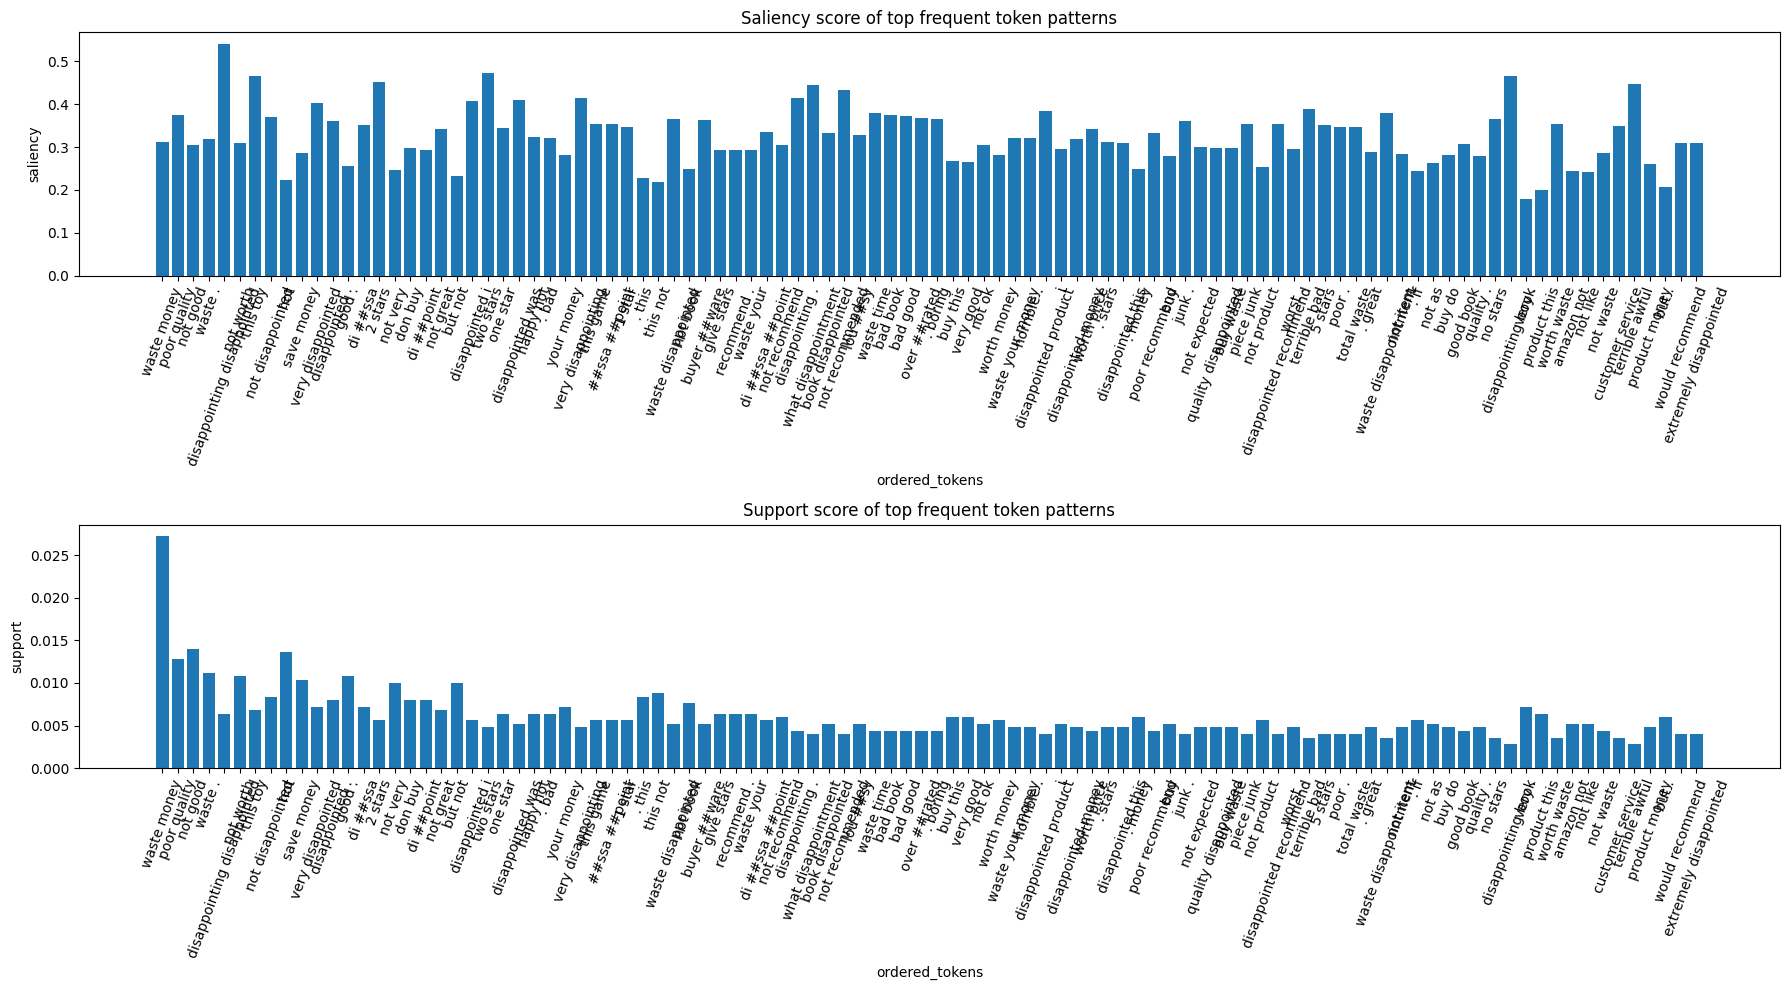

In [26]:
# convert token lists to readable strings
labels = two_grams["ordered_tokens"].apply(lambda x: " ".join(x))

fig, axes = plt.subplots(2, 1, figsize=(18,10))  # 2 rows, 1 column

# first plot
axes[0].bar(labels, two_grams["saliency_score"])
axes[0].set_xlabel("ordered_tokens")
axes[0].set_ylabel("saliency")
axes[0].set_title("Saliency score of top frequent token patterns")
axes[0].tick_params(axis="x", rotation=70)

# second plot (example)
axes[1].bar(labels, two_grams["support"])  # replace with your second data
axes[1].set_xlabel("ordered_tokens")
axes[1].set_ylabel("support")
axes[1].set_title("Support score of top frequent token patterns")
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

Function to extract hidden states for high support tokens.

In [27]:
@torch.no_grad()
def extract_itemset_hidden_states(
    model,
    tokenizer,
    itemsets_token_ids, # list of lists, e.g. [[101, 202], [55, 77, 88], ..]
    device,
    layers=(11, 12),
    context_mode="isolated",     # "isolated" vs "template"
    template_prefix="This product is",
    batch_size=32,
    num_labels=2,
):
    """
    Returns:
      out: dict layer_idx -> list[np.ndarray of shape (itemset_len, hidden_dim)]
      logits_out: np.ndarray [n_itemsets, num_labels]
    """

    model.eval()

    cls_id = tokenizer.cls_token_id
    sep_id = tokenizer.sep_token_id
    pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0

    if context_mode == "isolated":
        base_ids = []
        token_start = 1
    elif context_mode == "template":
        base_ids = tokenizer(template_prefix, add_special_tokens=False).input_ids
        token_start = 1 + len(base_ids)
    else:
        raise ValueError("context_mode must be 'isolated' or 'template'")

    out = {L: [] for L in layers}
    logits_out = []

    for start in range(0, len(itemsets_token_ids), batch_size):
        batch_itemsets = itemsets_token_ids[start:start + batch_size]

        input_ids_list = []
        token_ranges = []

        for ids in batch_itemsets:
            ids = [int(t) for t in ids]

            full_ids = [cls_id] + base_ids + ids + [sep_id]
            input_ids_list.append(full_ids)

            # positions of the itemset tokens inside the sequence
            token_ranges.append((token_start, token_start + len(ids)))

        max_len = max(len(x) for x in input_ids_list)

        padded_input_ids = []
        attention_masks = []
        token_type_ids = []

        for ids in input_ids_list:
            pad_len = max_len - len(ids)
            padded_input_ids.append(ids + [pad_id] * pad_len)
            attention_masks.append([1] * len(ids) + [0] * pad_len)
            token_type_ids.append([0] * max_len)

        input_ids = torch.tensor(padded_input_ids, dtype=torch.long, device=device)
        attention_mask = torch.tensor(attention_masks, dtype=torch.long, device=device)
        token_type_ids = torch.tensor(token_type_ids, dtype=torch.long, device=device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            output_hidden_states=True,
            return_dict=True,
        )

        if hasattr(outputs, "logits"):
            logits_out.append(outputs.logits.detach().cpu().numpy())
        else:
            bsz = input_ids.shape[0]
            logits_out.append(np.full((bsz, num_labels), np.nan, dtype=float))

        hs = outputs.hidden_states

        for b_idx, (s, e) in enumerate(token_ranges):
            for L in layers:
                vecs = hs[L][b_idx, s:e, :].detach().cpu().numpy()   # shape: [itemset_len, hidden_dim]
                out[L].append(vecs)

    logits_out = np.vstack(logits_out)

    return out, logits_out

Run Function for isolated tokens and for tokens within a template

In [28]:
layers = (5, 8, 11, 12)
itemset_ids = two_grams["ordered_ids"].tolist()

# Pretrained
pt_iso, pt_logits_iso = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
pt_tpl, pt_logits_tpl = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Finetuned
ft_iso, ft_logits_iso = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
ft_tpl, ft_logits_tpl = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

Add to dataframe

In [29]:
for L in layers:
    two_grams[f"pt_iso_l{L}"] = list(pt_iso[L])
    two_grams[f"pt_tpl_l{L}"] = list(pt_tpl[L])
    two_grams[f"ft_iso_l{L}"] = list(ft_iso[L])
    two_grams[f"ft_tpl_l{L}"] = list(ft_tpl[L])

Inspect consine/euclidean distance between mean embeddings l12 from pre trained and finetuned bert per itemset

In [30]:
import numpy as np

def pool(x):
    x = np.asarray(x)
    return x.mean(axis=0) if x.ndim == 2 else x

def cos_shift(pt, ft):
    a = pool(pt)
    b = pool(ft)
    cos = np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b))
    return 1 - cos

def euc_dist(pt, ft):
    a = pool(pt)
    b = pool(ft)
    return np.linalg.norm(a - b)

layers = (5, 8, 11, 12)

top = two_grams.sort_values("support", ascending=False).head(30).copy()

for L in layers:
    top[f"cos_shift_iso_l{L}"] = [
        cos_shift(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_iso_l{L}"], top[f"ft_iso_l{L}"])
    ]

    top[f"euc_iso_l{L}"] = [
        euc_dist(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_iso_l{L}"], top[f"ft_iso_l{L}"])
    ]

    top[f"cos_shift_tpl_l{L}"] = [
        cos_shift(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_tpl_l{L}"], top[f"ft_tpl_l{L}"])
    ]

    top[f"euc_tpl_l{L}"] = [
        euc_dist(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_tpl_l{L}"], top[f"ft_tpl_l{L}"])
    ]

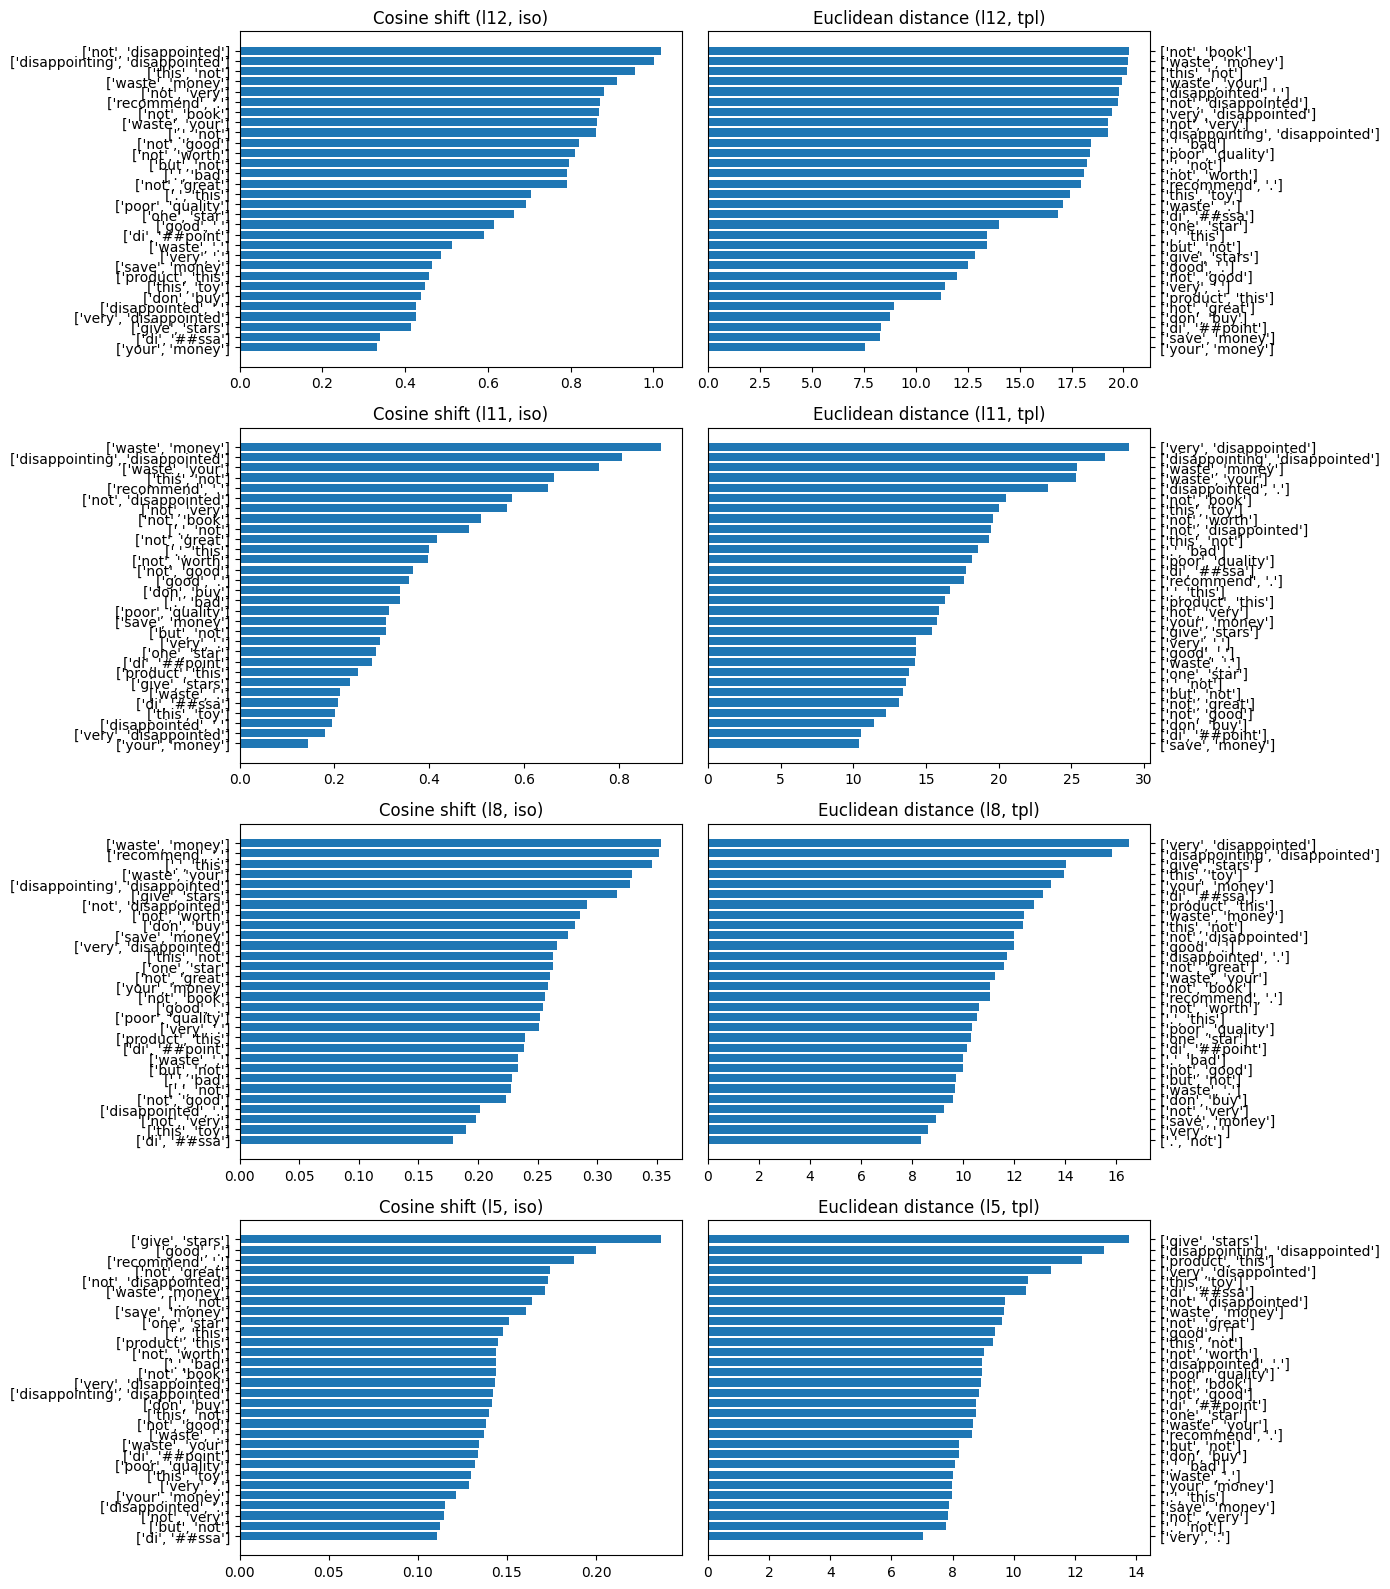

In [31]:
# Experiments

layers = (12,11,8,5)

fig, axes = plt.subplots(len(layers), 2, figsize=(14, 4 * len(layers)))
plt.subplots_adjust(wspace=0.6, hspace=0.4)

for i, L in enumerate(layers):
    # --- Cosine ---
    s1 = top.sort_values(f"cos_shift_iso_l{L}", ascending=False)
    axes[i, 0].barh(range(len(s1)), s1[f"cos_shift_iso_l{L}"])
    axes[i, 0].set_yticks(range(len(s1)))
    axes[i, 0].set_yticklabels(s1.ordered_tokens)
    axes[i, 0].set_title(f"Cosine shift (l{L}, iso)")
    axes[i, 0].invert_yaxis()

    # --- Euclidean ---
    s2 = top.sort_values(f"euc_tpl_l{L}", ascending=False)
    axes[i, 1].barh(range(len(s2)), s2[f"euc_tpl_l{L}"])
    axes[i, 1].set_yticks(range(len(s2)))
    axes[i, 1].set_yticklabels(s2.ordered_tokens)
    axes[i, 1].set_title(f"Euclidean distance (l{L}, tpl)")
    axes[i, 1].invert_yaxis()

    # move right labels outward to avoid overlap
    axes[i, 1].yaxis.tick_right()

plt.tight_layout()

## Experiment 2: Inspecting Hidden States: Layer 5,8,11 and 12

- Using freq_itemset with all tokens since we want a larger pool of tokens for neighbourhood analysis

In [32]:
freq_itemsets_neg_10

,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score
0,0.0456,(2919),1,[2919],[bad],0.377471,0.017213
1,0.0252,(8875),1,[8875],[item],0.299155,0.007539
2,0.0216,(2009),1,[2009],[it],0.215544,0.004656
3,0.0164,(3976),1,[3976],[price],0.281425,0.004615
4,0.0100,(5223),1,[5223],[hate],0.404166,0.004042
...,...,...,...,...,...,...,...
1672,0.0036,"(2732, 5790)",2,"[2732, 5790]","[star, rating]",0.291018,0.001048
1673,0.0020,"(6176, 2022)",2,"[2022, 6176]","[be, careful]",0.333542,0.000667
1674,0.0020,"(8400, 2098)",2,"[8400, 2098]","[##point, ##ed]",0.274357,0.000549
1675,0.0020,"(2098, 4487)",2,"[4487, 2098]","[di, ##ed]",0.295652,0.000591


In [33]:
neighbour_analysis_df = (
    freq_itemsets_neg_10[
        freq_itemsets_neg_10["length"] > 0
    ]
    .sort_values("score", ascending=False)
    .copy()
)

neighbour_analysis_df = add_amazon_candidate_group(
    neighbour_analysis_df
)

print(neighbour_analysis_df["candidate_group"].value_counts())


candidate_group
non_rating_proxy    1667
rating_proxy          10
Name: count, dtype: int64


Adding Hidden States

In [34]:
layers = (5, 8, 11, 12)
itemset_ids = neighbour_analysis_df["ordered_ids"].tolist()

# Pretrained
pt_iso, pt_logits_iso = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
pt_tpl, pt_logits_tpl = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Finetuned
ft_iso, ft_logits_iso = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
ft_tpl, ft_logits_tpl = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Assign pretrained
neighbour_analysis_df["pt_iso_l5"]  = list(pt_iso[5])
neighbour_analysis_df["pt_iso_l8"]  = list(pt_iso[8])
neighbour_analysis_df["pt_iso_l11"] = list(pt_iso[11])
neighbour_analysis_df["pt_iso_l12"] = list(pt_iso[12])

neighbour_analysis_df["pt_tpl_l5"]  = list(pt_tpl[5])
neighbour_analysis_df["pt_tpl_l8"]  = list(pt_tpl[8])
neighbour_analysis_df["pt_tpl_l11"] = list(pt_tpl[11])
neighbour_analysis_df["pt_tpl_l12"] = list(pt_tpl[12])

# Assign finetuned
neighbour_analysis_df["ft_iso_l5"]  = list(ft_iso[5])
neighbour_analysis_df["ft_iso_l8"]  = list(ft_iso[8])
neighbour_analysis_df["ft_iso_l11"] = list(ft_iso[11])
neighbour_analysis_df["ft_iso_l12"] = list(ft_iso[12])

neighbour_analysis_df["ft_tpl_l5"]  = list(ft_tpl[5])
neighbour_analysis_df["ft_tpl_l8"]  = list(ft_tpl[8])
neighbour_analysis_df["ft_tpl_l11"] = list(ft_tpl[11])
neighbour_analysis_df["ft_tpl_l12"] = list(ft_tpl[12])

# logits
neighbour_analysis_df["ft_iso_logits"] = list(ft_logits_iso)
neighbour_analysis_df["ft_tpl_logits"] = list(ft_logits_tpl)

In [35]:
neighbour_analysis_df.columns

Index(['support', 'itemsets', 'length', 'ordered_ids', 'ordered_tokens',
       'saliency_score', 'score', 'candidate_text', 'is_rating_proxy',
       'candidate_group', 'pt_iso_l5', 'pt_iso_l8', 'pt_iso_l11', 'pt_iso_l12',
       'pt_tpl_l5', 'pt_tpl_l8', 'pt_tpl_l11', 'pt_tpl_l12', 'ft_iso_l5',
       'ft_iso_l8', 'ft_iso_l11', 'ft_iso_l12', 'ft_tpl_l5', 'ft_tpl_l8',
       'ft_tpl_l11', 'ft_tpl_l12', 'ft_iso_logits', 'ft_tpl_logits'],
      dtype='object')

Building three dfs for nieghbourhood analysis of embeddings of itemsets:
- Inspecting mean of all tokens from one itemset
- Inspecting just the first embedding of an itemset
- Inspecting the sum of all tokens within an itemset

## Experiment 3: Neighbourhood analysis

Aggregating Embeddings

In [36]:
# embedding columns you want to transform
layers = (5, 8, 11, 12)
types = ("pt", "ft")
contexts = ("iso", "tpl")

embedding_cols = [
    f"{type}_{context}_l{layer}"
    for type in types
    for context in contexts
    for layer in layers
]

# base dataframe
base_cols = [
    "support",
    "length",
    "ordered_ids",
    "ordered_tokens",
    "saliency_score",
    "candidate_text",
    "is_rating_proxy",
    "candidate_group",
]

base_df = neighbour_analysis_df[base_cols + embedding_cols].copy()

def emb_mean(x):
    return np.asarray(x).mean(axis=0)

def emb_first(x):
    return np.asarray(x)[0]

def emb_sum(x):
    return np.asarray(x).sum(axis=0)

# build the 3 result dataframes
df_mean = base_df[base_cols].copy()
df_first_token = base_df[base_cols].copy()
df_sum = base_df[base_cols].copy()

for col in embedding_cols:
    df_mean[col] = base_df[col].apply(emb_mean)
    df_first_token[col] = base_df[col].apply(emb_first)
    df_sum[col] = base_df[col].apply(emb_sum)

# reset index
df_mean = df_mean.reset_index(drop=True)
df_first_token = df_first_token.reset_index(drop=True)
df_sum = df_sum.reset_index(drop=True)

print(df_mean.shape, df_first_token.shape, df_sum.shape)
display(df_mean.head(2))
display(df_first_token.head(2))
display(df_sum.head(2))

(1677, 24) (1677, 24) (1677, 24)


,support,length,ordered_ids,ordered_tokens,saliency_score,candidate_text,is_rating_proxy,candidate_group,pt_iso_l5,pt_iso_l8,...,pt_tpl_l11,pt_tpl_l12,ft_iso_l5,ft_iso_l8,ft_iso_l11,ft_iso_l12,ft_tpl_l5,ft_tpl_l8,ft_tpl_l11,ft_tpl_l12
0,0.0744,1,[9364],[disappointed],0.458752,disappointed,False,non_rating_proxy,"[-0.1826813, 0.2374939, -0.06888834, 0.3806782...","[-0.77209455, 0.11860047, -0.032110177, -0.058...",...,"[-0.046072446, -1.0667644, -0.016373545, 0.371...","[0.004002693, -0.569284, 0.005405586, 0.283987...","[-0.44017687, 0.5607819, -0.28423107, 0.980732...","[-0.055317152, 0.63437223, 0.29382157, 0.55973...","[0.37195748, 1.958805, -0.0070804134, -0.23275...","[0.5093752, 1.3455915, 0.039714485, 0.20315963...","[0.037557207, 0.33628327, -0.17972462, 0.86206...","[0.13518393, 0.18413052, -0.11241722, 0.703597...","[-0.039370105, 1.6436285, -0.066214964, -0.107...","[0.27879262, 1.3390548, -0.11513907, 0.2875701..."
1,0.1136,1,[1012],[.],0.239962,.,False,non_rating_proxy,"[-0.79162663, -0.94204515, 0.41654536, -2.0355...","[-1.4441208, -1.2644603, -0.30830377, -0.96419...",...,"[-0.9252442, -1.7991316, 0.41554183, -1.128865...","[-0.4517838, -1.4890721, 0.515166, -0.6619137,...","[-1.0706761, -0.59352493, 0.3856268, -1.574015...","[-1.3106508, -0.88326514, -0.25055343, -0.4187...","[-0.4742225, -0.2485435, -0.1963008, -0.332013...","[-0.11491864, -0.28689036, -0.3143331, -0.0494...","[-0.14804639, -0.63683534, 0.22737654, -0.2120...","[-0.70051116, -0.40998432, -0.27956256, -0.185...","[-0.36973143, -0.069800556, 0.51680195, -1.121...","[0.030917795, -0.34388816, 0.24318601, -0.5105..."


,support,length,ordered_ids,ordered_tokens,saliency_score,candidate_text,is_rating_proxy,candidate_group,pt_iso_l5,pt_iso_l8,...,pt_tpl_l11,pt_tpl_l12,ft_iso_l5,ft_iso_l8,ft_iso_l11,ft_iso_l12,ft_tpl_l5,ft_tpl_l8,ft_tpl_l11,ft_tpl_l12
0,0.0744,1,[9364],[disappointed],0.458752,disappointed,False,non_rating_proxy,"[-0.1826813, 0.2374939, -0.06888834, 0.3806782...","[-0.77209455, 0.11860047, -0.032110177, -0.058...",...,"[-0.046072446, -1.0667644, -0.016373545, 0.371...","[0.004002693, -0.569284, 0.005405586, 0.283987...","[-0.44017687, 0.5607819, -0.28423107, 0.980732...","[-0.055317152, 0.63437223, 0.29382157, 0.55973...","[0.37195748, 1.958805, -0.0070804134, -0.23275...","[0.5093752, 1.3455915, 0.039714485, 0.20315963...","[0.037557207, 0.33628327, -0.17972462, 0.86206...","[0.13518393, 0.18413052, -0.11241722, 0.703597...","[-0.039370105, 1.6436285, -0.066214964, -0.107...","[0.27879262, 1.3390548, -0.11513907, 0.2875701..."
1,0.1136,1,[1012],[.],0.239962,.,False,non_rating_proxy,"[-0.79162663, -0.94204515, 0.41654536, -2.0355...","[-1.4441208, -1.2644603, -0.30830377, -0.96419...",...,"[-0.9252442, -1.7991316, 0.41554183, -1.128865...","[-0.4517838, -1.4890721, 0.515166, -0.6619137,...","[-1.0706761, -0.59352493, 0.3856268, -1.574015...","[-1.3106508, -0.88326514, -0.25055343, -0.4187...","[-0.4742225, -0.2485435, -0.1963008, -0.332013...","[-0.11491864, -0.28689036, -0.3143331, -0.0494...","[-0.14804639, -0.63683534, 0.22737654, -0.2120...","[-0.70051116, -0.40998432, -0.27956256, -0.185...","[-0.36973143, -0.069800556, 0.51680195, -1.121...","[0.030917795, -0.34388816, 0.24318601, -0.5105..."


,support,length,ordered_ids,ordered_tokens,saliency_score,candidate_text,is_rating_proxy,candidate_group,pt_iso_l5,pt_iso_l8,...,pt_tpl_l11,pt_tpl_l12,ft_iso_l5,ft_iso_l8,ft_iso_l11,ft_iso_l12,ft_tpl_l5,ft_tpl_l8,ft_tpl_l11,ft_tpl_l12
0,0.0744,1,[9364],[disappointed],0.458752,disappointed,False,non_rating_proxy,"[-0.1826813, 0.2374939, -0.06888834, 0.3806782...","[-0.77209455, 0.11860047, -0.032110177, -0.058...",...,"[-0.046072446, -1.0667644, -0.016373545, 0.371...","[0.004002693, -0.569284, 0.005405586, 0.283987...","[-0.44017687, 0.5607819, -0.28423107, 0.980732...","[-0.055317152, 0.63437223, 0.29382157, 0.55973...","[0.37195748, 1.958805, -0.0070804134, -0.23275...","[0.5093752, 1.3455915, 0.039714485, 0.20315963...","[0.037557207, 0.33628327, -0.17972462, 0.86206...","[0.13518393, 0.18413052, -0.11241722, 0.703597...","[-0.039370105, 1.6436285, -0.066214964, -0.107...","[0.27879262, 1.3390548, -0.11513907, 0.2875701..."
1,0.1136,1,[1012],[.],0.239962,.,False,non_rating_proxy,"[-0.79162663, -0.94204515, 0.41654536, -2.0355...","[-1.4441208, -1.2644603, -0.30830377, -0.96419...",...,"[-0.9252442, -1.7991316, 0.41554183, -1.128865...","[-0.4517838, -1.4890721, 0.515166, -0.6619137,...","[-1.0706761, -0.59352493, 0.3856268, -1.574015...","[-1.3106508, -0.88326514, -0.25055343, -0.4187...","[-0.4742225, -0.2485435, -0.1963008, -0.332013...","[-0.11491864, -0.28689036, -0.3143331, -0.0494...","[-0.14804639, -0.63683534, 0.22737654, -0.2120...","[-0.70051116, -0.40998432, -0.27956256, -0.185...","[-0.36973143, -0.069800556, 0.51680195, -1.121...","[0.030917795, -0.34388816, 0.24318601, -0.5105..."


Extracting Hidden States for Each token: Layer12

In [37]:
# extract uniquq token ids
unique_token_ids = sorted(set(tok for ids in df_mean["ordered_ids"] for tok in ids))

#token to strings
id_to_token = {}
for ids, toks in zip(df_mean["ordered_ids"], df_mean["ordered_tokens"]):
    for i, t in zip(ids, toks):
        id_to_token[i] = t

token_df = pd.DataFrame({
    "token_id": unique_token_ids,
    "token": [id_to_token[i] for i in unique_token_ids]
})


In [38]:
import numpy as np
import torch

@torch.no_grad()
def extract_token_hidden_states(
    model,
    tokenizer,
    token_ids, # list[int]
    device,
    layers=(5, 8, 11, 12),
    context_mode="isolated",    # "isolated" or "template"
    template_prefix="This product is",
    batch_size=64,
):
    """
    Extract single-token embeddings from one BERT model.

    Modes
    -----
    isolated:
        [CLS] token [SEP]

    template:
        [CLS] template_prefix token [SEP]

    Returns
    -------
    dict: layer_idx -> np.ndarray of shape (n_tokens, hidden_dim)
    """
    model.eval()

    cls_id = tokenizer.cls_token_id
    sep_id = tokenizer.sep_token_id
    pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0

    if context_mode == "isolated":
        base_ids = []
        token_pos = 1
    elif context_mode == "template":
        base_ids = tokenizer(template_prefix, add_special_tokens=False).input_ids
        token_pos = 1 + len(base_ids)
    else:
        raise ValueError("context_mode must be 'isolated' or 'template'")

    all_vecs = {L: [] for L in layers}

    for start in range(0, len(token_ids), batch_size):
        batch_ids = [int(t) for t in token_ids[start:start + batch_size]]

        input_ids_list = []
        for tok_id in batch_ids:
            full_ids = [cls_id] + base_ids + [tok_id] + [sep_id]
            input_ids_list.append(full_ids)

        max_len = max(len(x) for x in input_ids_list)

        padded_input_ids = []
        attention_masks = []
        token_type_ids = []

        for ids in input_ids_list:
            pad_len = max_len - len(ids)
            padded_input_ids.append(ids + [pad_id] * pad_len)
            attention_masks.append([1] * len(ids) + [0] * pad_len)
            token_type_ids.append([0] * max_len)

        input_ids = torch.tensor(padded_input_ids, dtype=torch.long, device=device)
        attention_mask = torch.tensor(attention_masks, dtype=torch.long, device=device)
        token_type_ids = torch.tensor(token_type_ids, dtype=torch.long, device=device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            output_hidden_states=True,
            return_dict=True,
        )

        for L in layers:
            vecs = outputs.hidden_states[L][:, token_pos, :].detach().cpu().numpy()
            all_vecs[L].append(vecs)

    return {L: np.vstack(all_vecs[L]) for L in layers}

In [39]:
layers = (5, 8, 11, 12)

# extract isolated embeddings
pt_iso = extract_token_hidden_states(
    model=pt_bert,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="isolated",
)

ft_iso = extract_token_hidden_states(
    model=ft_bert,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="isolated",
)

# extract templated embeddings
pt_tpl = extract_token_hidden_states(
    model=pt_bert,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="template",
)

ft_tpl = extract_token_hidden_states(
    model=ft_bert,
    tokenizer=tokenizer,
    token_ids=unique_token_ids,
    device=device,
    layers=layers,
    batch_size=64,
    context_mode="template",
)

# store as vectors in the dataframe
for L in layers:
    token_df[f"pt_iso_l{L}"] = list(pt_iso[L])
    token_df[f"ft_iso_l{L}"] = list(ft_iso[L])
    token_df[f"pt_tpl_l{L}"] = list(pt_tpl[L])
    token_df[f"ft_tpl_l{L}"] = list(ft_tpl[L])

token_df.head()

,token_id,token,pt_iso_l5,ft_iso_l5,pt_tpl_l5,ft_tpl_l5,pt_iso_l8,ft_iso_l8,pt_tpl_l8,ft_tpl_l8,pt_iso_l11,ft_iso_l11,pt_tpl_l11,ft_tpl_l11,pt_iso_l12,ft_iso_l12,pt_tpl_l12,ft_tpl_l12
0,999,!,"[-0.23470674, -0.1345416, -0.077731356, -2.646...","[-0.06792148, 0.22946972, -0.1314379, -1.98335...","[0.08665541, -1.499254, -0.122550115, -0.80356...","[0.43229425, -0.5674268, 0.22562042, -1.194254...","[-1.0377996, -0.57245165, -0.7095441, -1.74455...","[-0.32827985, 0.7428576, 0.025512401, -1.36863...","[-0.94751376, -1.0492607, -0.4901259, -0.83101...","[-0.3438701, 0.101179525, 0.45665002, -1.26428...","[-0.6196404, -0.72565615, -0.61968935, -1.6692...","[-0.07617918, 0.7230491, 0.54365623, -0.913316...","[-0.55846757, -0.7679858, -0.4699626, -1.01488...","[-0.34063765, 0.07291889, 0.53920877, -1.43792...","[-0.094838455, -0.5202105, -0.41595998, -1.021...","[0.24517049, 0.38214436, 0.0362901, -0.3939349...","[-0.32980996, -0.66552407, -0.22017476, -0.467...","[0.101039544, -0.18828584, 0.3063779, -0.70684..."
1,1000,"""","[1.2429631, -1.2481024, -0.23129705, -0.641771...","[0.5642333, -0.7565645, -0.20887226, -0.591825...","[0.5184744, -0.9601257, -0.33347645, -0.768729...","[0.02175799, -0.8875982, -0.23115252, -0.45228...","[-0.05297234, -1.338232, -0.4574837, -0.369465...","[0.20910378, -1.0106205, -0.6196727, -0.150142...","[0.54802257, -1.4144481, -0.19534135, -0.43141...","[0.39702147, -1.1311015, -0.2175374, -0.287649...","[-0.15724362, -0.6428637, 0.5065164, -0.345313...","[-0.20621699, 0.33539656, 0.07674372, -0.19551...","[0.2512506, -0.46133724, 0.4051156, -0.1413501...","[-0.1194617, 0.16739672, 0.24967043, -0.222646...","[0.050145224, -0.37823233, 0.0599958, -0.17554...","[-0.021650663, -0.16280256, -0.16985373, -0.07...","[0.3323132, -0.20808569, 0.22264974, 0.2471953...","[-0.15844311, -0.24503838, 0.09151603, 0.00112..."
2,1002,$,"[0.065272555, 0.2948484, -0.5125689, -2.398924...","[0.027597122, -0.32579917, -0.33732742, -1.708...","[0.030496877, -0.32385325, -0.430602, -1.75128...","[0.17222174, -0.96149164, -0.35957527, -1.6286...","[0.3260262, 0.46927083, -0.51082325, -1.259506...","[0.35281184, 0.44141853, -0.81109816, -0.37826...","[0.54819226, 0.064879656, -0.30864245, -0.8742...","[0.83600646, -0.2230297, -0.9380039, -0.651706...","[0.09205604, 0.88826835, 0.19003688, -0.306689...","[0.08491142, 0.6949008, -0.35293126, 0.2579070...","[-0.21907812, 0.6958678, 0.45941758, -0.421277...","[0.45210224, 0.35750487, -0.065619975, -0.3350...","[0.19575068, 0.612972, 0.36604843, 0.4631329, ...","[0.03357511, 0.34257457, -0.098009214, 0.26318...","[-0.037583627, 0.4347943, 0.65860415, -0.02905...","[0.09315777, 0.13693048, 0.013612827, -0.03830..."
3,1003,%,"[0.41259328, -1.062628, -0.160108, -1.1427197,...","[0.20687611, -1.6006296, -0.7923458, -1.060275...","[0.62880445, -1.4897463, -0.12791127, -0.81832...","[0.8001651, -1.6270343, 0.0134461075, -0.57531...","[-1.1856098, -1.3061627, -0.39761013, -1.00159...","[-1.0214685, -1.1761596, -0.16017097, -0.71840...","[0.0653469, -1.9644562, 0.01654192, 0.13555571...","[0.48266304, -1.0895135, -0.21796143, -0.05696...","[-1.4432852, -0.9041133, 0.06078136, -0.507961...","[-1.0554513, -0.7149655, 0.13376026, 0.5618988...","[-0.54391277, -0.60519093, 0.6594909, 0.325801...","[-0.22081475, -0.44237697, 0.16874175, 0.28726...","[-1.2774396, -0.37226146, 0.3230244, -0.115701...","[-0.5683183, -0.4849429, 0.1015801, 0.38180214...","[-0.28096625, -0.16181651, 0.85556656, 0.23969...","[-0.16391629, -0.2716119, 0.049506422, 0.21228..."
4,1005,',"[0.1911915, -0.8419162, -0.11475133, -1.143343...","[-0.62497616, -1.01854, 0.082321346, -0.965011...","[-0.15673475, -0.6525258, 0.33064052, -0.20719...","[-0.7159605, -1.2113359, 0.47112876, 0.0279322...","[-1.0136603, -1.2840776, 0.624036, -0.542977, ...","[-0.88947994, -1.4959327, 0.16279674, -0.29970...","[-0.25799015, -1.1393197, 0.40828753, 0.367054...","[-0.67784506, -1.6097704, 0.4753083, -0.142236...","[-0.27395946, -0.5431775

# Find the nearest neighbour of an itemset

In [40]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

def stack_embs(series):
    return np.vstack(series.apply(np.asarray).to_list())

def add_nearest_neighbors(
    query_df,
    token_df,
    query_emb_col,
    token_emb_col,
    prefix,
    k=30, ##### <- ##################################################
    metric="cosine",   # "cosine" or "euclidean"
    exclude_constituents=False,
    drop_embedding_cols=False,
    embedding_cols_to_drop=None,
):
    q_mat = stack_embs(query_df[query_emb_col])
    t_mat = stack_embs(token_df[token_emb_col])

    if metric == "cosine":
        scores = cosine_similarity(q_mat, t_mat)
        larger_is_better = True
        score_col = f"{prefix}_nn_cosines"
    elif metric == "euclidean":
        scores = euclidean_distances(q_mat, t_mat)
        larger_is_better = False
        score_col = f"{prefix}_nn_euclidean"
    else:
        raise ValueError("metric must be 'cosine' or 'euclidean'")

    token_ids = token_df["token_id"].values
    token_strs = token_df["token"].values

    nn_token_ids = []
    nn_tokens = []
    nn_scores = []

    for i in range(len(query_df)):
        row = scores[i].copy()

        if exclude_constituents:
            itemset_ids = query_df.iloc[i]["ordered_ids"]
            if larger_is_better:
                row[np.isin(token_ids, list(itemset_ids))] = -np.inf
            else:
                row[np.isin(token_ids, list(itemset_ids))] = np.inf

        top_idx = np.argsort(row)[::-1][:k] if larger_is_better else np.argsort(row)[:k]

        nn_token_ids.append(token_ids[top_idx].tolist())
        nn_tokens.append(token_strs[top_idx].tolist())
        nn_scores.append(row[top_idx].tolist())

    out = query_df.copy()
    out[f"{prefix}_nn_token_ids"] = nn_token_ids
    out[f"{prefix}_nn_tokens"] = nn_tokens
    out[score_col] = nn_scores
    out[f"{prefix}_nn_metric"] = metric

    if drop_embedding_cols:
        if embedding_cols_to_drop is None:
            embedding_cols_to_drop = [c for c in out.columns if "_l" in c]
        cols_to_drop = [c for c in embedding_cols_to_drop if c in out.columns]
        out = out.drop(columns=cols_to_drop)

    return out

In [41]:
from sklearn.metrics.pairwise import euclidean_distances

def add_euclidean_distances(
    df_with_nns,
    query_df,
    token_df,
    query_emb_col,
    token_emb_col,
    nn_ids_col,
    out_col,
):
    out = df_with_nns.copy()

    q_lookup = {
        tuple(row["ordered_ids"]): np.asarray(row[query_emb_col])
        for _, row in query_df.iterrows()
    }
    t_lookup = {
        row["token_id"]: np.asarray(row[token_emb_col])
        for _, row in token_df.iterrows()
    }

    all_dists = []

    for _, row in out.iterrows():
        q_vec = q_lookup[tuple(row["ordered_ids"])].reshape(1, -1)
        dists = []

        for tok_id in row[nn_ids_col]:
            t_vec = t_lookup[tok_id].reshape(1, -1)
            dists.append(euclidean_distances(q_vec, t_vec)[0, 0])

        all_dists.append(dists)

    out[out_col] = all_dists
    return out

def add_cosine_values(
    df_with_nns,
    query_df,
    token_df,
    query_emb_col,
    token_emb_col,
    nn_ids_col,
    out_col,
    as_distance=False,
):
    out = df_with_nns.copy()

    q_lookup = {
        tuple(row["ordered_ids"]): np.asarray(row[query_emb_col])
        for _, row in query_df.iterrows()
    }
    t_lookup = {
        row["token_id"]: np.asarray(row[token_emb_col])
        for _, row in token_df.iterrows()
    }

    all_vals = []

    for _, row in out.iterrows():
        q_vec = q_lookup[tuple(row["ordered_ids"])].reshape(1, -1)
        vals = []

        for tok_id in row[nn_ids_col]:
            t_vec = t_lookup[tok_id].reshape(1, -1)
            cos_sim = cosine_similarity(q_vec, t_vec)[0, 0]
            vals.append(1 - cos_sim if as_distance else cos_sim)

        all_vals.append(vals)

    out[out_col] = all_vals
    return out

In [42]:
import numpy as np

def add_distance_deltas(
    df,
    ft_euclidean_col,
    pt_euclidean_col,
    ft_cosine_col,
    pt_cosine_col,
    out_ft_cosine_distance_col,
    out_delta_euclidean_col,
    out_delta_cosine_col,
    out_mean_delta_euclidean_col=None,
    out_mean_delta_cosine_col=None,
    ft_cosine_is_similarity=True,
):
    out = df.copy()

    if ft_cosine_is_similarity:
        out[out_ft_cosine_distance_col] = out[ft_cosine_col].apply(
            lambda xs: [1 - x for x in xs]
        )
        ft_cosine_distance_col = out_ft_cosine_distance_col
    else:
        ft_cosine_distance_col = ft_cosine_col

    out[out_delta_euclidean_col] = [
        np.abs(np.array(pt) - np.array(ft)).tolist()
        for ft, pt in zip(out[ft_euclidean_col], out[pt_euclidean_col])
    ]

    out[out_delta_cosine_col] = [
        np.abs(np.array(pt) - np.array(ft)).tolist()
        for ft, pt in zip(out[ft_cosine_distance_col], out[pt_cosine_col])
    ]

    if out_mean_delta_euclidean_col is not None:
        out[out_mean_delta_euclidean_col] = out[out_delta_euclidean_col].apply(np.mean)

    if out_mean_delta_cosine_col is not None:
        out[out_mean_delta_cosine_col] = out[out_delta_cosine_col].apply(np.mean)

    return out

### Anchor-analysis helper functions

The following functions select nearest neighbours at an anchor layer and compare their pretrained and fine-tuned representation distances across layers.


In [43]:
LAYERS = (12, 11, 8, 5)
ALL_NN_LAYERS = (5, 8, 11, 12)


def _embedding_column(model_type, context, layer):
    """
    Return the embedding-column name used in df_mean and token_df.

    Examples:
        ft_iso_l12
        pt_tpl_l8
    """
    if model_type not in {"ft", "pt"}:
        raise ValueError("model_type must be 'ft' or 'pt'")
    if context not in {"iso", "tpl"}:
        raise ValueError("context must be 'iso' or 'tpl'")

    return f"{model_type}_{context}_l{layer}"


def run_anchor_analysis(
    df_mean,
    token_df,
    anchor_layer,
    context="iso",
    k=30,
):
    """
    Run nearest-neighbour and cross-layer distance analysis.

    The nearest neighbours are selected in the fine-tuned embedding
    space of `anchor_layer`. Distances to those same neighbours are
    then measured in the fine-tuned and pretrained models at all
    analyzed layers.

    Parameters
    ----------
    df_mean:
        Candidate dataframe containing pooled itemset embeddings.

    token_df:
        Token dataframe containing individual-token embeddings.

    anchor_layer:
        Layer in which the nearest neighbours are selected.

    context:
        "iso" for isolated candidates or "tpl" for templated candidates.

    k:
        Number of nearest neighbours per candidate.
    """
    if context not in {"iso", "tpl"}:
        raise ValueError("context must be 'iso' or 'tpl'")

    if anchor_layer not in ALL_NN_LAYERS:
        raise ValueError(
            f"anchor_layer must be one of {ALL_NN_LAYERS}"
        )

    if k < 1:
        raise ValueError("k must be at least 1")

    out = df_mean.copy()

    required_candidate_columns = {
        "ordered_ids",
        *{
            _embedding_column(model_type, context, layer)
            for model_type in ("ft", "pt")
            for layer in ALL_NN_LAYERS
        },
    }
    required_token_columns = {
        "token_id",
        "token",
        *{
            _embedding_column(model_type, context, layer)
            for model_type in ("ft", "pt")
            for layer in ALL_NN_LAYERS
        },
    }

    missing_candidate_columns = sorted(
        required_candidate_columns - set(out.columns)
    )
    missing_token_columns = sorted(
        required_token_columns - set(token_df.columns)
    )

    if missing_candidate_columns:
        raise KeyError(
            "df_mean is missing required columns: "
            + ", ".join(missing_candidate_columns)
        )

    if missing_token_columns:
        raise KeyError(
            "token_df is missing required columns: "
            + ", ".join(missing_token_columns)
        )

    # 1. Find nearest neighbours at every fine-tuned layer.
    for layer in ALL_NN_LAYERS:
        ft_embedding_col = _embedding_column(
            "ft",
            context,
            layer,
        )
        prefix = f"ft_{context}_l{layer}"

        out = add_nearest_neighbors(
            query_df=out,
            token_df=token_df,
            query_emb_col=ft_embedding_col,
            token_emb_col=ft_embedding_col,
            prefix=prefix,
            k=k,
            exclude_constituents=True,
        )

    anchor_prefix = f"ft_{context}_l{anchor_layer}"
    pretrained_anchor_prefix = f"pt_{context}_l{anchor_layer}"
    nn_ids_col = f"{anchor_prefix}_nn_token_ids"

    # 2. Measure distances to the anchor-layer neighbours at all layers.
    for layer in LAYERS:
        ft_embedding_col = _embedding_column(
            "ft",
            context,
            layer,
        )
        pt_embedding_col = _embedding_column(
            "pt",
            context,
            layer,
        )

        out = add_euclidean_distances(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=ft_embedding_col,
            token_emb_col=ft_embedding_col,
            nn_ids_col=nn_ids_col,
            out_col=(
                f"{anchor_prefix}_nns_euclidean_l{layer}"
            ),
        )

        out = add_cosine_values(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=ft_embedding_col,
            token_emb_col=ft_embedding_col,
            nn_ids_col=nn_ids_col,
            out_col=f"{anchor_prefix}_nns_cosine_l{layer}",
            as_distance=False,
        )

        out = add_euclidean_distances(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=pt_embedding_col,
            token_emb_col=pt_embedding_col,
            nn_ids_col=nn_ids_col,
            out_col=(
                f"{pretrained_anchor_prefix}"
                f"_same_nns_euclidean_l{layer}"
            ),
        )

        out = add_cosine_values(
            df_with_nns=out,
            query_df=out,
            token_df=token_df,
            query_emb_col=pt_embedding_col,
            token_emb_col=pt_embedding_col,
            nn_ids_col=nn_ids_col,
            out_col=(
                f"{pretrained_anchor_prefix}"
                f"_same_nns_cosdist_l{layer}"
            ),
            as_distance=True,
        )

    # 3. Calculate absolute fine-tuned/pretrained distance changes.
    for layer in LAYERS:
        if context == "iso":
            output_prefix = f"l{anchor_layer}"
        else:
            output_prefix = f"tpl_l{anchor_layer}"

        out = add_distance_deltas(
            df=out,
            ft_euclidean_col=(
                f"{anchor_prefix}_nns_euclidean_l{layer}"
            ),
            pt_euclidean_col=(
                f"{pretrained_anchor_prefix}"
                f"_same_nns_euclidean_l{layer}"
            ),
            ft_cosine_col=(
                f"{anchor_prefix}_nns_cosine_l{layer}"
            ),
            pt_cosine_col=(
                f"{pretrained_anchor_prefix}"
                f"_same_nns_cosdist_l{layer}"
            ),
            out_ft_cosine_distance_col=(
                f"{anchor_prefix}_nns_cosdist_l{layer}"
            ),
            out_delta_euclidean_col=(
                f"delta_{output_prefix}_euclidean_l{layer}"
            ),
            out_delta_cosine_col=(
                f"delta_{output_prefix}_cosine_l{layer}"
            ),
            out_mean_delta_euclidean_col=(
                f"mean_delta_{output_prefix}_euclidean_l{layer}"
            ),
            out_mean_delta_cosine_col=(
                f"mean_delta_{output_prefix}_cosine_l{layer}"
            ),
            ft_cosine_is_similarity=True,
        )

    return out


def plot_anchor_overlay(
    df,
    anchor_layer,
    context="iso",
    top_n=50,
    min_length=2,
    sort_col="support",
):
    """
    Plot mean representation-distance changes across BERT layers.
    """
    if context not in {"iso", "tpl"}:
        raise ValueError("context must be 'iso' or 'tpl'")

    if anchor_layer not in ALL_NN_LAYERS:
        raise ValueError(
            f"anchor_layer must be one of {ALL_NN_LAYERS}"
        )

    if context == "iso":
        output_prefix = f"l{anchor_layer}"
        title_context = "isolated"
    else:
        output_prefix = f"tpl_l{anchor_layer}"
        title_context = "templated"

    euclidean_columns = {
        layer:
        f"mean_delta_{output_prefix}_euclidean_l{layer}"
        for layer in LAYERS
    }
    cosine_columns = {
        layer:
        f"mean_delta_{output_prefix}_cosine_l{layer}"
        for layer in LAYERS
    }

    required_columns = {
        "length",
        "ordered_tokens",
        sort_col,
        *euclidean_columns.values(),
        *cosine_columns.values(),
    }
    missing_columns = sorted(required_columns - set(df.columns))

    if missing_columns:
        raise KeyError(
            "The analysis dataframe is missing required columns: "
            + ", ".join(missing_columns)
        )

    plot_df = (
        df[df["length"] >= min_length]
        .sort_values(sort_col, ascending=False)
        .head(top_n)
        .copy()
    )

    if plot_df.empty:
        print("No candidates satisfy the plotting filters.")
        return

    plot_df["label"] = plot_df["ordered_tokens"].apply(
        lambda tokens: (
            " ".join(tokens)
            if isinstance(tokens, (list, tuple))
            else str(tokens)
        )
    )

    x = np.arange(len(plot_df))
    width = 0.2
    title_prefix = (
        f"Layer-{anchor_layer} anchor, {title_context}"
    )

    plt.figure(figsize=(20, 6))

    for index, layer in enumerate(LAYERS):
        plt.bar(
            x + index * width,
            plot_df[euclidean_columns[layer]],
            width,
            label=f"L{layer}",
        )

    plt.xticks(
        x + width * (len(LAYERS) - 1) / 2,
        plot_df["label"],
        rotation=75,
        ha="right",
    )
    plt.ylabel("Mean absolute Euclidean-distance change")
    plt.title(
        f"{title_prefix}: Euclidean change across layers"
    )
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(20, 6))

    for index, layer in enumerate(LAYERS):
        plt.bar(
            x + index * width,
            plot_df[cosine_columns[layer]],
            width,
            label=f"L{layer}",
        )

    plt.xticks(
        x + width * (len(LAYERS) - 1) / 2,
        plot_df["label"],
        rotation=75,
        ha="right",
    )
    plt.ylabel("Mean absolute cosine-distance change")
    plt.title(
        f"{title_prefix}: Cosine change across layers"
    )
    plt.legend()
    plt.tight_layout()
    plt.show()


In [44]:
def plot_rating_proxy_vs_non_rating_proxy(
    df,
    anchor_layer,
    context="iso",
):
    """
    Compare explicit Amazon rating proxies with all other candidates.
    """
    assert context in {"iso", "tpl"}

    df_plot = add_amazon_candidate_group(df)

    df_rating = df_plot[
        df_plot["candidate_group"] == "rating_proxy"
    ]
    df_non_rating = df_plot[
        df_plot["candidate_group"] == "non_rating_proxy"
    ]

    print(
        f"Layer {anchor_layer}, {context}: "
        f"{len(df_rating)} rating proxies and "
        f"{len(df_non_rating)} non-rating proxies"
    )

    if context == "iso":
        euc_name = (
            lambda layer:
            f"mean_delta_l{anchor_layer}_euclidean_l{layer}"
        )
        cos_name = (
            lambda layer:
            f"mean_delta_l{anchor_layer}_cosine_l{layer}"
        )
        title_prefix = (
            f"Layer-{anchor_layer} anchor, isolated"
        )
    else:
        euc_name = (
            lambda layer:
            f"mean_delta_tpl_l{anchor_layer}_euclidean_l{layer}"
        )
        cos_name = (
            lambda layer:
            f"mean_delta_tpl_l{anchor_layer}_cosine_l{layer}"
        )
        title_prefix = (
            f"Layer-{anchor_layer} anchor, templated"
        )

    summary_rows = []

    for layer in LAYERS:
        for group_name, group_df in (
            ("rating_proxy", df_rating),
            ("non_rating_proxy", df_non_rating),
        ):
            summary_rows.append({
                "group": group_name,
                "count": len(group_df),
                "layer": f"L{layer}",
                "mean_delta_euclidean": (
                    group_df[euc_name(layer)].mean()
                ),
                "std_delta_euclidean": (
                    group_df[euc_name(layer)].std()
                ),
                "mean_delta_cosine": (
                    group_df[cos_name(layer)].mean()
                ),
                "std_delta_cosine": (
                    group_df[cos_name(layer)].std()
                ),
            })

    summary = pd.DataFrame(summary_rows)

    x = np.arange(len(LAYERS))
    width = 0.35

    rating = summary[
        summary["group"] == "rating_proxy"
    ]
    non_rating = summary[
        summary["group"] == "non_rating_proxy"
    ]

    rating_euc_std = np.nan_to_num(
        rating["std_delta_euclidean"].to_numpy(),
        nan=0.0,
    )
    non_rating_euc_std = np.nan_to_num(
        non_rating["std_delta_euclidean"].to_numpy(),
        nan=0.0,
    )
    rating_cos_std = np.nan_to_num(
        rating["std_delta_cosine"].to_numpy(),
        nan=0.0,
    )
    non_rating_cos_std = np.nan_to_num(
        non_rating["std_delta_cosine"].to_numpy(),
        nan=0.0,
    )

    # Euclidean comparison
    plt.figure(figsize=(8, 5))

    plt.bar(
        x - width / 2,
        rating["mean_delta_euclidean"].to_numpy(),
        width,
        yerr=rating_euc_std,
        label="explicit rating proxy",
        capsize=4,
    )
    plt.bar(
        x + width / 2,
        non_rating["mean_delta_euclidean"].to_numpy(),
        width,
        yerr=non_rating_euc_std,
        label="non-rating proxy",
        capsize=4,
    )

    plt.xticks(x, [f"L{layer}" for layer in LAYERS])
    plt.ylabel("average mean delta euclidean")
    plt.title(
        f"{title_prefix}: rating proxy vs non-rating proxy"
    )
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Cosine comparison
    plt.figure(figsize=(8, 5))

    plt.bar(
        x - width / 2,
        rating["mean_delta_cosine"].to_numpy(),
        width,
        yerr=rating_cos_std,
        label="explicit rating proxy",
        capsize=4,
    )
    plt.bar(
        x + width / 2,
        non_rating["mean_delta_cosine"].to_numpy(),
        width,
        yerr=non_rating_cos_std,
        label="non-rating proxy",
        capsize=4,
    )

    plt.xticks(x, [f"L{layer}" for layer in LAYERS])
    plt.ylabel("average mean delta cosine")
    plt.title(
        f"{title_prefix}: rating proxy vs non-rating proxy"
    )
    plt.legend()
    plt.tight_layout()
    plt.show()

    return summary


### Anchor layer 12

### Top 10 Nearest Neighbours

Calculated in finetuned embedding space

Isolated

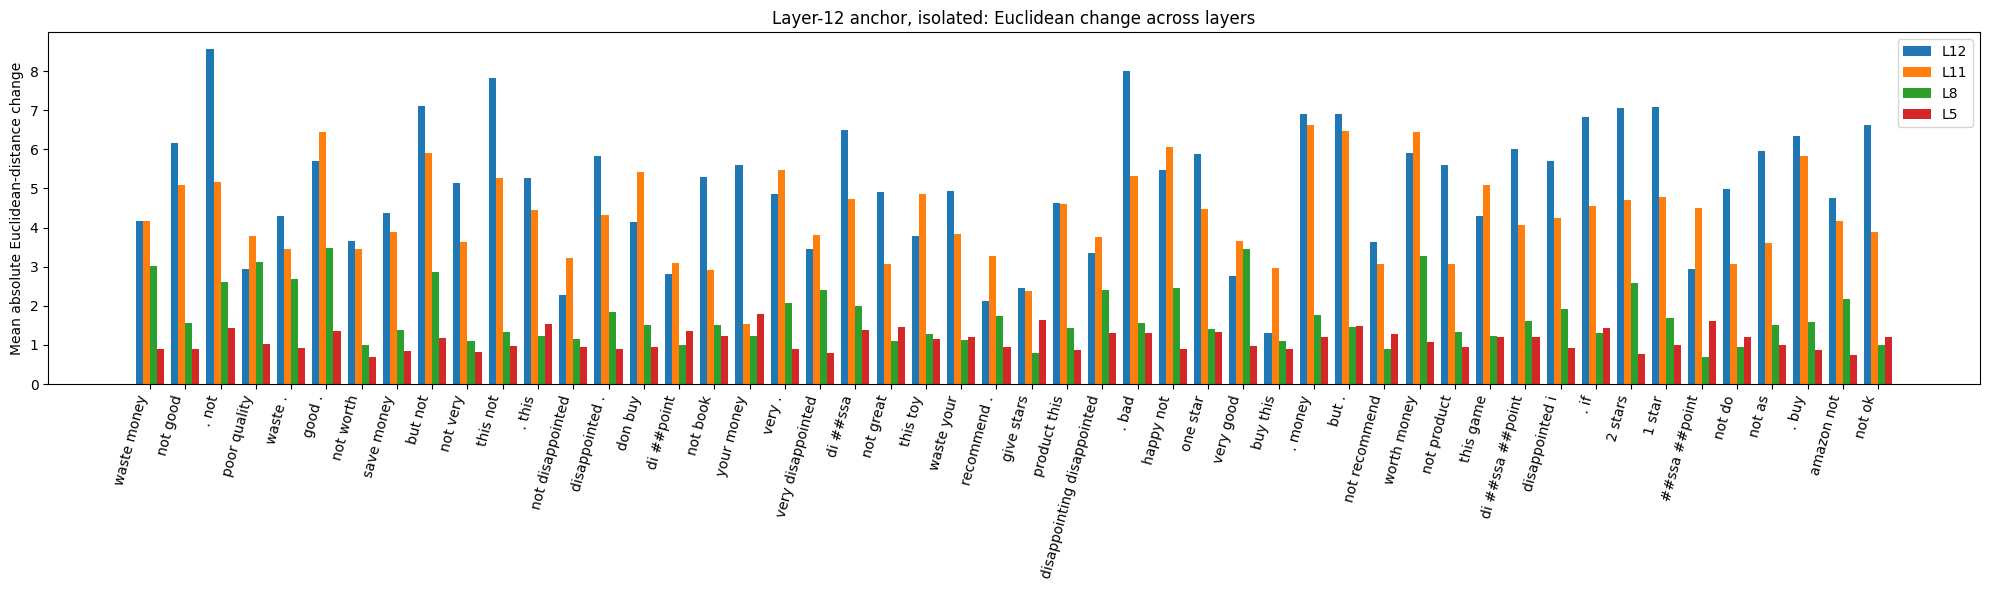

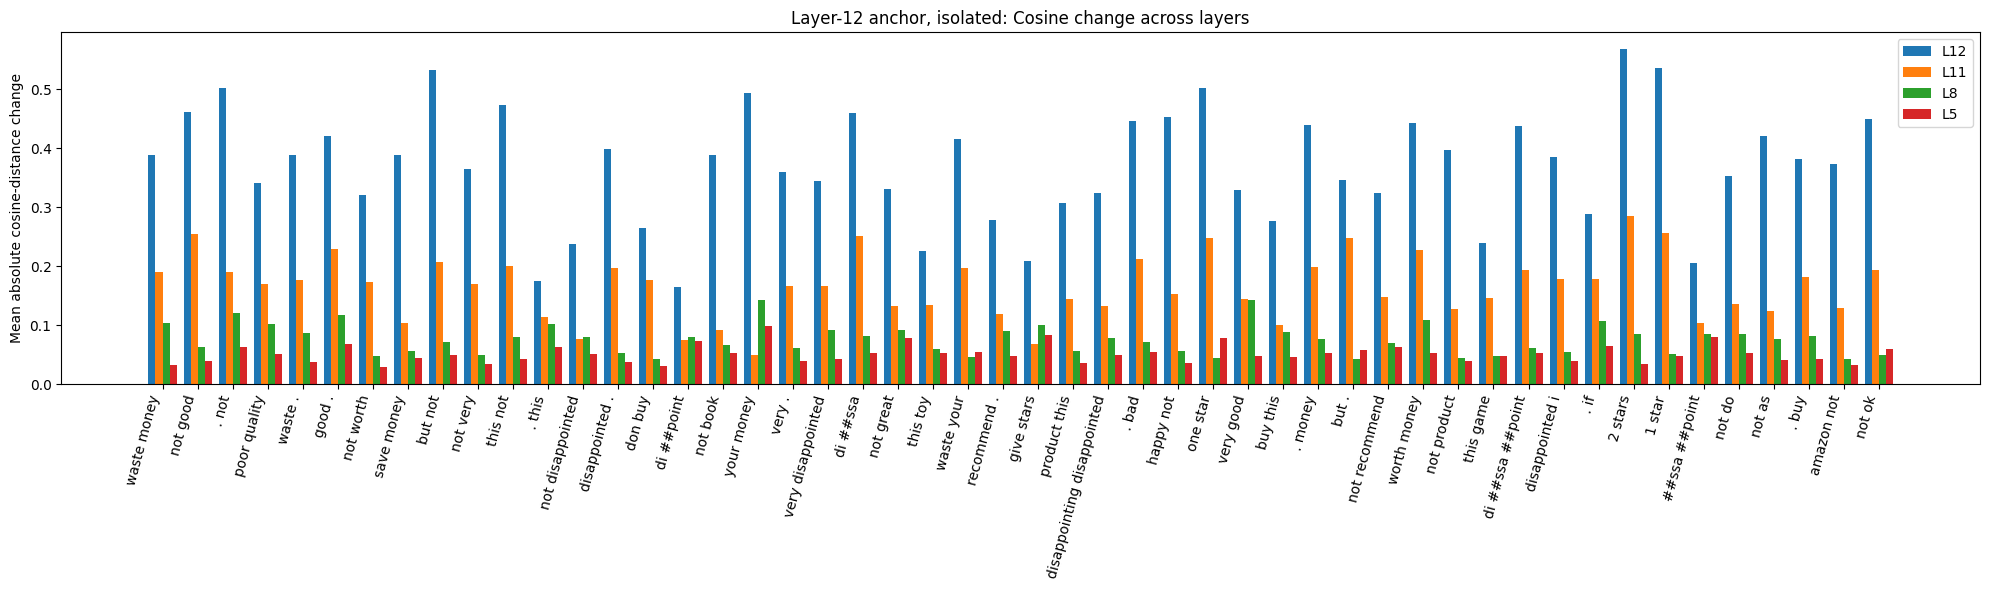

Layer 12, iso: 10 rating proxies and 1667 non-rating proxies


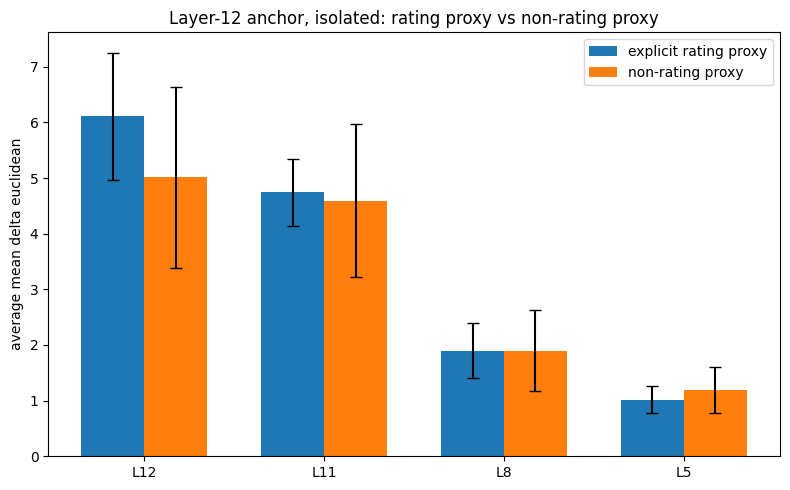

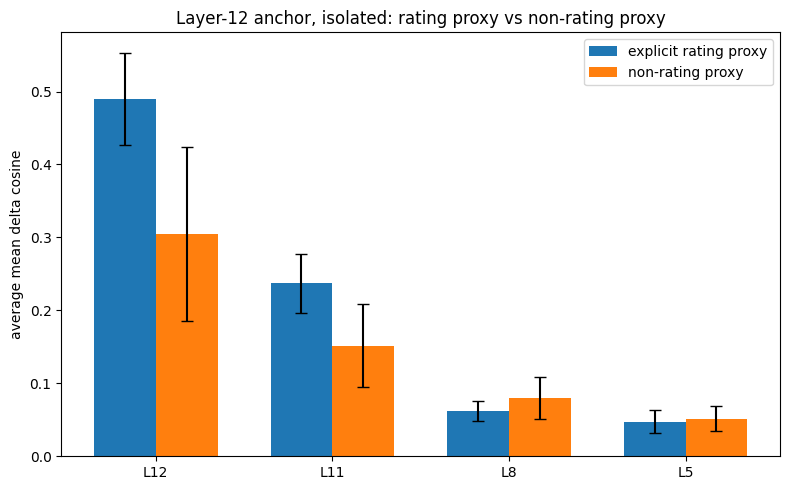

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,rating_proxy,10,L12,6.106733,1.148717,0.490359,0.063134
1,non_rating_proxy,1667,L12,5.015241,1.628504,0.304312,0.119372
2,rating_proxy,10,L11,4.745858,0.599181,0.236913,0.039888
3,non_rating_proxy,1667,L11,4.589399,1.375266,0.151544,0.056636
4,rating_proxy,10,L8,1.899793,0.488389,0.062436,0.013974
5,non_rating_proxy,1667,L8,1.896382,0.726989,0.079878,0.028145
6,rating_proxy,10,L5,1.015616,0.246779,0.047237,0.015566
7,non_rating_proxy,1667,L5,1.191551,0.416964,0.051630,0.017434


In [45]:
df_iso_l12 = run_anchor_analysis(df_mean, token_df, anchor_layer=12, context="iso")
plot_anchor_overlay(df_iso_l12, anchor_layer=12, context="iso")
plot_rating_proxy_vs_non_rating_proxy(df_iso_l12, anchor_layer=12, context="iso")

Templated

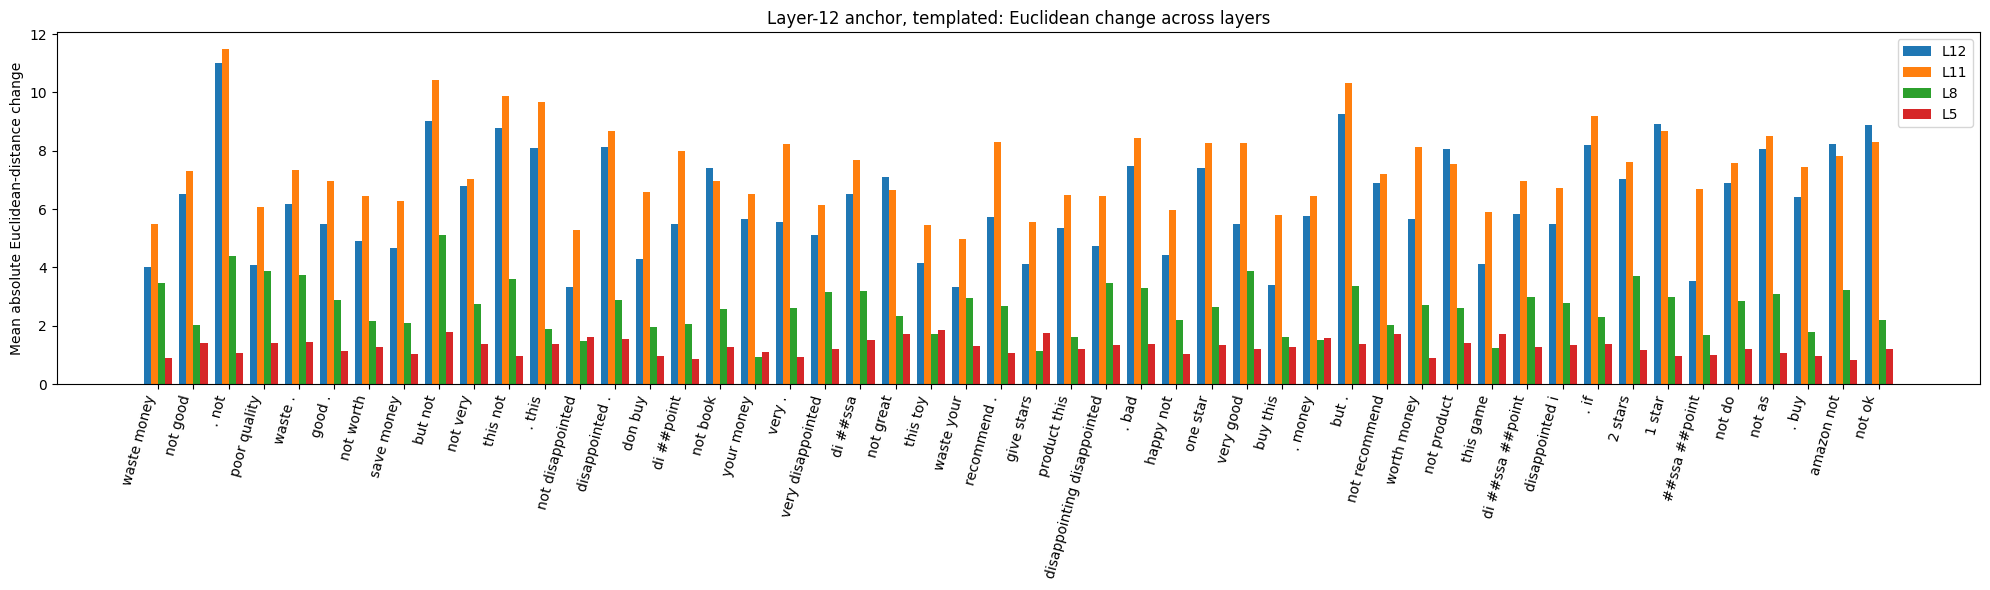

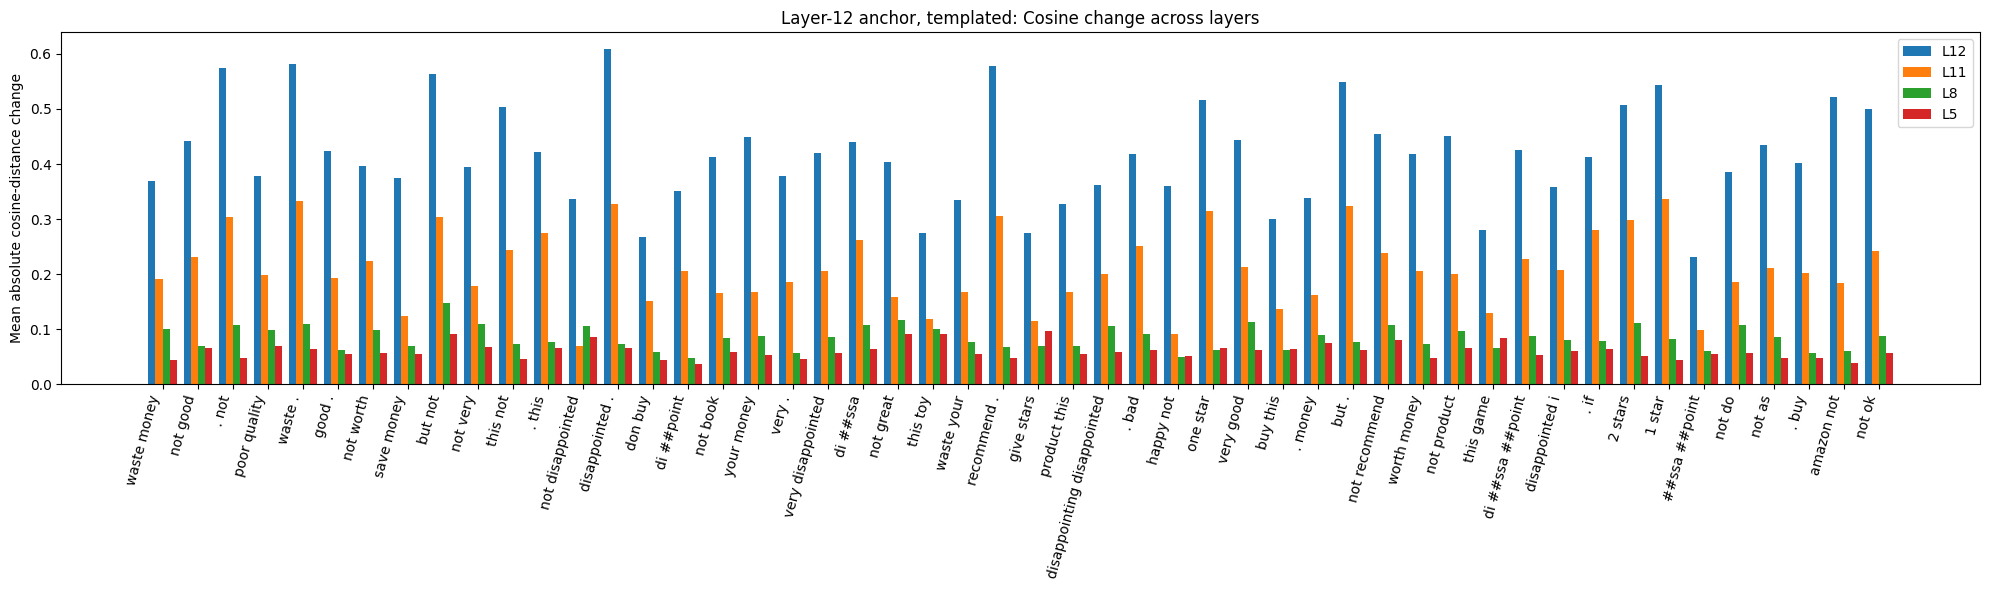

Layer 12, tpl: 10 rating proxies and 1667 non-rating proxies


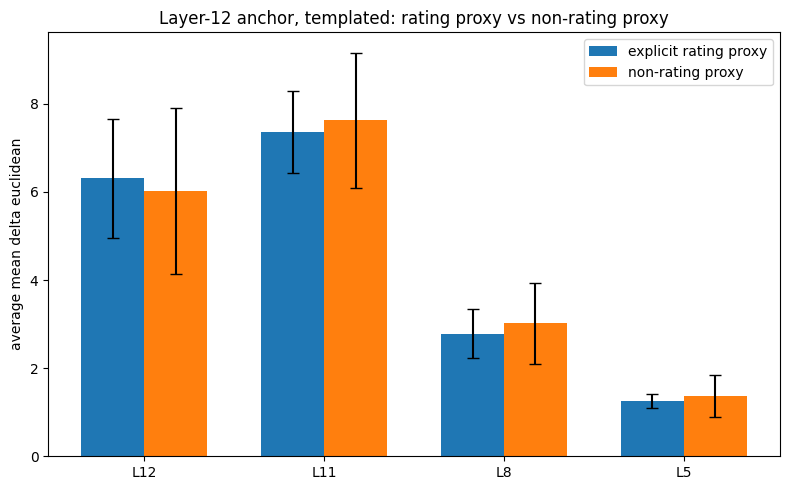

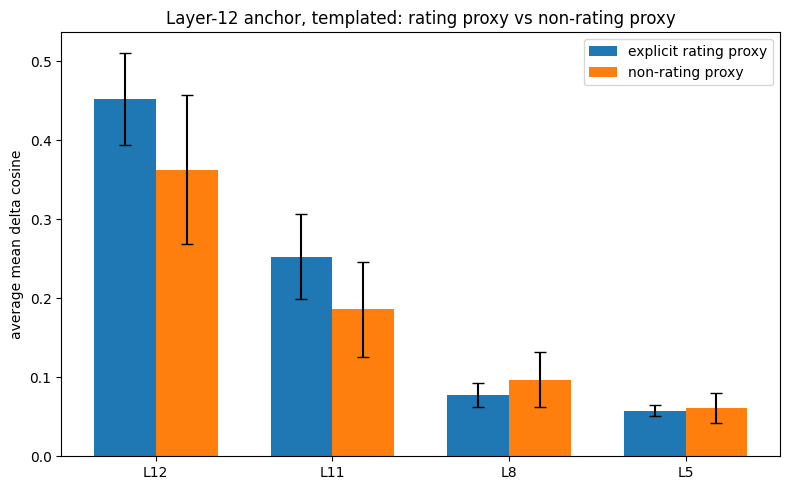

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,rating_proxy,10,L12,6.306912,1.348367,0.452487,0.058353
1,non_rating_proxy,1667,L12,6.018753,1.875821,0.362521,0.094490
2,rating_proxy,10,L11,7.362094,0.924201,0.252455,0.053821
3,non_rating_proxy,1667,L11,7.626747,1.537731,0.185806,0.060195
4,rating_proxy,10,L8,2.777345,0.555760,0.077184,0.015469
5,non_rating_proxy,1667,L8,3.016713,0.920186,0.096962,0.034602
6,rating_proxy,10,L5,1.259192,0.156999,0.057763,0.006884
7,non_rating_proxy,1667,L5,1.365951,0.473713,0.061058,0.019449


In [46]:
df_tpl_l12 = run_anchor_analysis(df_mean, token_df, anchor_layer=12, context="tpl")
plot_anchor_overlay(df_tpl_l12, anchor_layer=12, context="tpl")
plot_rating_proxy_vs_non_rating_proxy(df_tpl_l12, anchor_layer=12, context="tpl")

### Anchor layer 11

Isolated

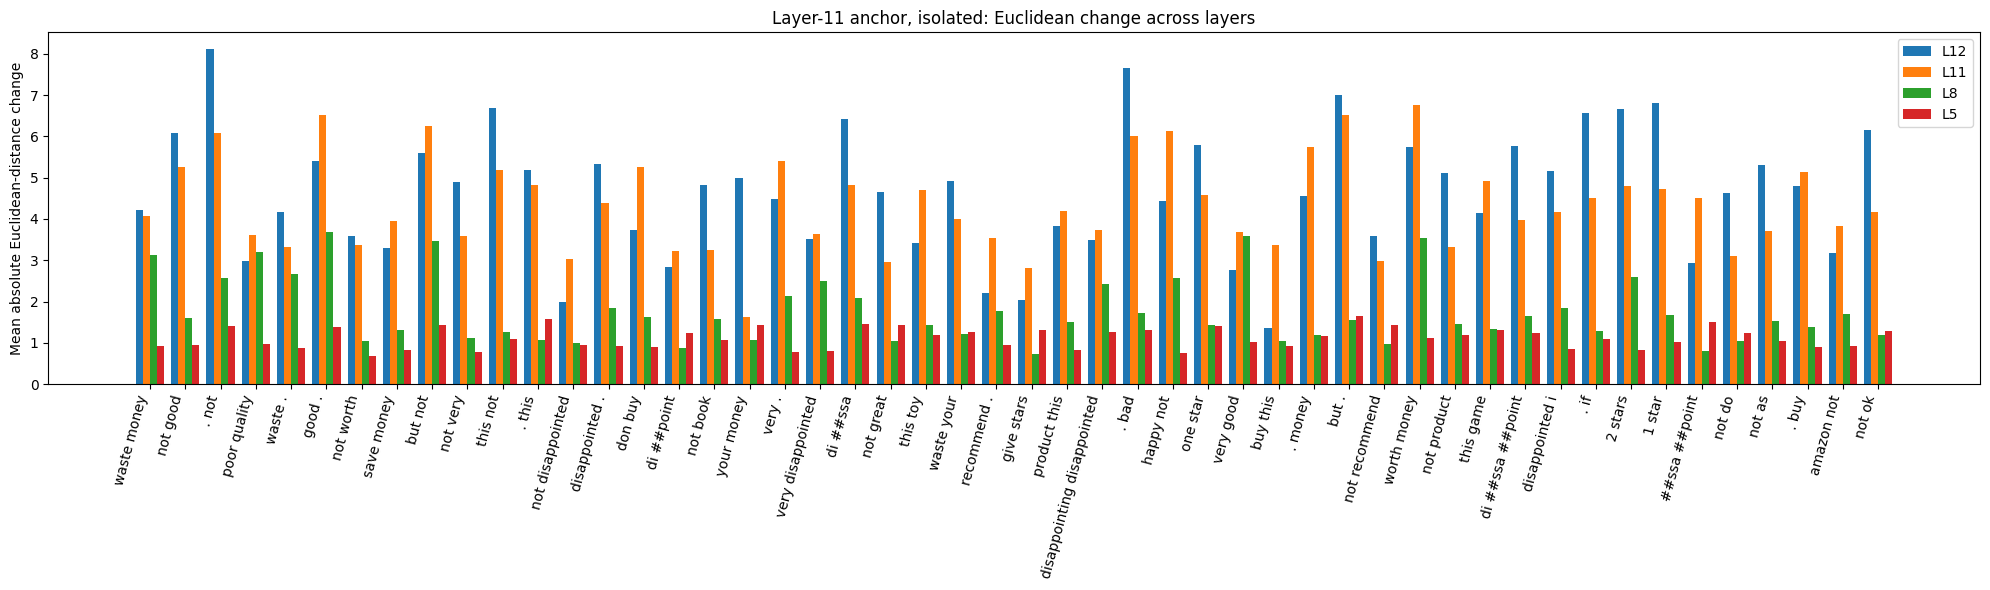

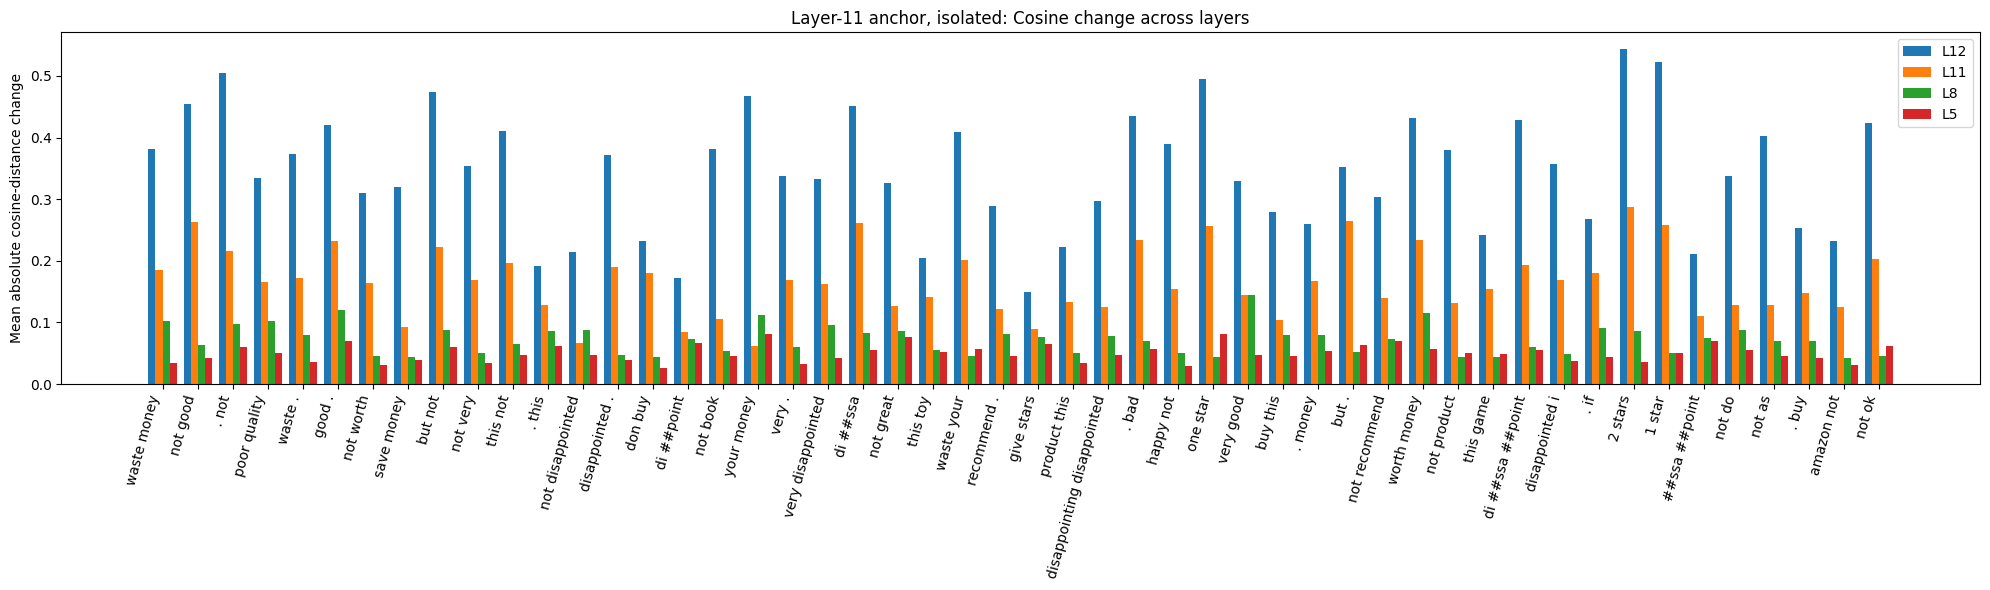

Layer 11, iso: 10 rating proxies and 1667 non-rating proxies


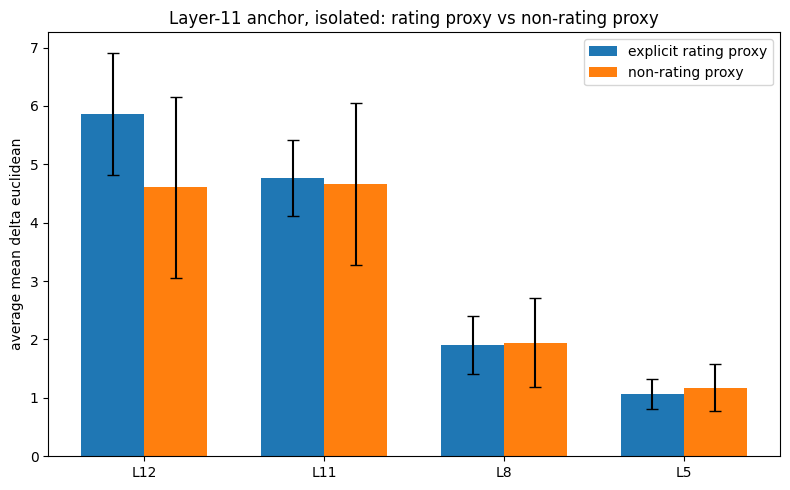

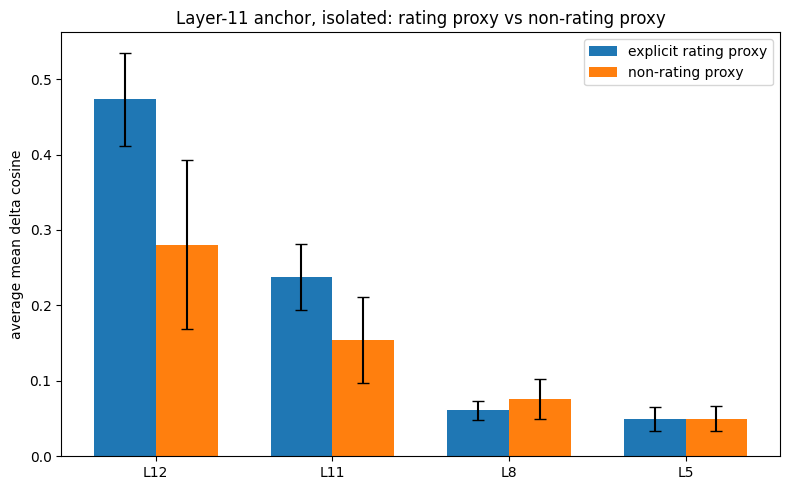

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,rating_proxy,10,L12,5.861399,1.052688,0.472937,0.062245
1,non_rating_proxy,1667,L12,4.602920,1.546523,0.280507,0.112352
2,rating_proxy,10,L11,4.764235,0.656714,0.237397,0.044065
3,non_rating_proxy,1667,L11,4.661939,1.379246,0.153923,0.057004
4,rating_proxy,10,L8,1.910564,0.498940,0.061095,0.012819
5,non_rating_proxy,1667,L8,1.945801,0.766199,0.075936,0.026991
6,rating_proxy,10,L5,1.061648,0.257784,0.049902,0.015766
7,non_rating_proxy,1667,L5,1.176624,0.409349,0.049705,0.016719


In [47]:
df_iso_l11 = run_anchor_analysis(df_mean, token_df, anchor_layer=11, context="iso")
plot_anchor_overlay(df_iso_l11, anchor_layer=11, context="iso")
plot_rating_proxy_vs_non_rating_proxy(df_iso_l11, anchor_layer=11, context="iso")

Templated


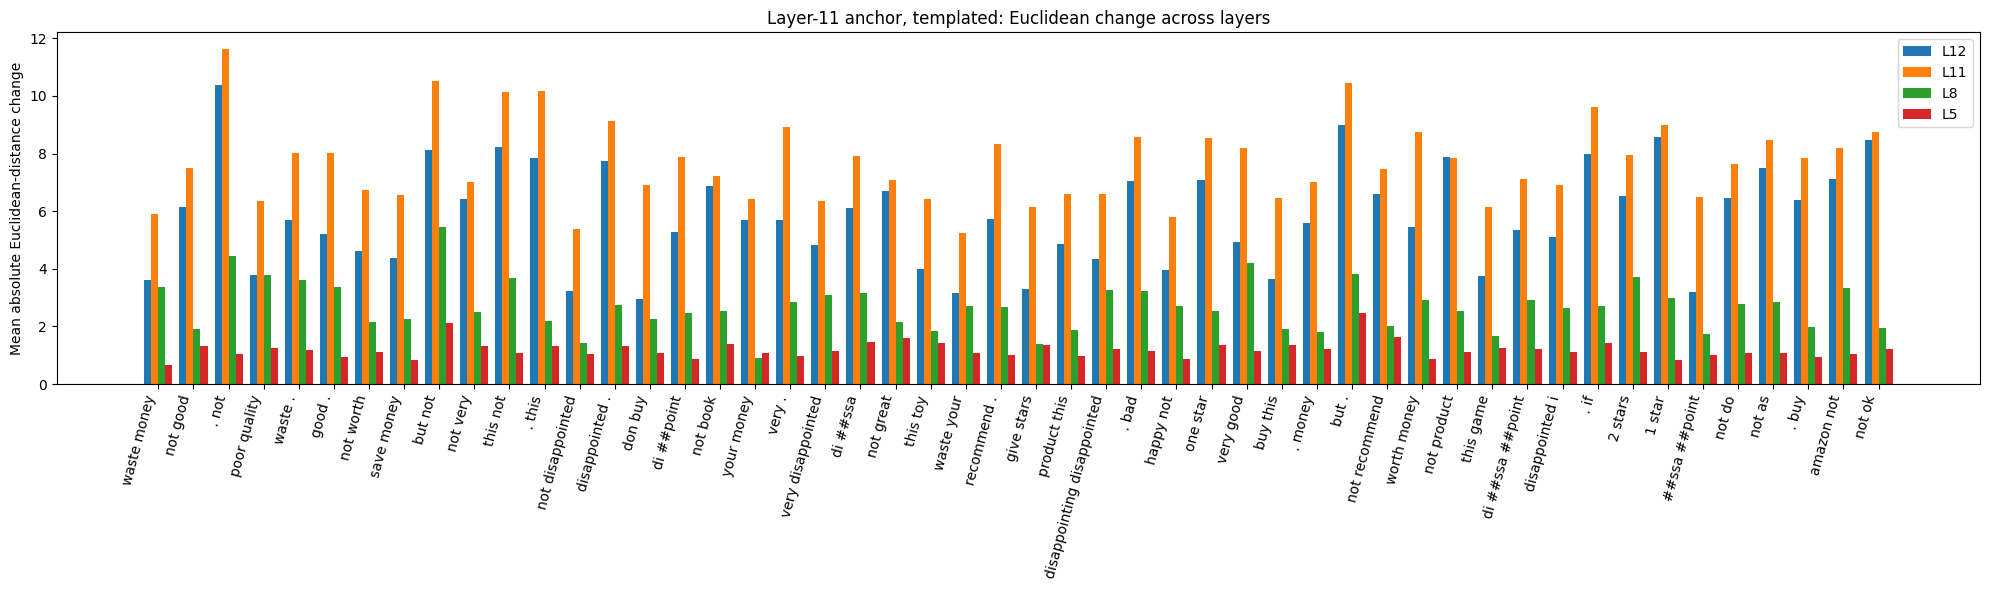

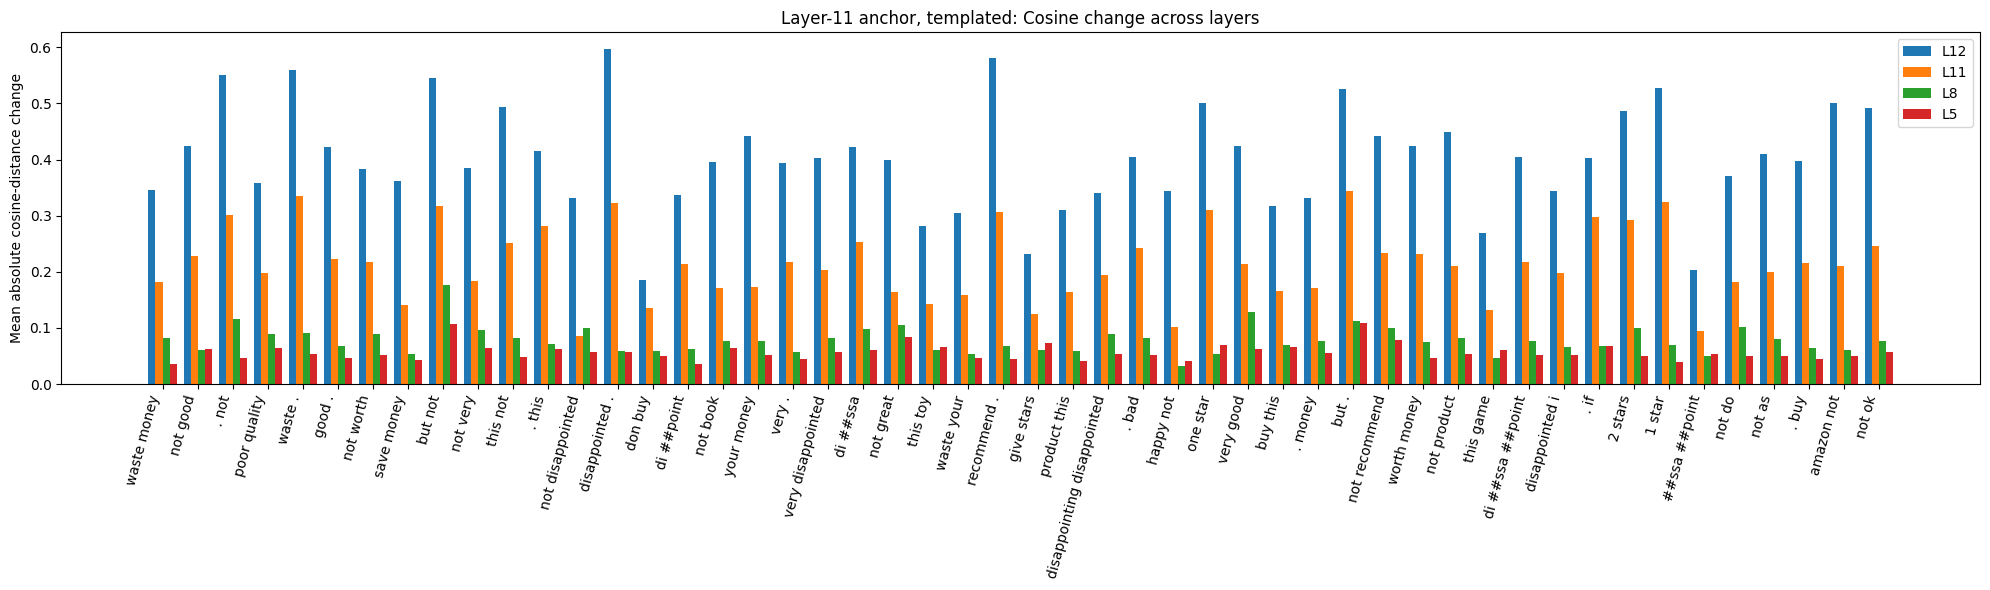

Layer 11, tpl: 10 rating proxies and 1667 non-rating proxies


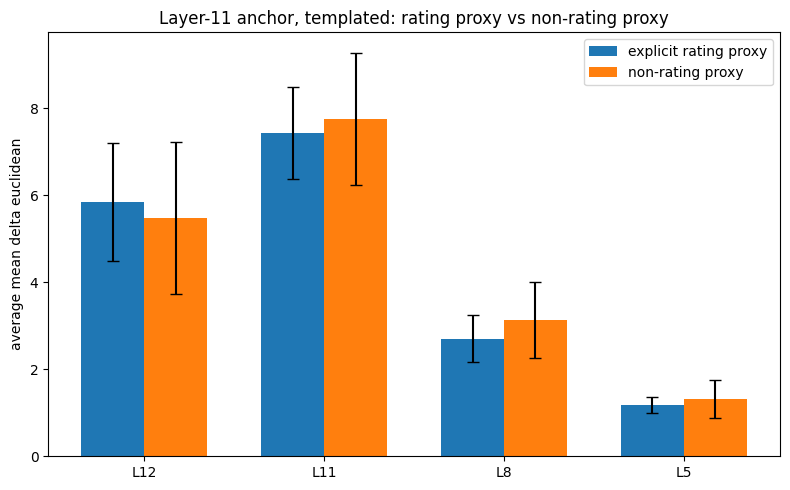

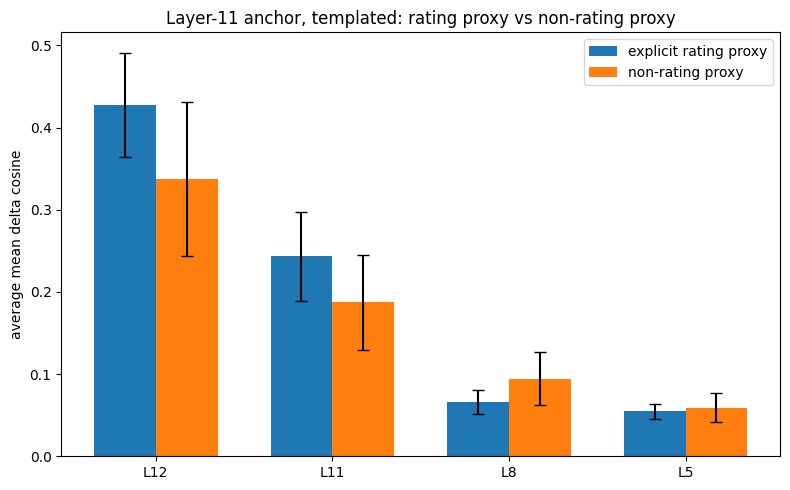

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,rating_proxy,10,L12,5.844177,1.362113,0.427596,0.063856
1,non_rating_proxy,1667,L12,5.486736,1.748585,0.337319,0.093600
2,rating_proxy,10,L11,7.443831,1.055199,0.243230,0.053817
3,non_rating_proxy,1667,L11,7.768731,1.517842,0.187257,0.057757
4,rating_proxy,10,L8,2.702450,0.540332,0.065723,0.014660
5,non_rating_proxy,1667,L8,3.136089,0.883497,0.094401,0.032489
6,rating_proxy,10,L5,1.177023,0.188252,0.054583,0.009103
7,non_rating_proxy,1667,L5,1.325584,0.437743,0.058992,0.017609


In [48]:
df_tpl_l11 = run_anchor_analysis(df_mean, token_df, anchor_layer=11, context="tpl")
plot_anchor_overlay(df_tpl_l11, anchor_layer=11, context="tpl")
plot_rating_proxy_vs_non_rating_proxy(df_tpl_l11, anchor_layer=11, context="tpl")

### Anchor Layer 8

Isolated

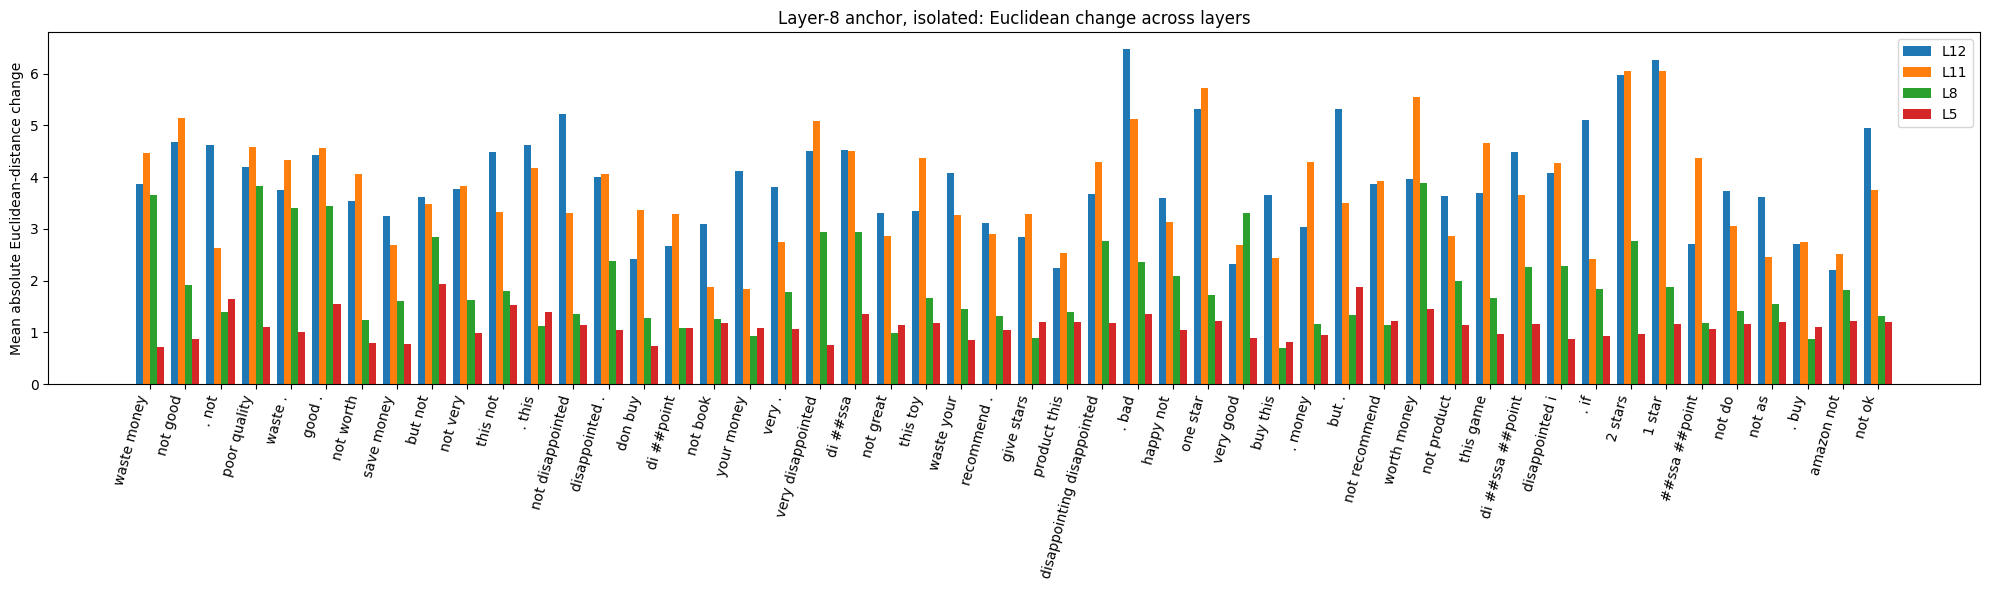

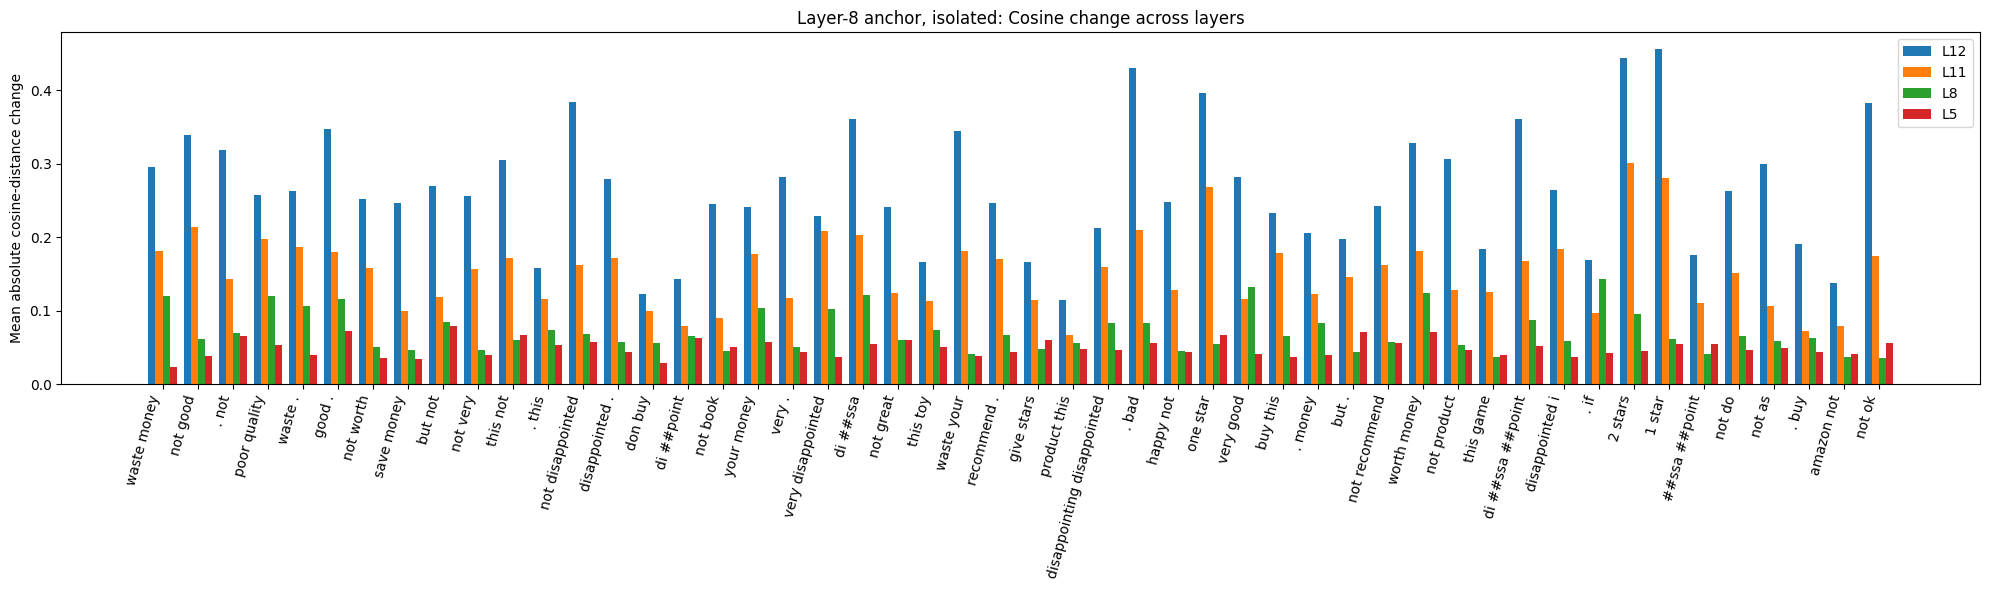

Layer 8, iso: 10 rating proxies and 1667 non-rating proxies


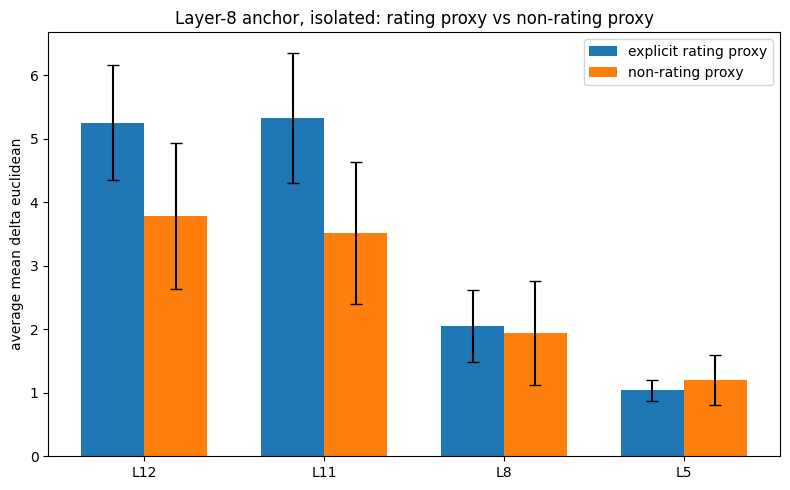

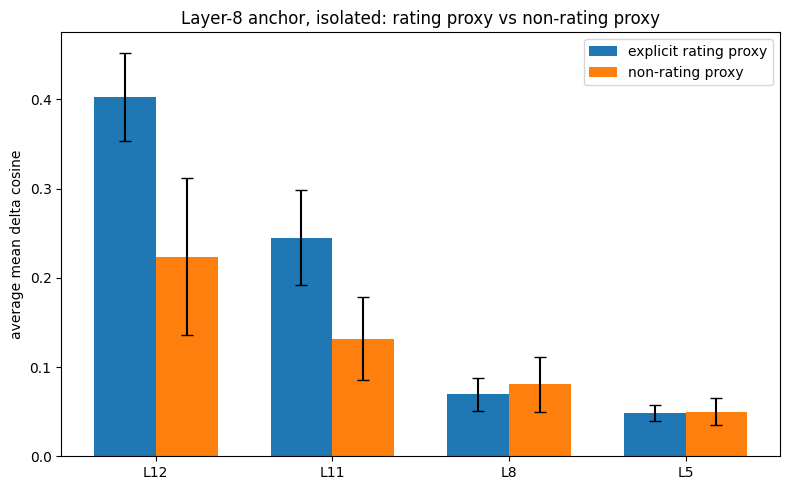

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,rating_proxy,10,L12,5.257214,0.901023,0.402782,0.049710
1,non_rating_proxy,1667,L12,3.784685,1.142833,0.223552,0.087834
2,rating_proxy,10,L11,5.330370,1.030108,0.244997,0.053463
3,non_rating_proxy,1667,L11,3.521845,1.119300,0.131865,0.046134
4,rating_proxy,10,L8,2.052142,0.567361,0.069368,0.018699
5,non_rating_proxy,1667,L8,1.939633,0.821045,0.080608,0.031204
6,rating_proxy,10,L5,1.039614,0.161556,0.048332,0.009126
7,non_rating_proxy,1667,L5,1.207772,0.395403,0.050051,0.015255


In [49]:
df_iso_l8 = run_anchor_analysis(df_mean, token_df, anchor_layer=8, context="iso")
plot_anchor_overlay(df_iso_l8, anchor_layer=8, context="iso")
plot_rating_proxy_vs_non_rating_proxy(df_iso_l8, anchor_layer=8, context="iso")

Templated

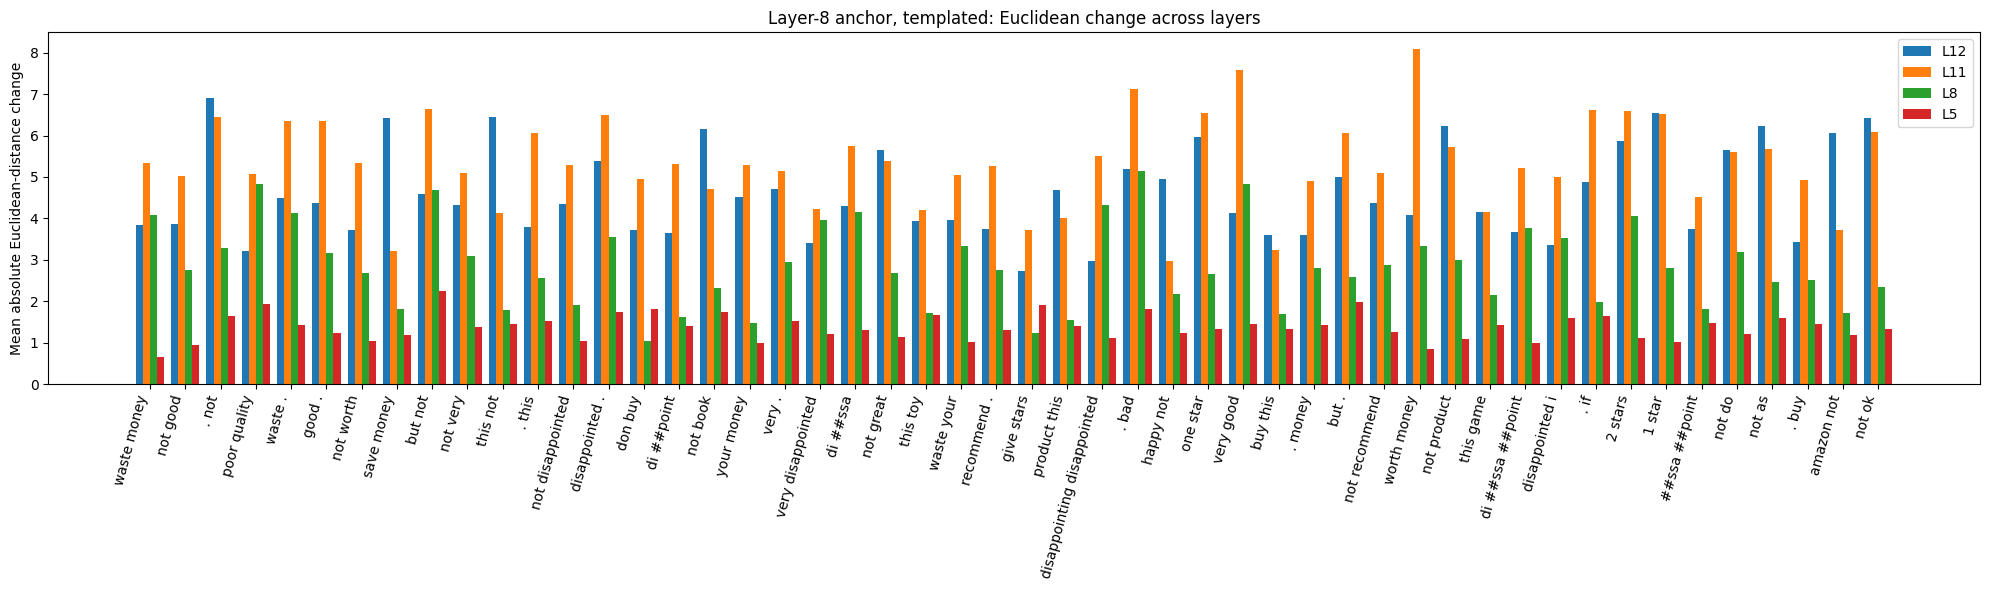

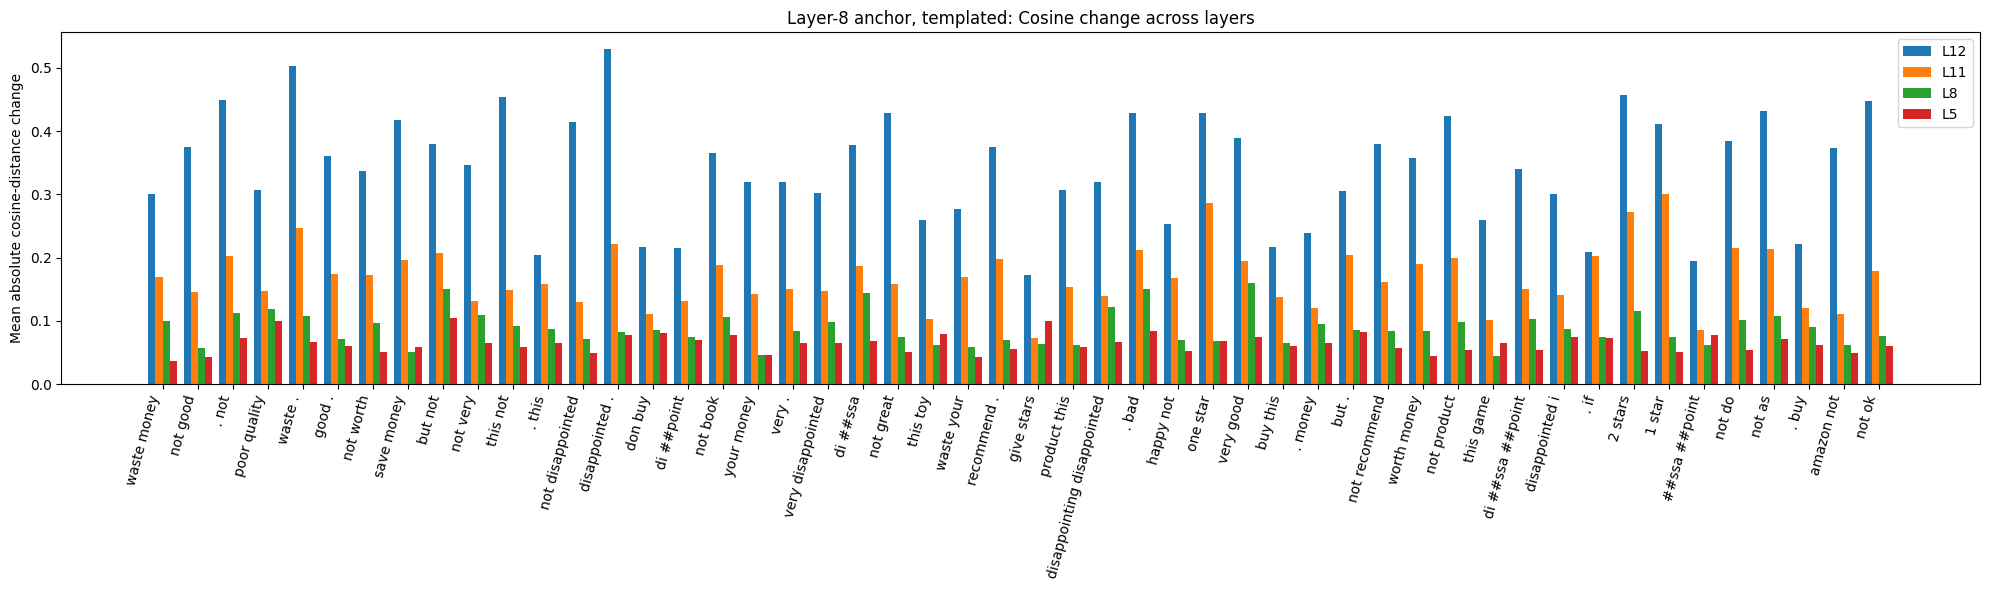

Layer 8, tpl: 10 rating proxies and 1667 non-rating proxies


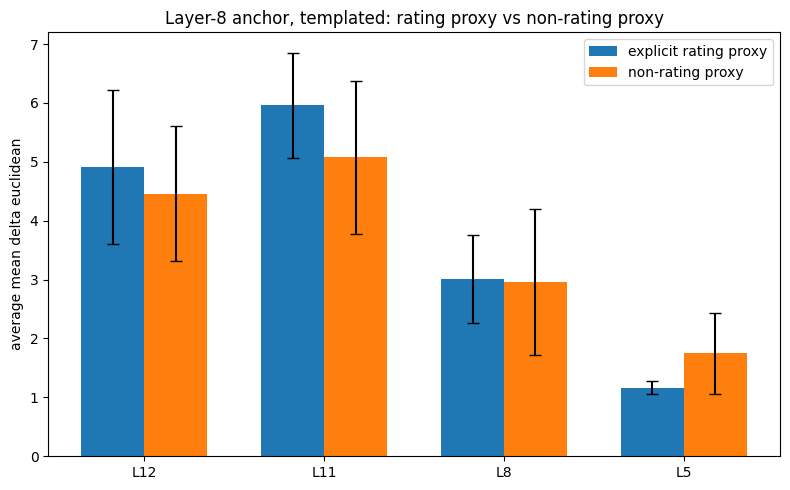

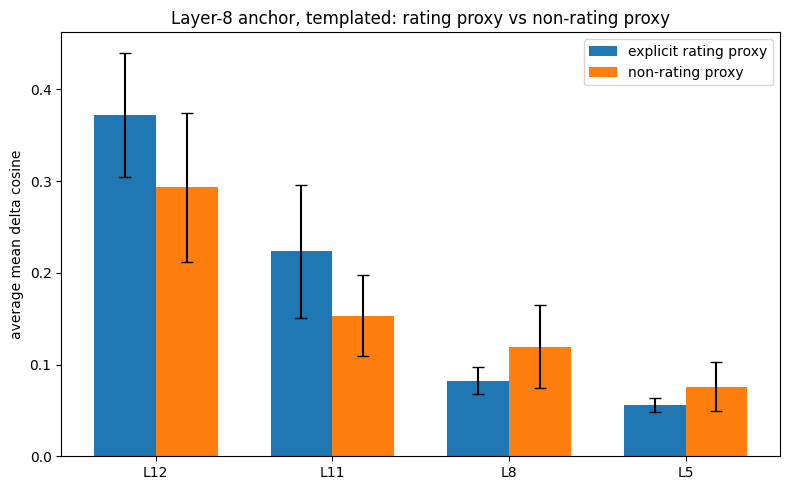

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,rating_proxy,10,L12,4.915873,1.312290,0.372490,0.067799
1,non_rating_proxy,1667,L12,4.457140,1.144304,0.293226,0.081652
2,rating_proxy,10,L11,5.964306,0.891820,0.223545,0.072398
3,non_rating_proxy,1667,L11,5.076179,1.298419,0.153162,0.044064
4,rating_proxy,10,L8,3.011841,0.747339,0.082462,0.014684
5,non_rating_proxy,1667,L8,2.957744,1.237834,0.119349,0.045208
6,rating_proxy,10,L5,1.164176,0.107573,0.055483,0.007593
7,non_rating_proxy,1667,L5,1.748150,0.683337,0.076022,0.026747


In [50]:
df_tpl_l8 = run_anchor_analysis(df_mean, token_df, anchor_layer=8, context="tpl")
plot_anchor_overlay(df_tpl_l8, anchor_layer=8, context="tpl")
plot_rating_proxy_vs_non_rating_proxy(df_tpl_l8, anchor_layer=8, context="tpl")

### Anchor Layer 5

Isolate 

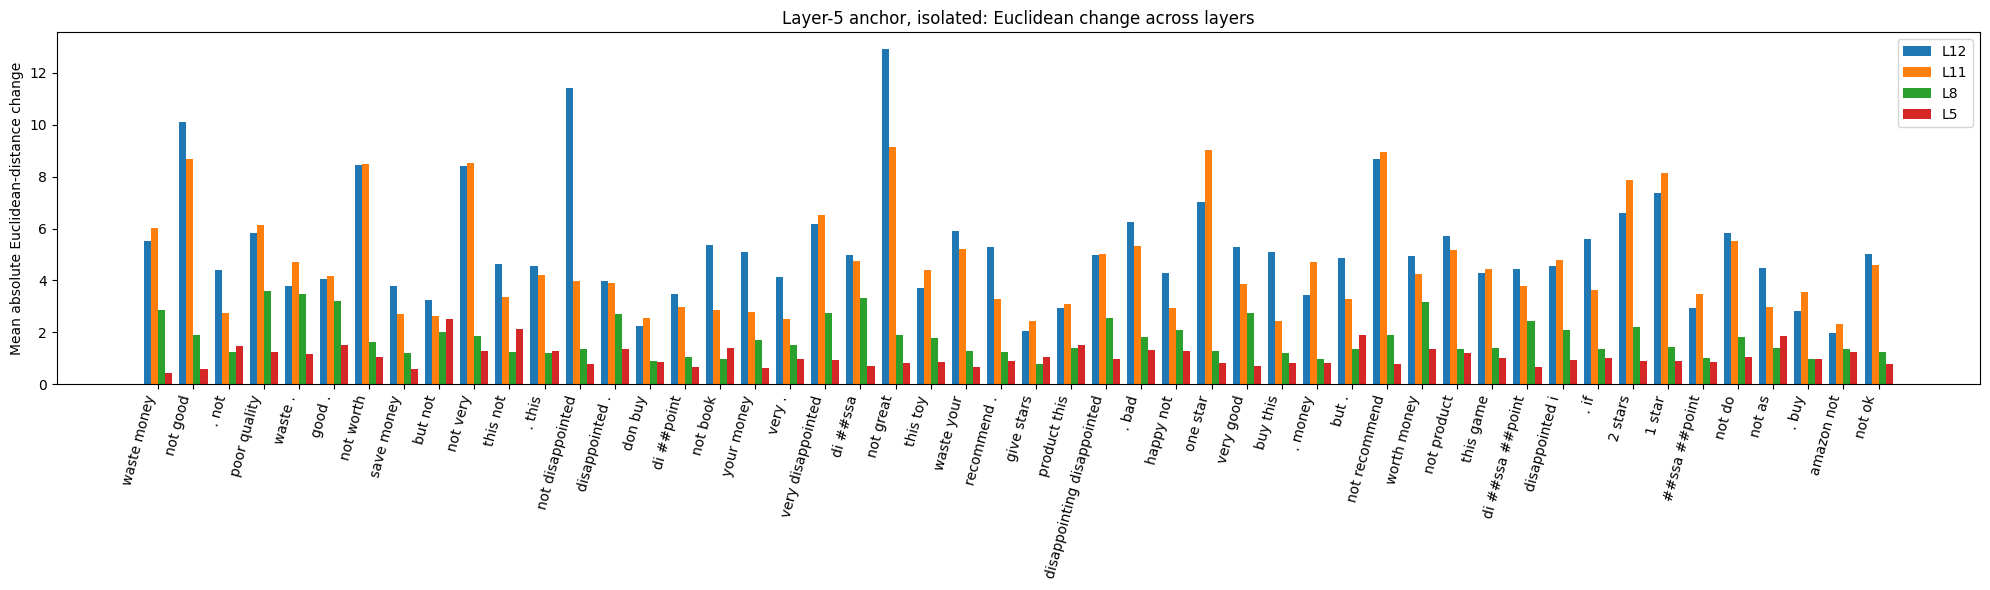

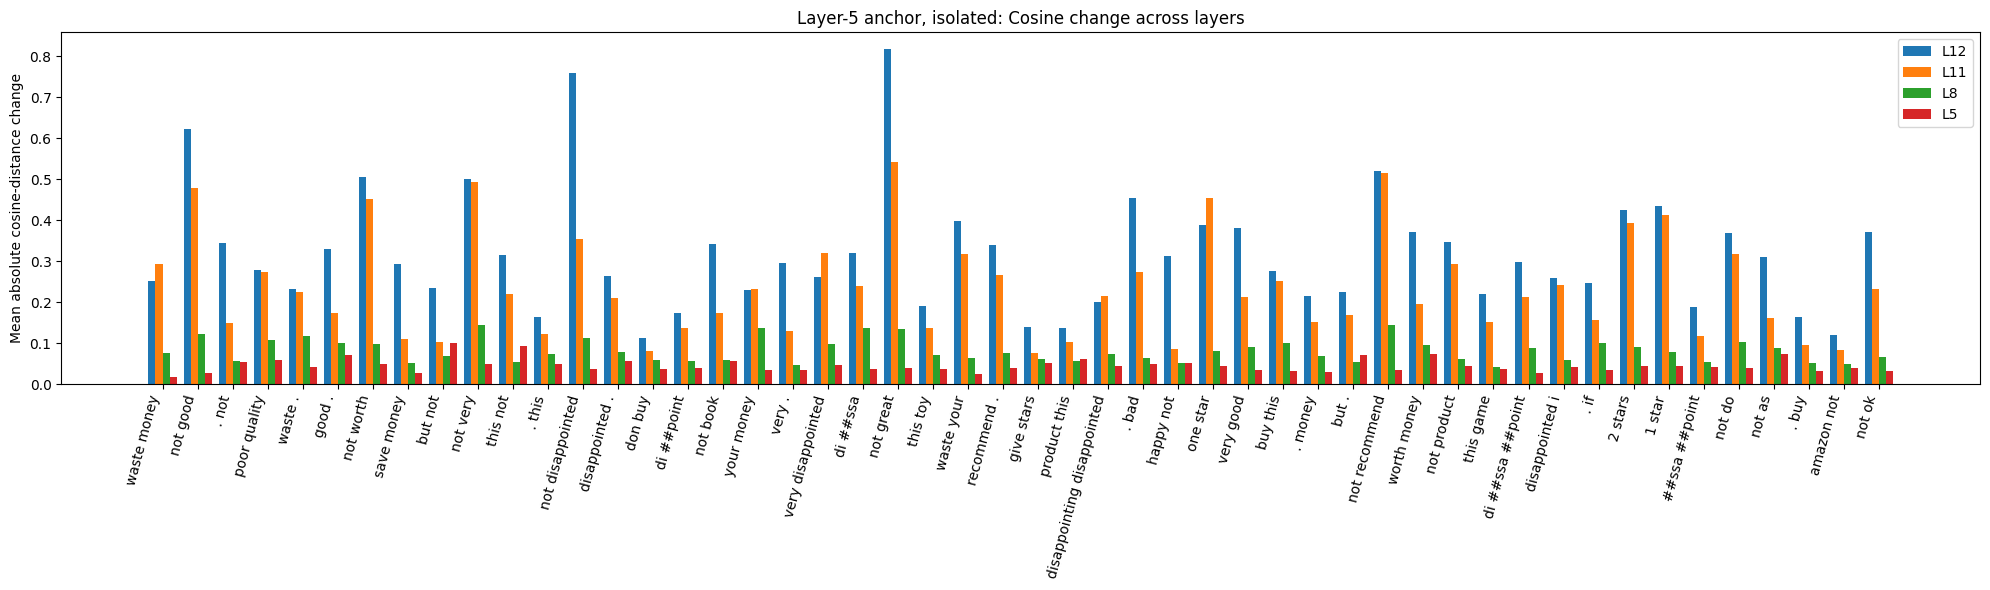

Layer 5, iso: 10 rating proxies and 1667 non-rating proxies


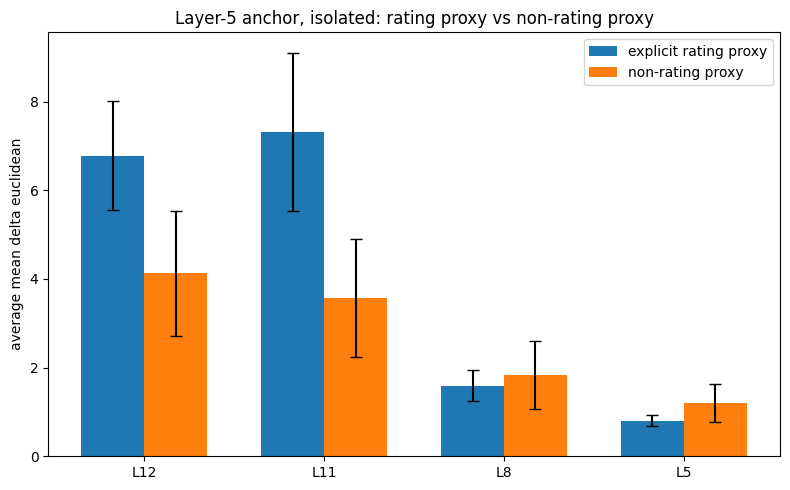

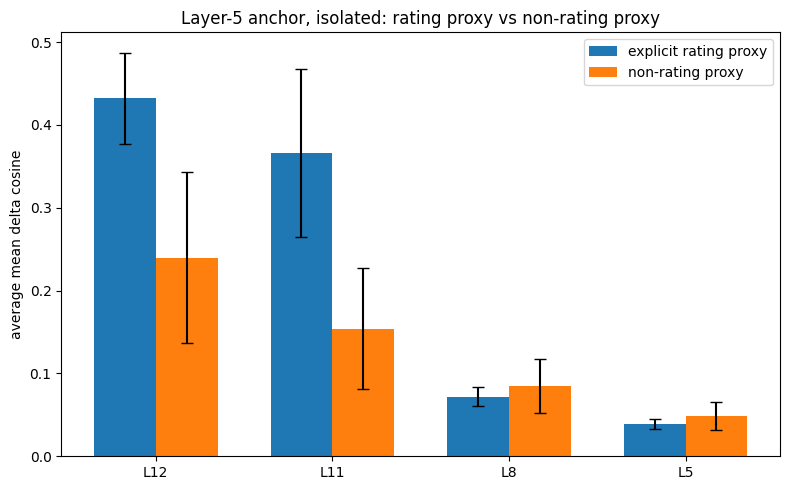

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,rating_proxy,10,L12,6.783639,1.232982,0.432195,0.055214
1,non_rating_proxy,1667,L12,4.123494,1.417961,0.239661,0.102977
2,rating_proxy,10,L11,7.315387,1.792977,0.366248,0.101317
3,non_rating_proxy,1667,L11,3.575952,1.335612,0.154017,0.073269
4,rating_proxy,10,L8,1.595459,0.353190,0.071914,0.011771
5,non_rating_proxy,1667,L8,1.838225,0.761659,0.084564,0.032335
6,rating_proxy,10,L5,0.807034,0.113285,0.038847,0.005706
7,non_rating_proxy,1667,L5,1.206655,0.423945,0.048756,0.016528


In [51]:
df_iso_l5 = run_anchor_analysis(df_mean, token_df, anchor_layer=5, context="iso")
plot_anchor_overlay(df_iso_l5, anchor_layer=5, context="iso")
plot_rating_proxy_vs_non_rating_proxy(df_iso_l5, anchor_layer=5, context="iso")

Templated

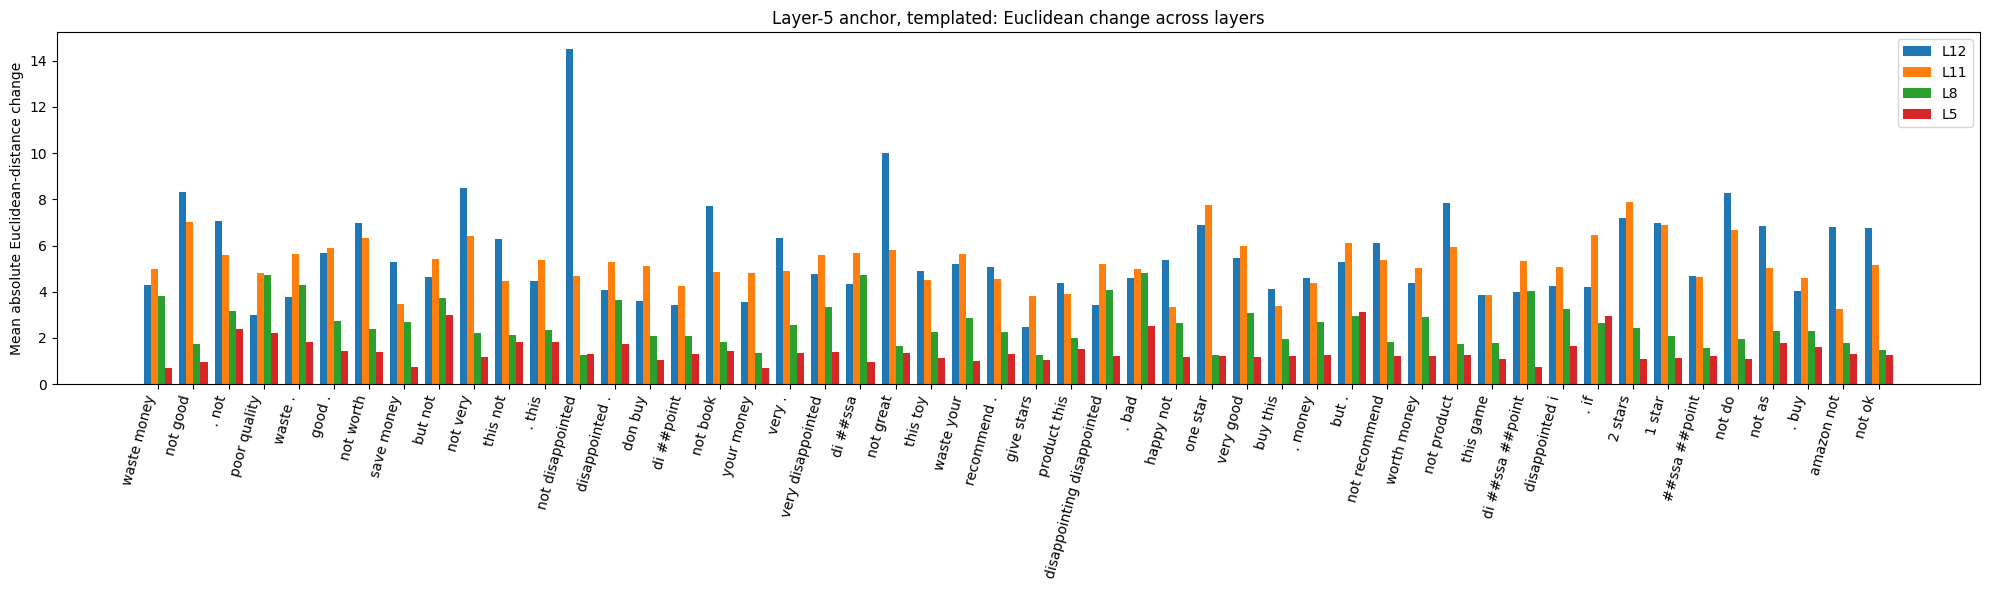

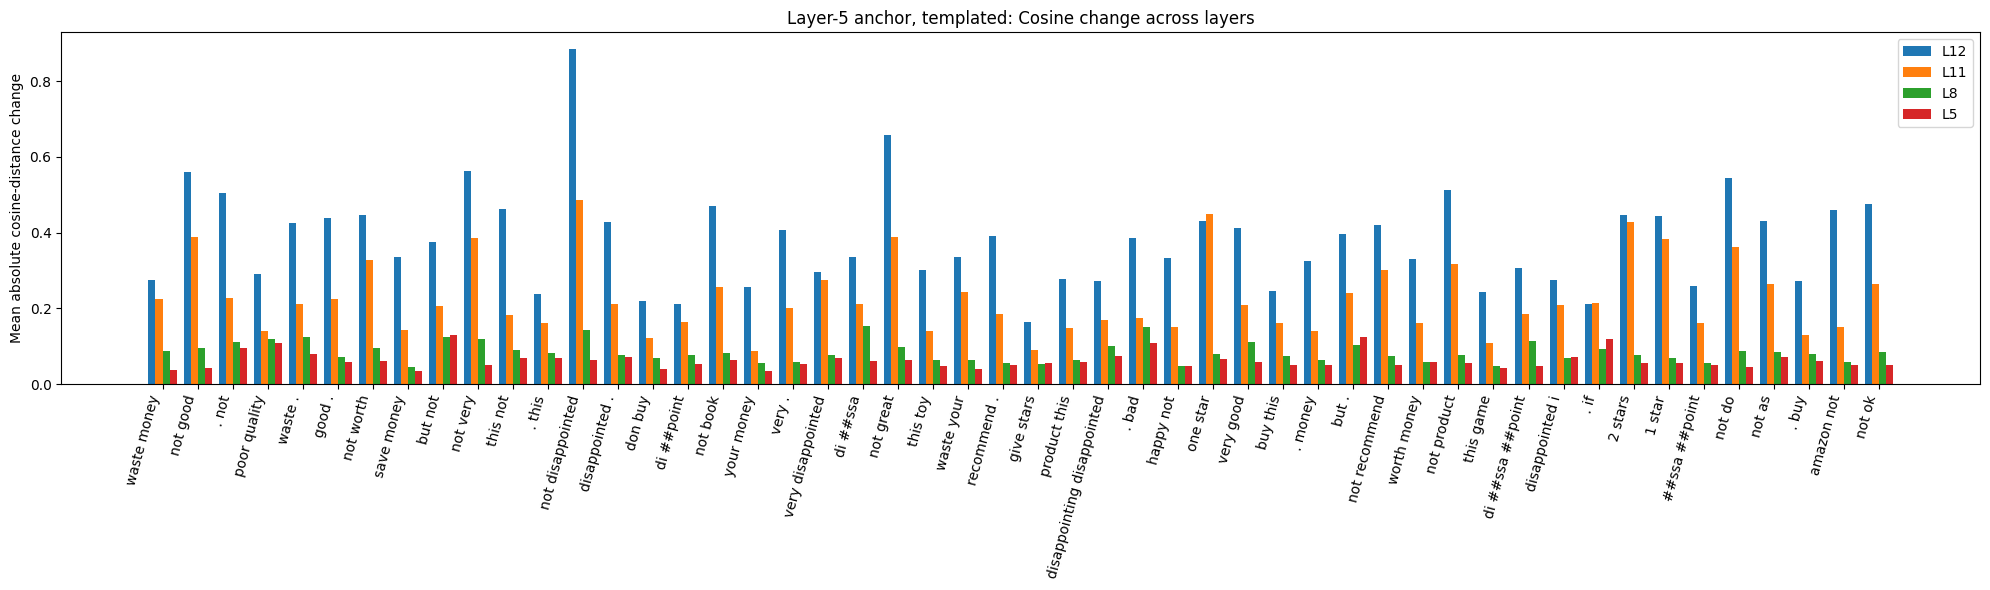

Layer 5, tpl: 10 rating proxies and 1667 non-rating proxies


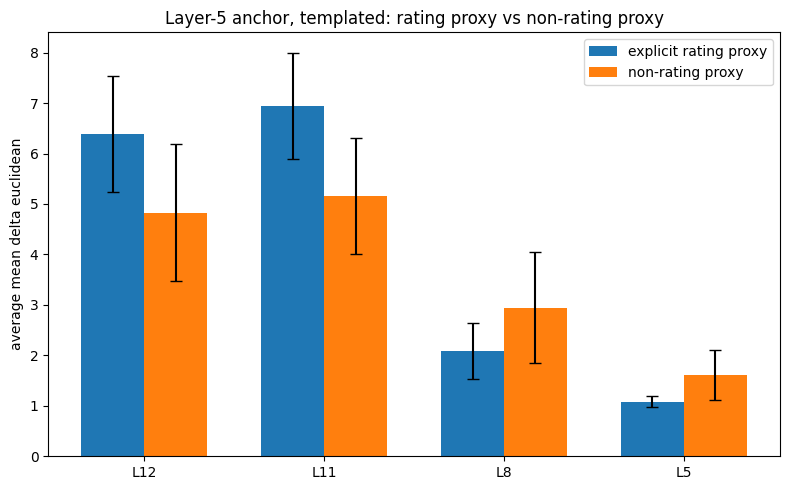

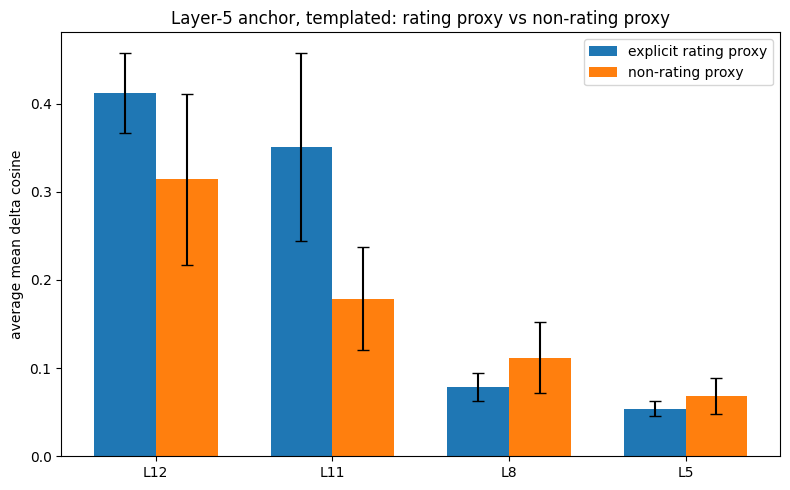

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,rating_proxy,10,L12,6.382756,1.149068,0.411837,0.045142
1,non_rating_proxy,1667,L12,4.821902,1.357471,0.314105,0.097055
2,rating_proxy,10,L11,6.950751,1.051232,0.351388,0.106675
3,non_rating_proxy,1667,L11,5.163894,1.152774,0.178943,0.058380
4,rating_proxy,10,L8,2.087331,0.562831,0.078543,0.015816
5,non_rating_proxy,1667,L8,2.948252,1.099062,0.112053,0.040367
6,rating_proxy,10,L5,1.080834,0.111140,0.053704,0.008503
7,non_rating_proxy,1667,L5,1.619037,0.496707,0.068699,0.020573


In [52]:
df_tpl_l5 = run_anchor_analysis(df_mean, token_df, anchor_layer=5, context="tpl")
plot_anchor_overlay(df_tpl_l5, anchor_layer=5, context="tpl")
plot_rating_proxy_vs_non_rating_proxy(df_tpl_l5, anchor_layer=5, context="tpl")

In [53]:
import numpy as np
import matplotlib.pyplot as plt

def plot_anchor_same_layer_with_std(
    df,
    anchor_layer,
    context="iso",   # "iso" or "tpl"
    top_n=50,
    min_length=2,
    sort_col="support",
):
    assert context in {"iso", "tpl"}

    if context == "iso":
        euc_mean_col = f"mean_delta_l{anchor_layer}_euclidean_l{anchor_layer}"
        euc_raw_col  = f"delta_l{anchor_layer}_euclidean_l{anchor_layer}"
        cos_mean_col = f"mean_delta_l{anchor_layer}_cosine_l{anchor_layer}"
        cos_raw_col  = f"delta_l{anchor_layer}_cosine_l{anchor_layer}"
        title_prefix = f"Layer-{anchor_layer} anchor, isolated"
    else:
        euc_mean_col = f"mean_delta_tpl_l{anchor_layer}_euclidean_l{anchor_layer}"
        euc_raw_col  = f"delta_tpl_l{anchor_layer}_euclidean_l{anchor_layer}"
        cos_mean_col = f"mean_delta_tpl_l{anchor_layer}_cosine_l{anchor_layer}"
        cos_raw_col  = f"delta_tpl_l{anchor_layer}_cosine_l{anchor_layer}"
        title_prefix = f"Layer-{anchor_layer} anchor, templated"

    plot_df = (
        df[df["length"] >= min_length]
        .sort_values(sort_col, ascending=False)
        .head(top_n)
        .copy()
    )

    plot_df["label"] = plot_df["ordered_tokens"].apply(
        lambda x: " ".join(x) if isinstance(x, list) else str(x)
    )

    # std over the raw NN delta values for each itemset
    plot_df["std_euclidean"] = plot_df[euc_raw_col].apply(
        lambda xs: float(np.std(xs)) if len(xs) > 0 else 0.0
    )
    plot_df["std_cosine"] = plot_df[cos_raw_col].apply(
        lambda xs: float(np.std(xs)) if len(xs) > 0 else 0.0
    )

    x = np.arange(len(plot_df))

    # Euclidean
    plt.figure(figsize=(20, 6))
    plt.bar(
        x,
        plot_df[euc_mean_col],
        yerr=plot_df["std_euclidean"],
        capsize=4
    )
    plt.xticks(x, plot_df["label"], rotation=75, ha="right")
    plt.ylabel("mean delta euclidean")
    plt.title(f"{title_prefix}: same-layer delta euclidean only")
    plt.tight_layout()
    plt.show()

    # Cosine
    plt.figure(figsize=(20, 6))
    plt.bar(
        x,
        plot_df[cos_mean_col],
        yerr=plot_df["std_cosine"],
        capsize=4
    )
    plt.xticks(x, plot_df["label"], rotation=75, ha="right")
    plt.ylabel("mean delta cosine")
    plt.title(f"{title_prefix}: same-layer delta cosine only")
    plt.tight_layout()
    plt.show()

    return plot_df[
        [
            "label",
            euc_mean_col,
            "std_euclidean",
            cos_mean_col,
            "std_cosine",
        ]
    ]

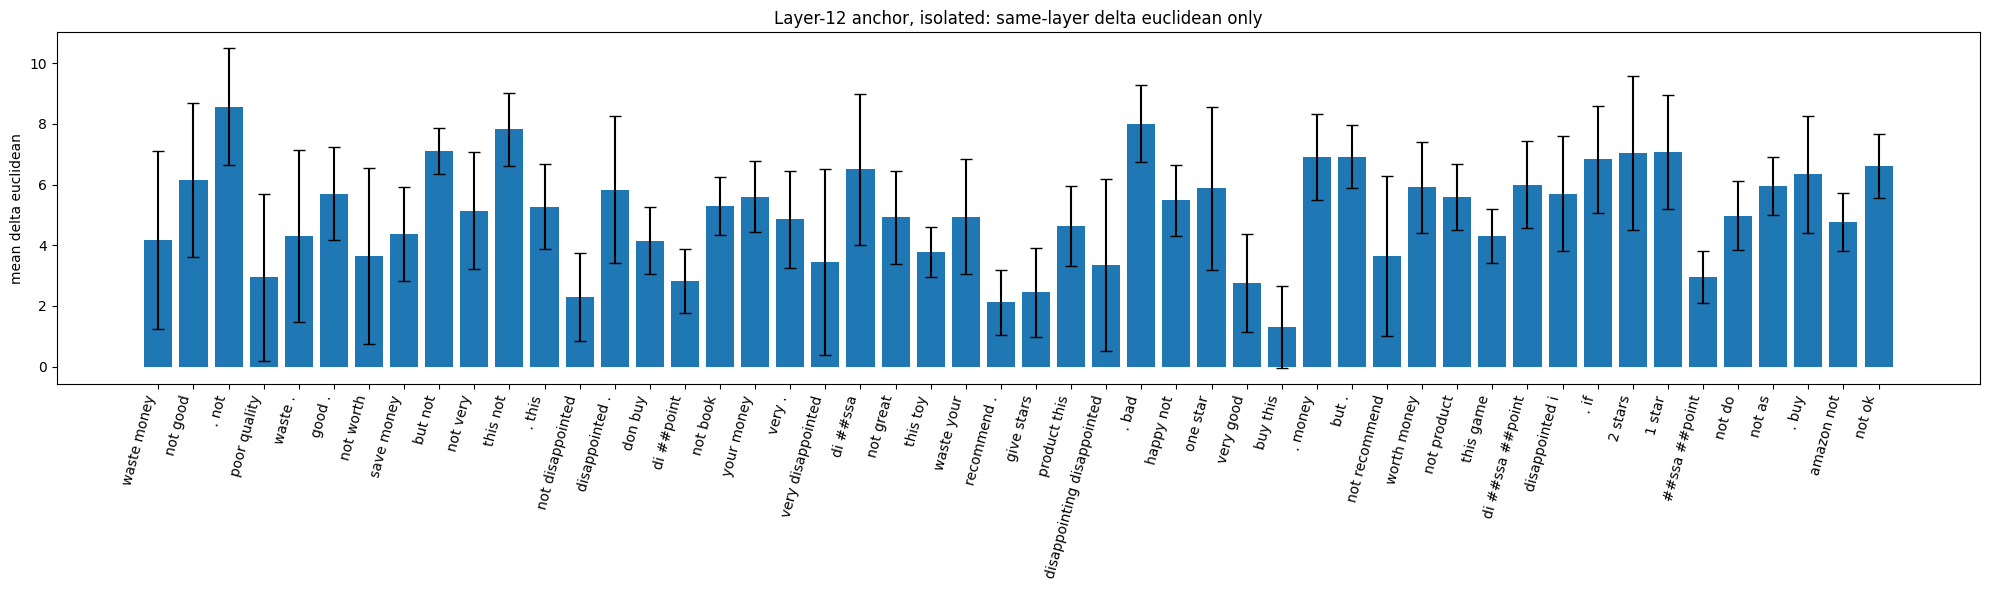

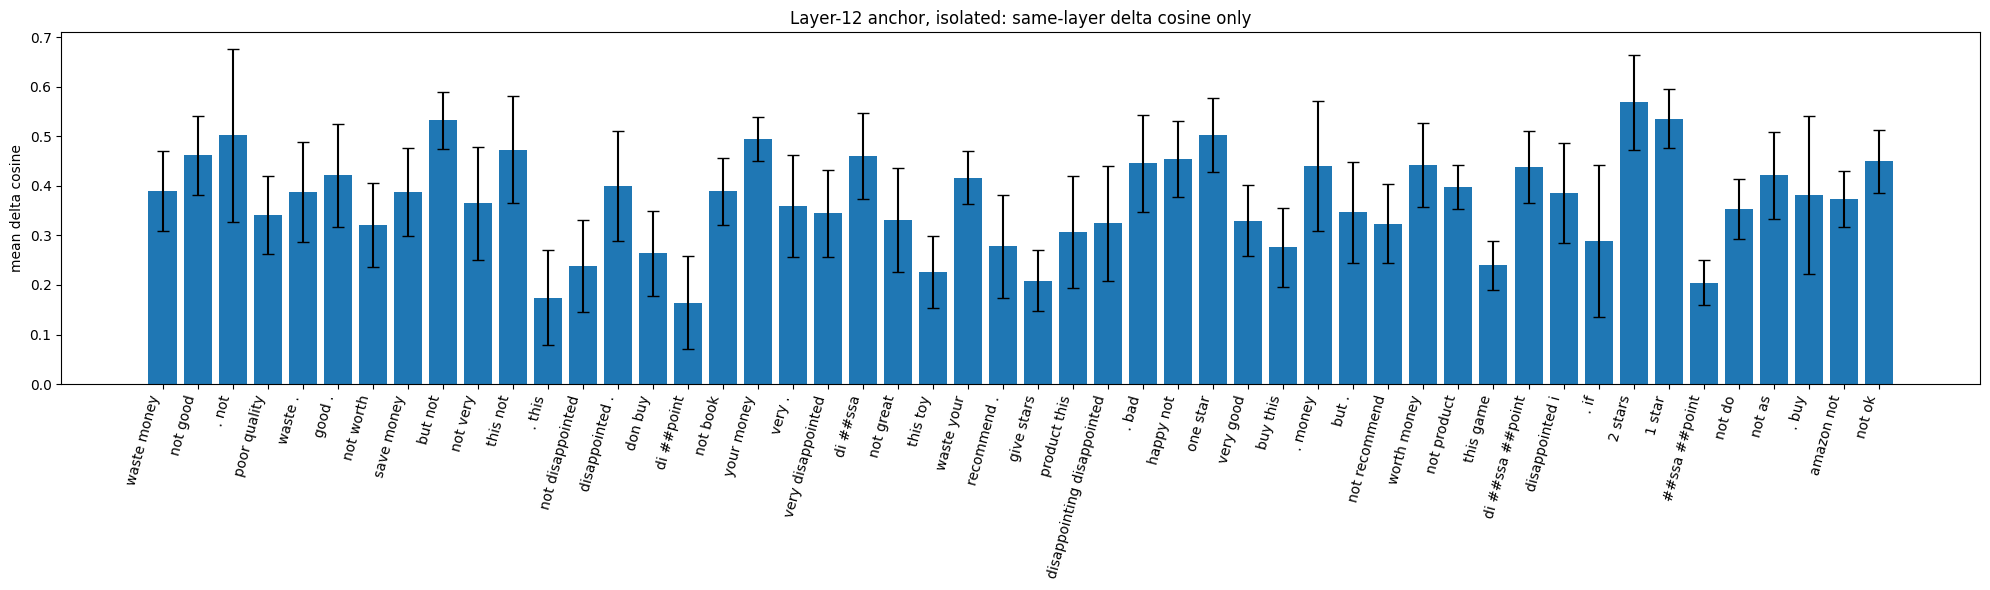

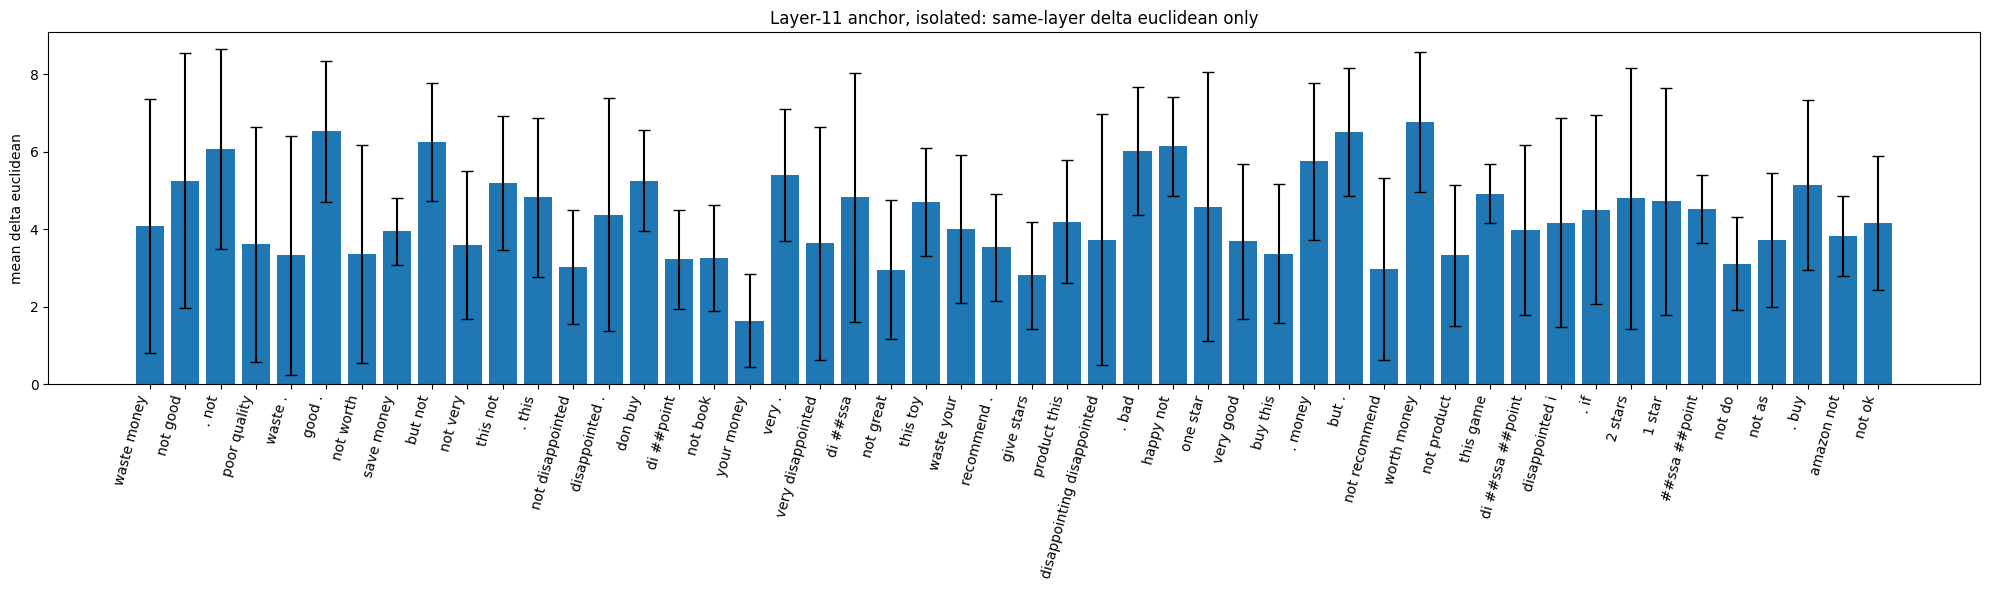

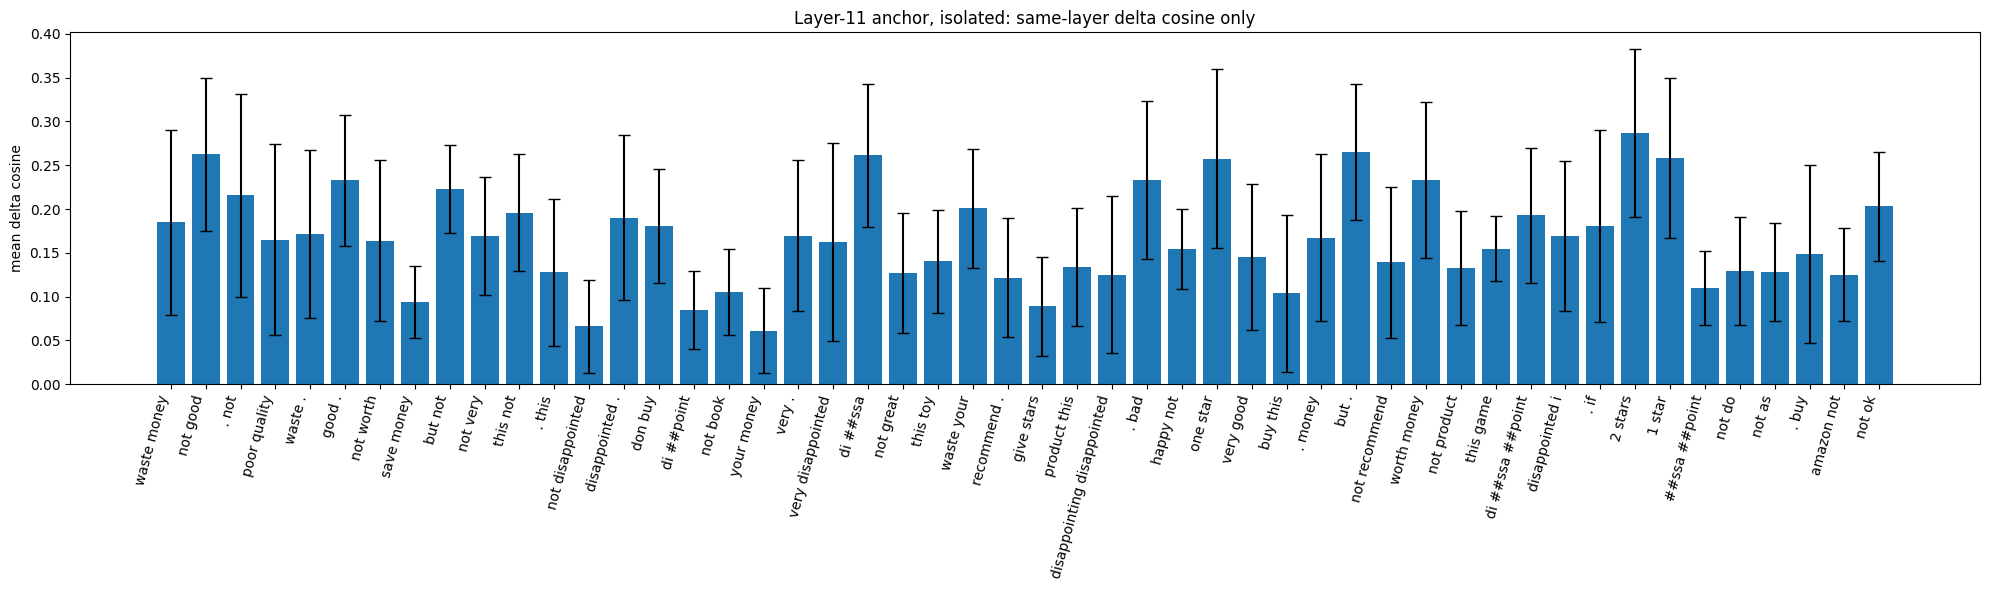

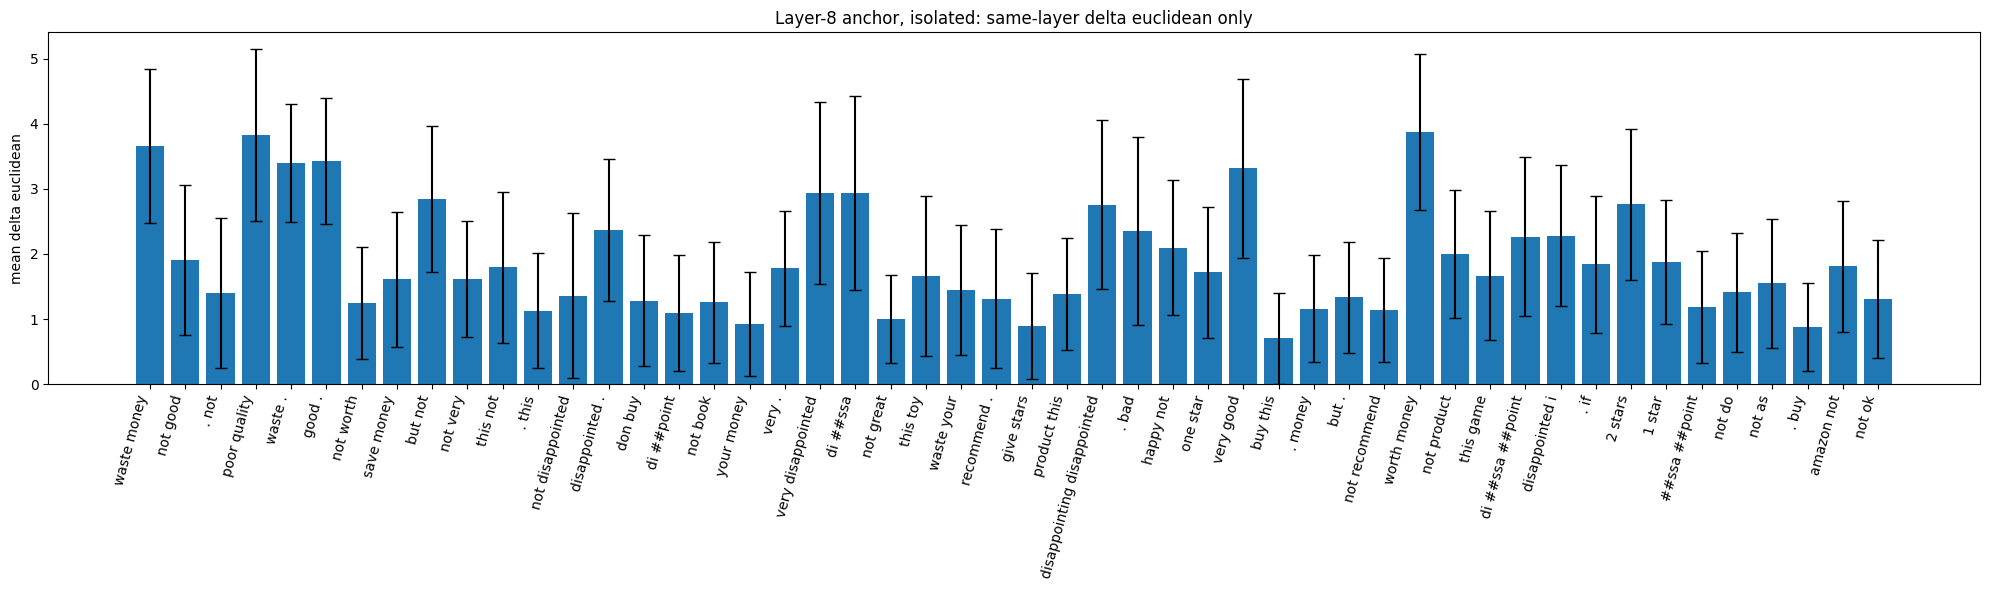

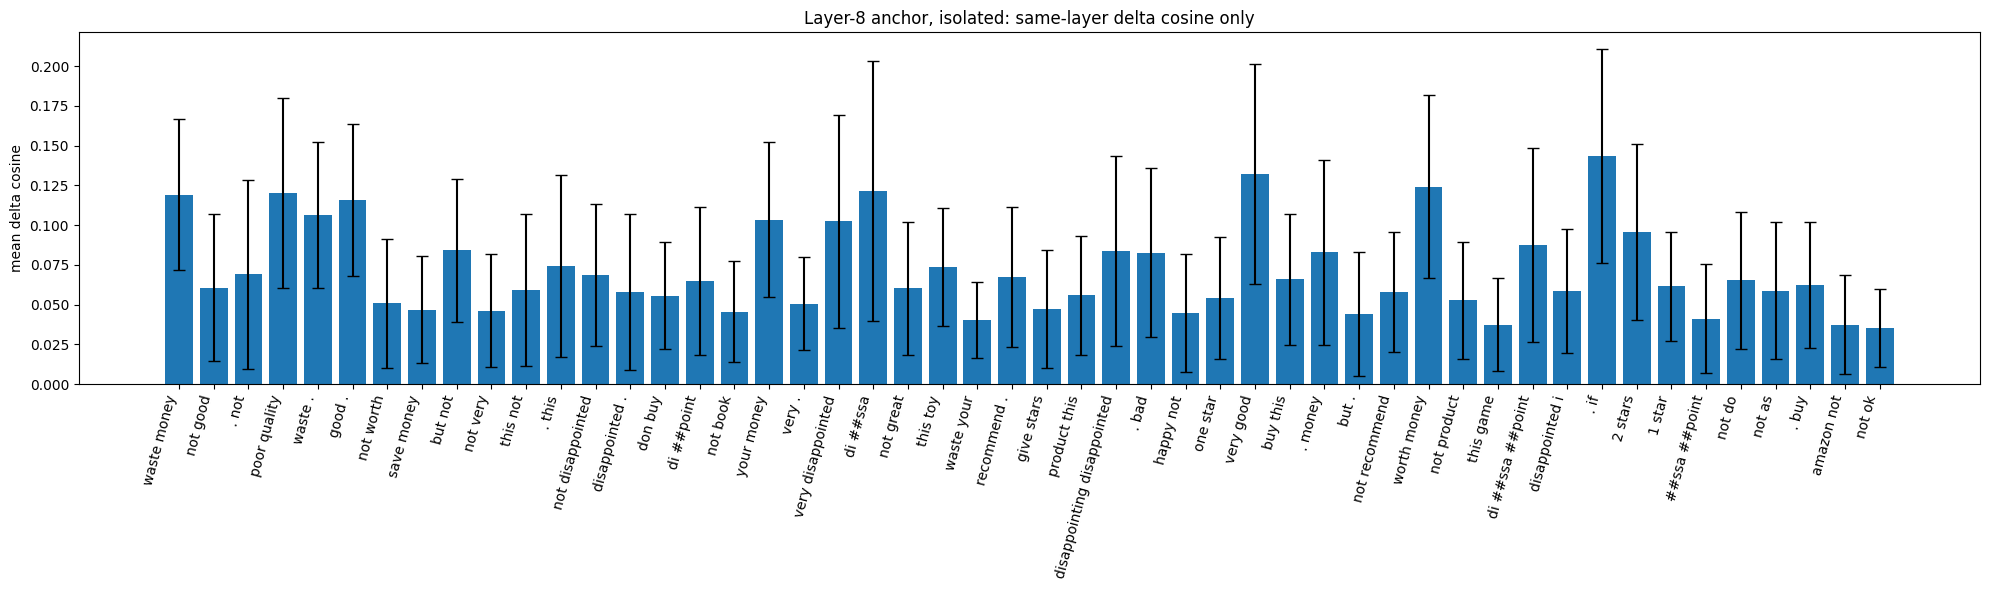

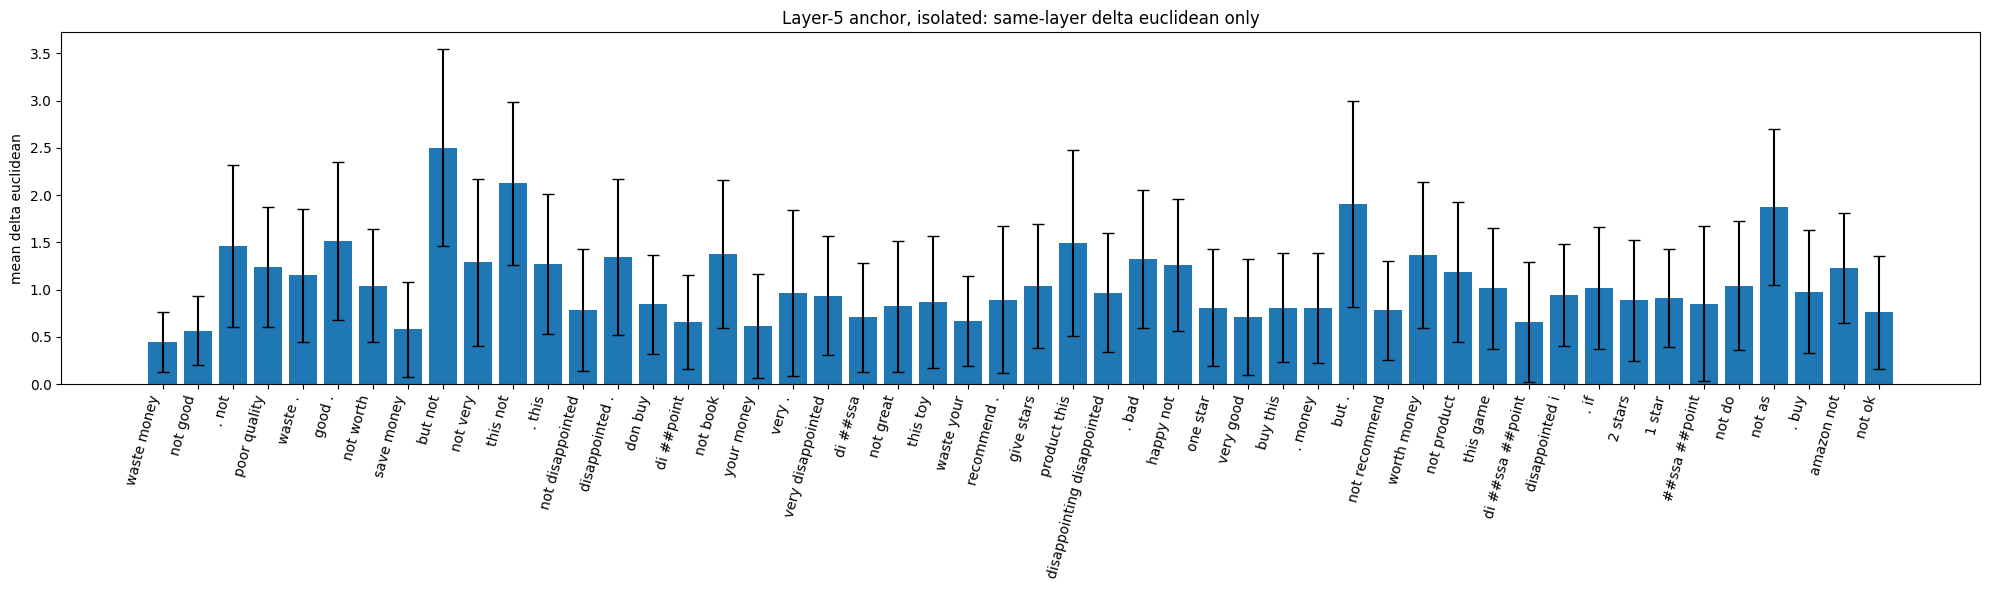

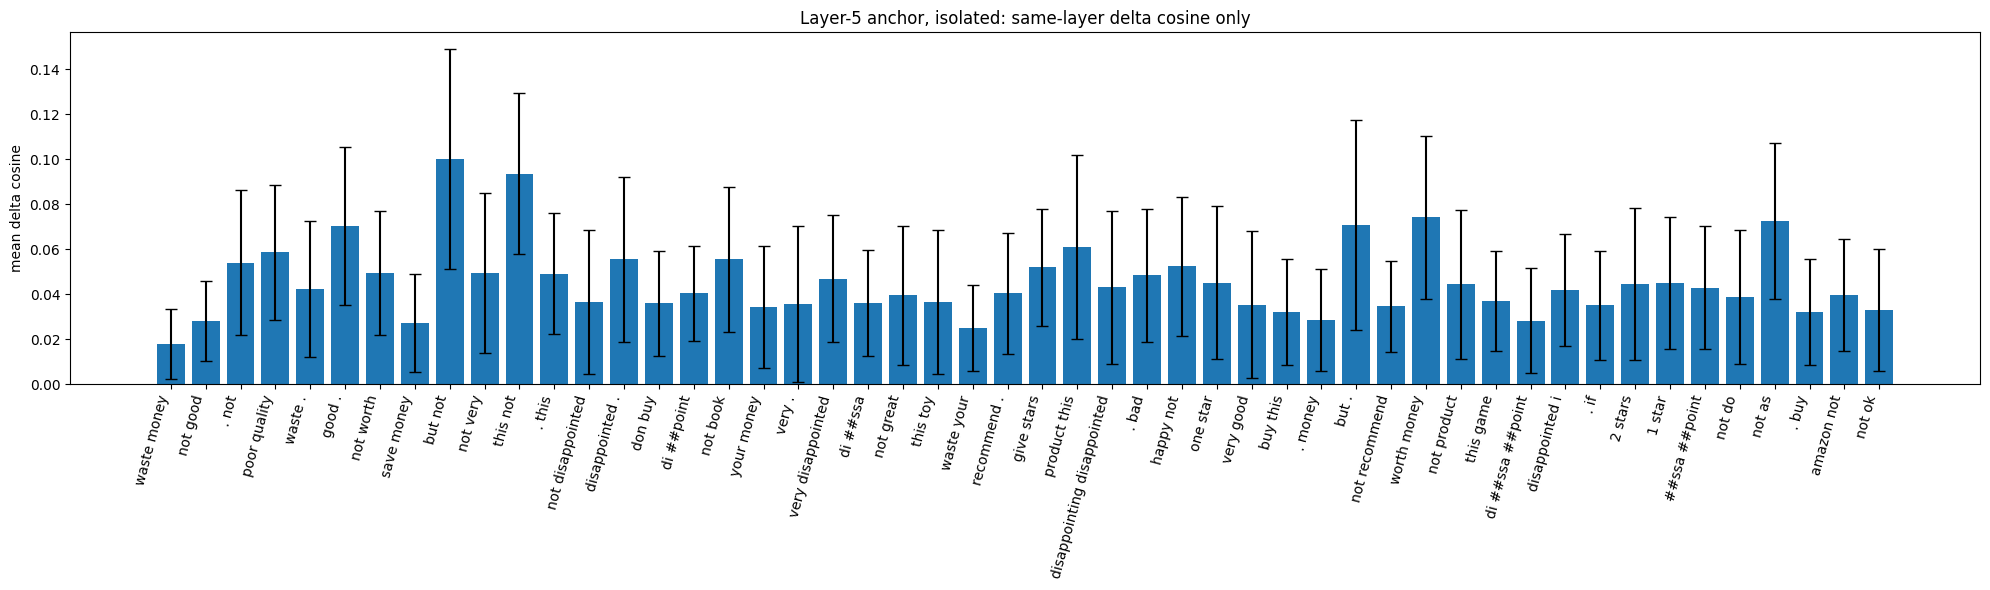

,label,mean_delta_l5_euclidean_l5,std_euclidean,mean_delta_l5_cosine_l5,std_cosine
25,waste money,0.444660,0.315000,0.017741,0.015562
77,not good,0.566496,0.361286,0.028117,0.017692
139,. not,1.464377,0.856519,0.054046,0.032131
65,poor quality,1.235905,0.636384,0.058548,0.029903
99,waste .,1.149269,0.703338,0.042392,0.030304
161,good .,1.517100,0.836294,0.070311,0.034956
116,not worth,1.042662,0.599087,0.049272,0.027553
144,save money,0.580467,0.503177,0.027167,0.021895
205,but not,2.502776,1.041938,0.100151,0.048790
190,not very,1.286649,0.878286,0.049348,0.035482


In [54]:
plot_anchor_same_layer_with_std(df_iso_l12, anchor_layer=12, context="iso")
plot_anchor_same_layer_with_std(df_iso_l11, anchor_layer=11, context="iso")
plot_anchor_same_layer_with_std(df_iso_l8,  anchor_layer=8,  context="iso")
plot_anchor_same_layer_with_std(df_iso_l5,  anchor_layer=5,  context="iso")

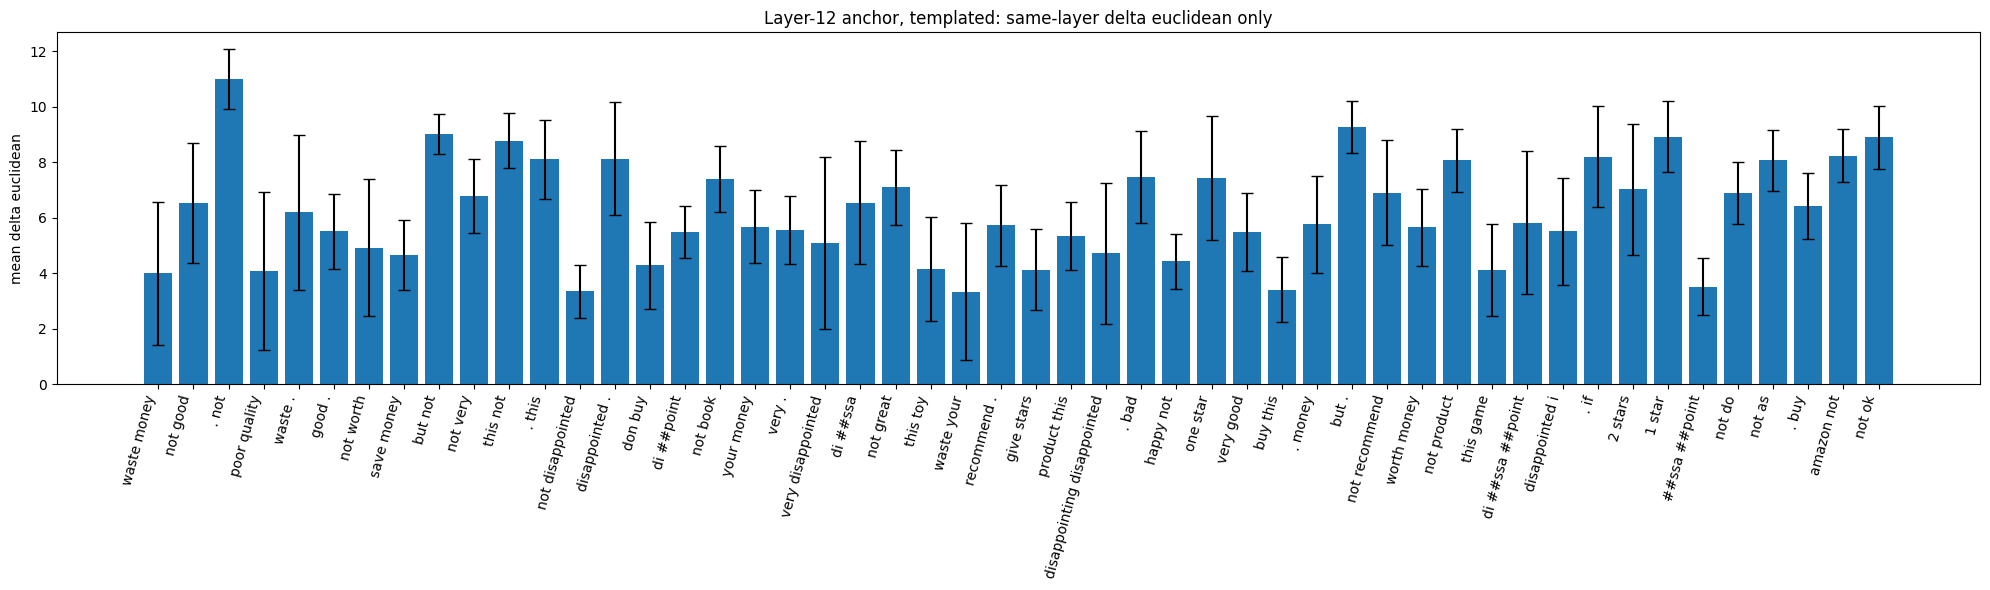

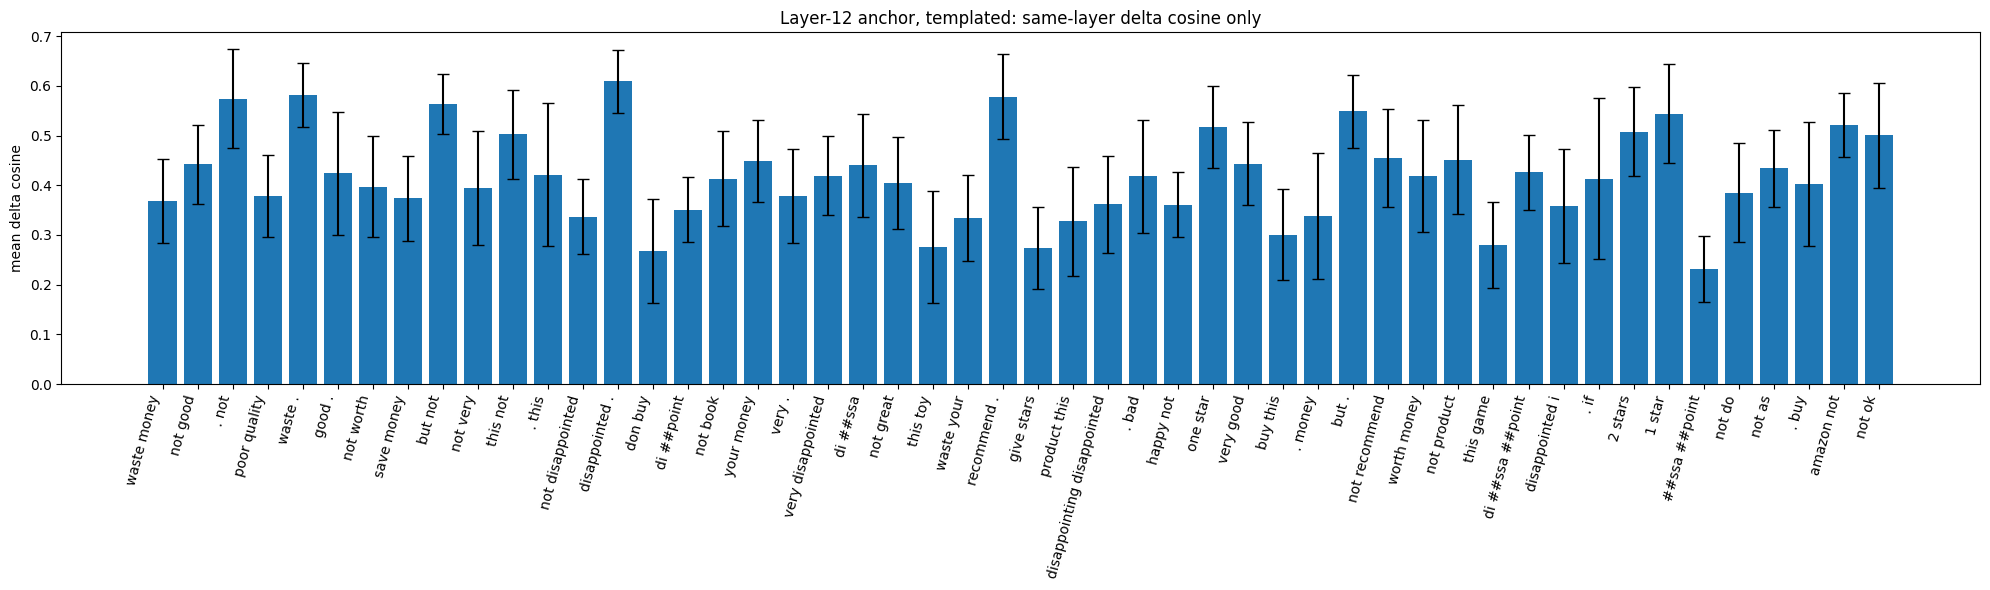

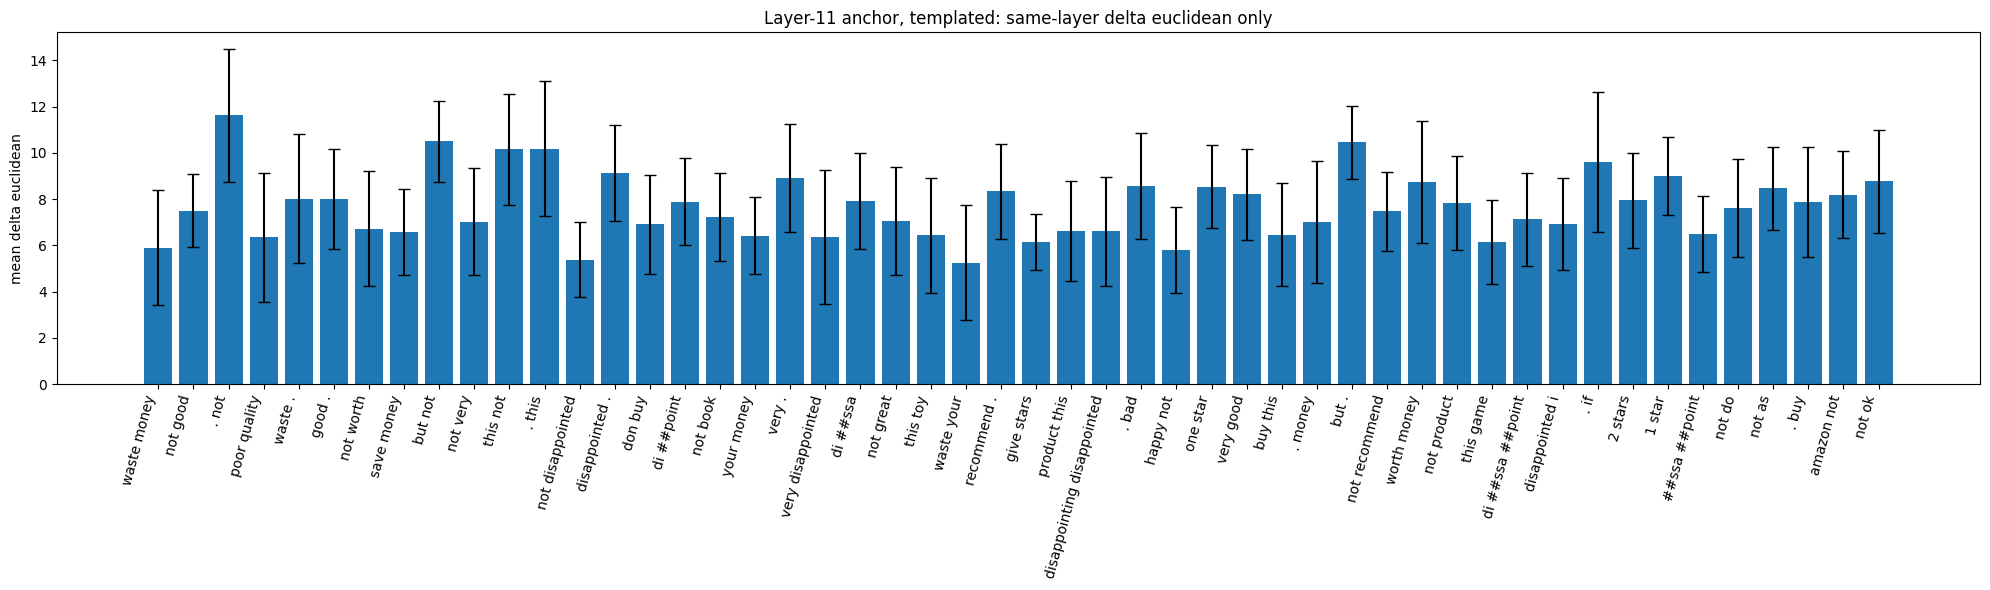

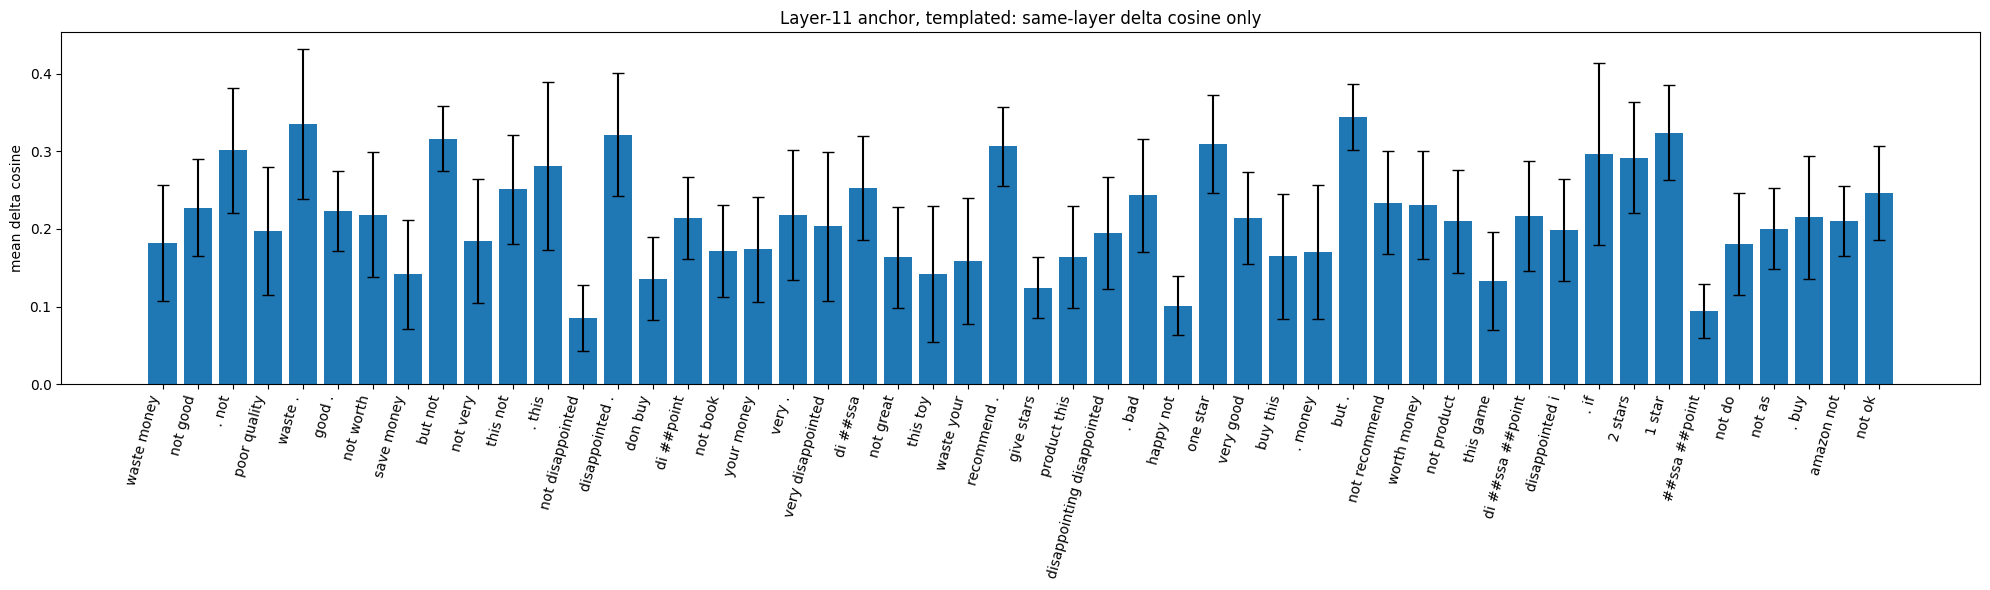

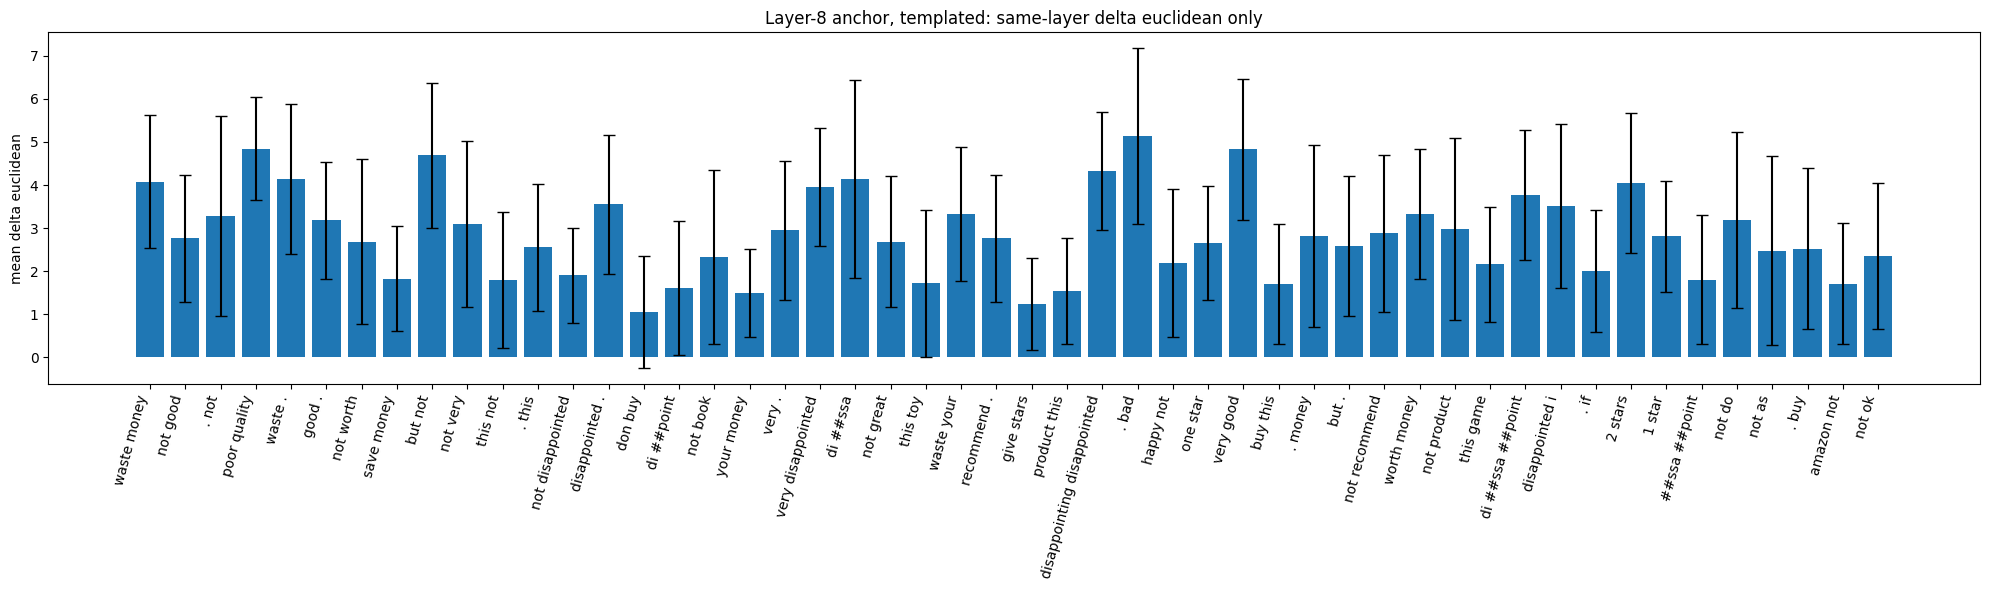

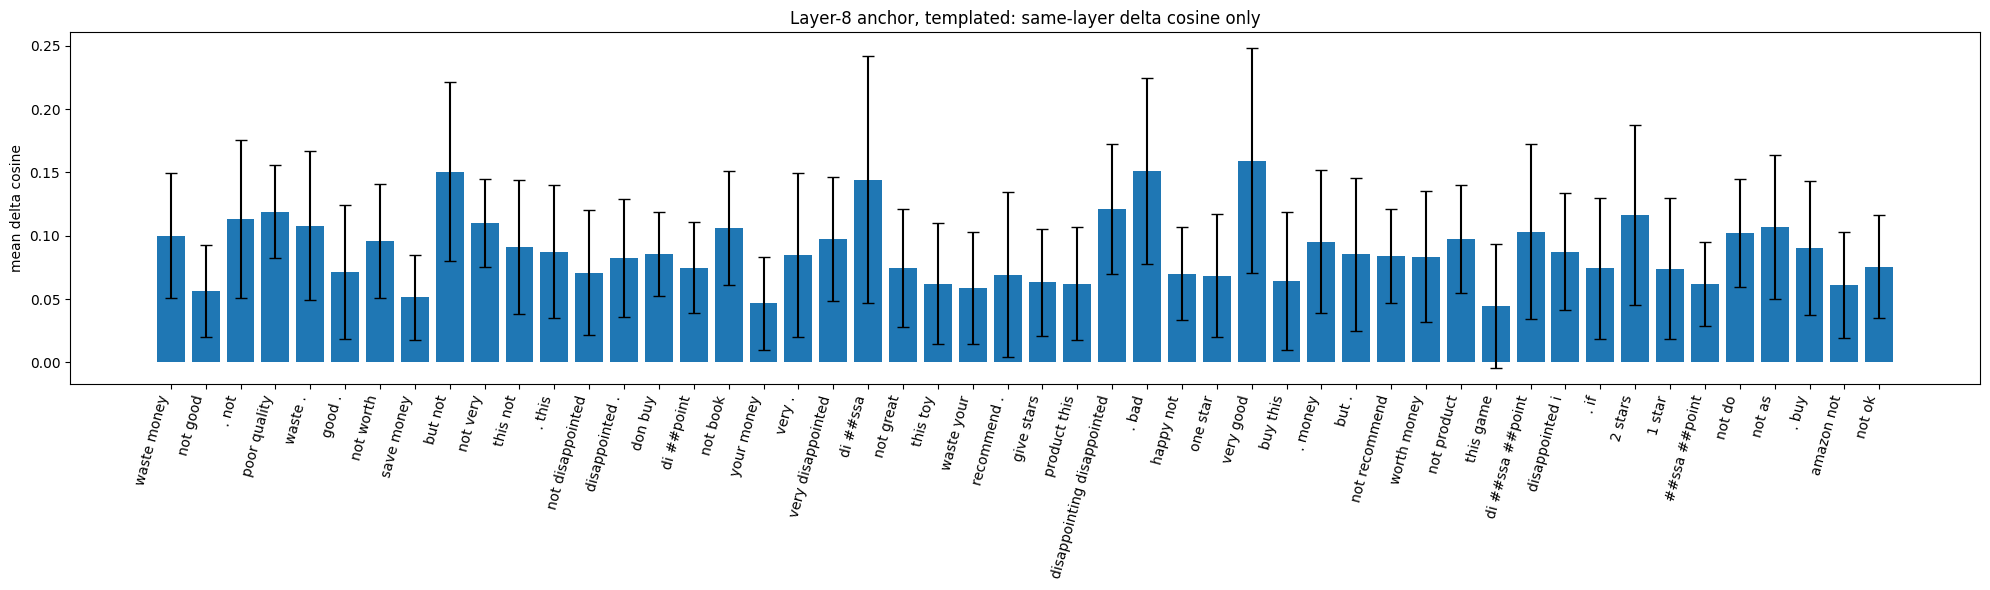

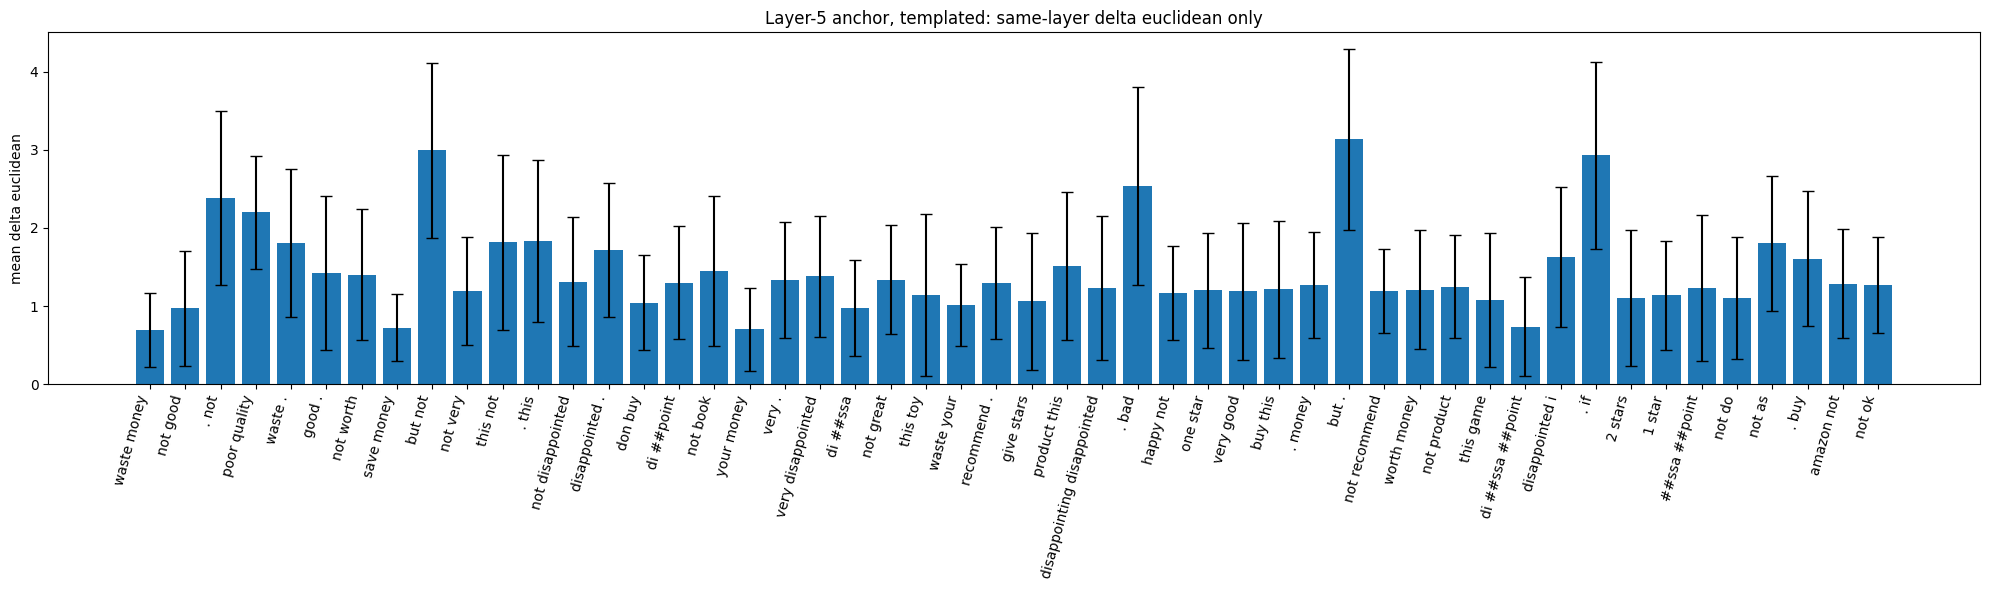

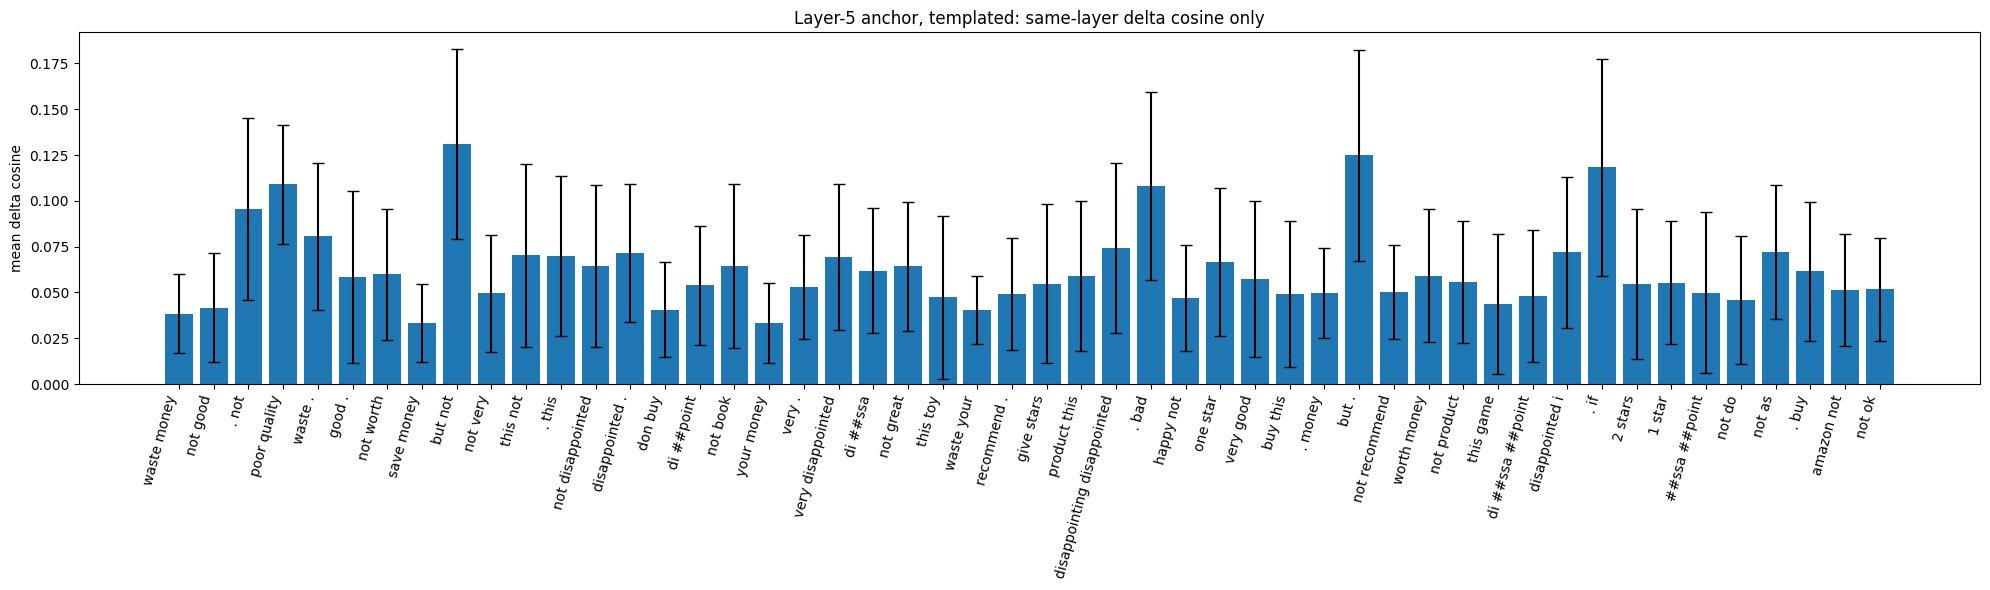

,label,mean_delta_tpl_l5_euclidean_l5,std_euclidean,mean_delta_tpl_l5_cosine_l5,std_cosine
25,waste money,0.692219,0.478331,0.038487,0.021608
77,not good,0.972043,0.735355,0.041735,0.029905
139,. not,2.383417,1.110045,0.095612,0.049725
65,poor quality,2.201464,0.722092,0.108950,0.032594
99,waste .,1.808661,0.950978,0.080728,0.040128
161,good .,1.418614,0.984689,0.058544,0.046859
116,not worth,1.401100,0.841275,0.059954,0.035716
144,save money,0.724037,0.424035,0.033388,0.021467
205,but not,2.992499,1.116461,0.130861,0.051954
190,not very,1.194187,0.692450,0.049671,0.031917


In [55]:
plot_anchor_same_layer_with_std(df_tpl_l12, anchor_layer=12, context="tpl")
plot_anchor_same_layer_with_std(df_tpl_l11, anchor_layer=11, context="tpl")
plot_anchor_same_layer_with_std(df_tpl_l8,  anchor_layer=8,  context="tpl")
plot_anchor_same_layer_with_std(df_tpl_l5,  anchor_layer=5,  context="tpl")

In [56]:
ANCHOR_LAYERS = (12, 11, 8, 5)


def build_matched_anchor_summary(
    anchor_dfs,
    context="iso",
):
    """
    Build the matched anchor/layer comparison for explicit Amazon
    rating proxies versus all non-rating-proxy candidates.
    """
    assert context in {"iso", "tpl"}

    rows = []

    for anchor_layer in ANCHOR_LAYERS:
        df_plot = add_amazon_candidate_group(
            anchor_dfs[anchor_layer]
        )

        df_rating = df_plot[
            df_plot["candidate_group"] == "rating_proxy"
        ]
        df_non_rating = df_plot[
            df_plot["candidate_group"] == "non_rating_proxy"
        ]

        if context == "iso":
            euc_col = (
                f"mean_delta_l{anchor_layer}_"
                f"euclidean_l{anchor_layer}"
            )
            cos_col = (
                f"mean_delta_l{anchor_layer}_"
                f"cosine_l{anchor_layer}"
            )
        else:
            euc_col = (
                f"mean_delta_tpl_l{anchor_layer}_"
                f"euclidean_l{anchor_layer}"
            )
            cos_col = (
                f"mean_delta_tpl_l{anchor_layer}_"
                f"cosine_l{anchor_layer}"
            )

        for group_name, group_df in (
            ("rating_proxy", df_rating),
            ("non_rating_proxy", df_non_rating),
        ):
            rows.append({
                "group": group_name,
                "count": len(group_df),
                "layer": f"L{anchor_layer}",
                "mean_delta_euclidean": (
                    group_df[euc_col].mean()
                ),
                "std_delta_euclidean": (
                    group_df[euc_col].std()
                ),
                "mean_delta_cosine": (
                    group_df[cos_col].mean()
                ),
                "std_delta_cosine": (
                    group_df[cos_col].std()
                ),
            })

    summary = pd.DataFrame(rows)

    layer_order = [
        f"L{layer}"
        for layer in ANCHOR_LAYERS
    ]

    summary["layer"] = pd.Categorical(
        summary["layer"],
        categories=layer_order,
        ordered=True,
    )

    return (
        summary
        .sort_values(["layer", "group"])
        .reset_index(drop=True)
    )


def plot_matched_anchor_deltas(
    anchor_dfs,
    context="iso",
):
    """
    Plot matched anchor/layer deltas with standard-deviation bars.
    """
    summary = build_matched_anchor_summary(
        anchor_dfs,
        context=context,
    )

    layer_order = [
        f"L{layer}"
        for layer in ANCHOR_LAYERS
    ]

    rating = (
        summary[
            summary["group"] == "rating_proxy"
        ]
        .set_index("layer")
        .loc[layer_order]
    )
    non_rating = (
        summary[
            summary["group"] == "non_rating_proxy"
        ]
        .set_index("layer")
        .loc[layer_order]
    )

    x = np.arange(len(layer_order))
    width = 0.35

    title_prefix = (
        "Matched anchor/layer only, isolated"
        if context == "iso"
        else "Matched anchor/layer only, templated"
    )

    rating_euc_std = np.nan_to_num(
        rating["std_delta_euclidean"].to_numpy(),
        nan=0.0,
    )
    non_rating_euc_std = np.nan_to_num(
        non_rating["std_delta_euclidean"].to_numpy(),
        nan=0.0,
    )
    rating_cos_std = np.nan_to_num(
        rating["std_delta_cosine"].to_numpy(),
        nan=0.0,
    )
    non_rating_cos_std = np.nan_to_num(
        non_rating["std_delta_cosine"].to_numpy(),
        nan=0.0,
    )

    # Euclidean
    plt.figure(figsize=(8, 5))
    plt.bar(
        x - width / 2,
        rating["mean_delta_euclidean"].to_numpy(),
        width,
        yerr=rating_euc_std,
        label="explicit rating proxy",
        capsize=4,
    )
    plt.bar(
        x + width / 2,
        non_rating["mean_delta_euclidean"].to_numpy(),
        width,
        yerr=non_rating_euc_std,
        label="non-rating proxy",
        capsize=4,
    )
    plt.xticks(x, layer_order)
    plt.ylabel("average mean delta euclidean")
    plt.title(
        f"{title_prefix}: rating proxy vs non-rating proxy"
    )
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Cosine
    plt.figure(figsize=(8, 5))
    plt.bar(
        x - width / 2,
        rating["mean_delta_cosine"].to_numpy(),
        width,
        yerr=rating_cos_std,
        label="explicit rating proxy",
        capsize=4,
    )
    plt.bar(
        x + width / 2,
        non_rating["mean_delta_cosine"].to_numpy(),
        width,
        yerr=non_rating_cos_std,
        label="non-rating proxy",
        capsize=4,
    )
    plt.xticks(x, layer_order)
    plt.ylabel("average mean delta cosine")
    plt.title(
        f"{title_prefix}: rating proxy vs non-rating proxy"
    )
    plt.legend()
    plt.tight_layout()
    plt.show()

    return summary


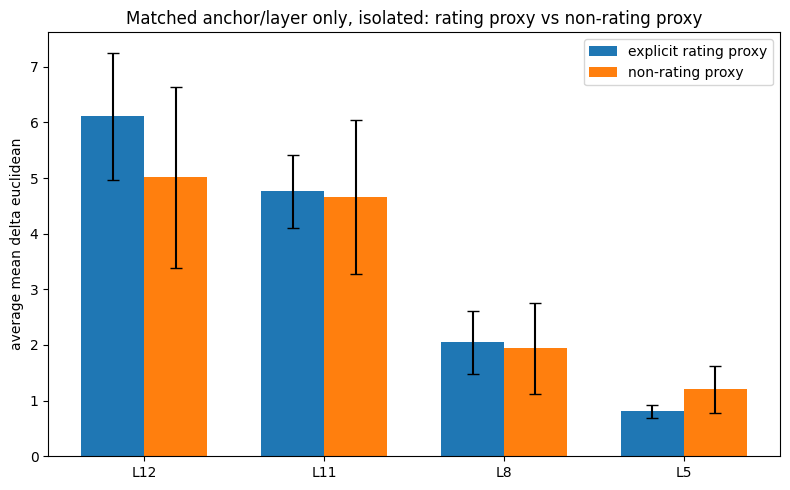

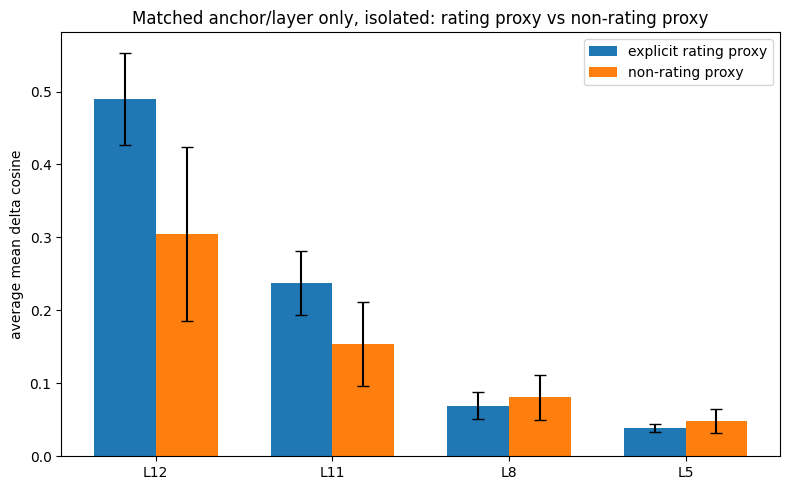

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_rating_proxy,1667,L12,5.015241,1.628504,0.304312,0.119372
1,rating_proxy,10,L12,6.106733,1.148717,0.490359,0.063134
2,non_rating_proxy,1667,L11,4.661939,1.379246,0.153923,0.057004
3,rating_proxy,10,L11,4.764235,0.656714,0.237397,0.044065
4,non_rating_proxy,1667,L8,1.939633,0.821045,0.080608,0.031204
5,rating_proxy,10,L8,2.052142,0.567361,0.069368,0.018699
6,non_rating_proxy,1667,L5,1.206655,0.423945,0.048756,0.016528
7,rating_proxy,10,L5,0.807034,0.113285,0.038847,0.005706


In [57]:
iso_anchor_dfs = {
    12: df_iso_l12,
    11: df_iso_l11,
     8: df_iso_l8,
     5: df_iso_l5,
}

summary_iso_matched = plot_matched_anchor_deltas(iso_anchor_dfs, context="iso")
summary_iso_matched

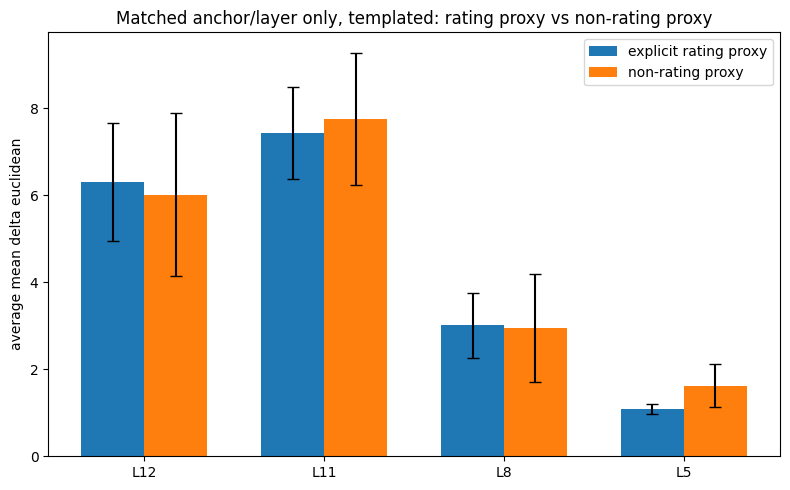

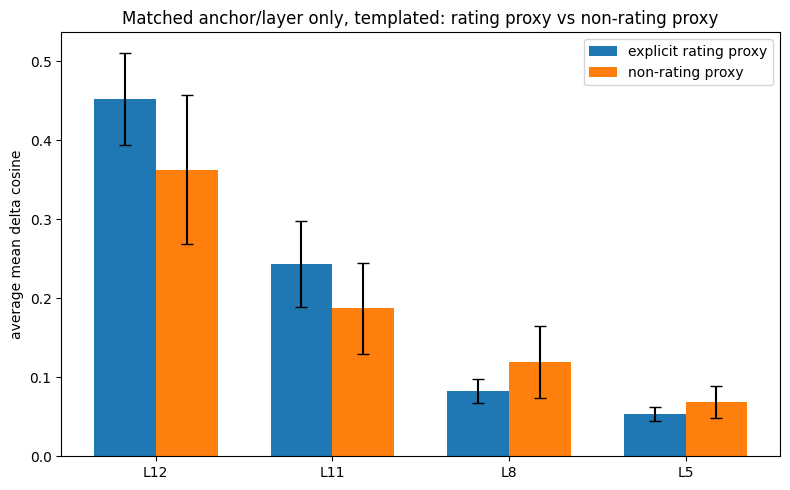

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_rating_proxy,1667,L12,6.018753,1.875821,0.362521,0.094490
1,rating_proxy,10,L12,6.306912,1.348367,0.452487,0.058353
2,non_rating_proxy,1667,L11,7.768731,1.517842,0.187257,0.057757
3,rating_proxy,10,L11,7.443831,1.055199,0.243230,0.053817
4,non_rating_proxy,1667,L8,2.957744,1.237834,0.119349,0.045208
5,rating_proxy,10,L8,3.011841,0.747339,0.082462,0.014684
6,non_rating_proxy,1667,L5,1.619037,0.496707,0.068699,0.020573
7,rating_proxy,10,L5,1.080834,0.111140,0.053704,0.008503


In [58]:
tpl_anchor_dfs = {
    12: df_tpl_l12,
    11: df_tpl_l11,
     8: df_tpl_l8,
     5: df_tpl_l5,
}

summary_tpl_matched = plot_matched_anchor_deltas(tpl_anchor_dfs, context="tpl")
summary_tpl_matched

DF_First

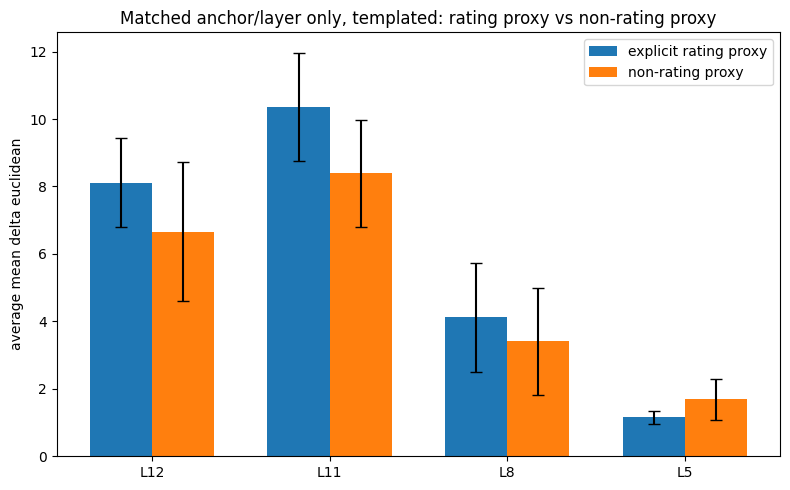

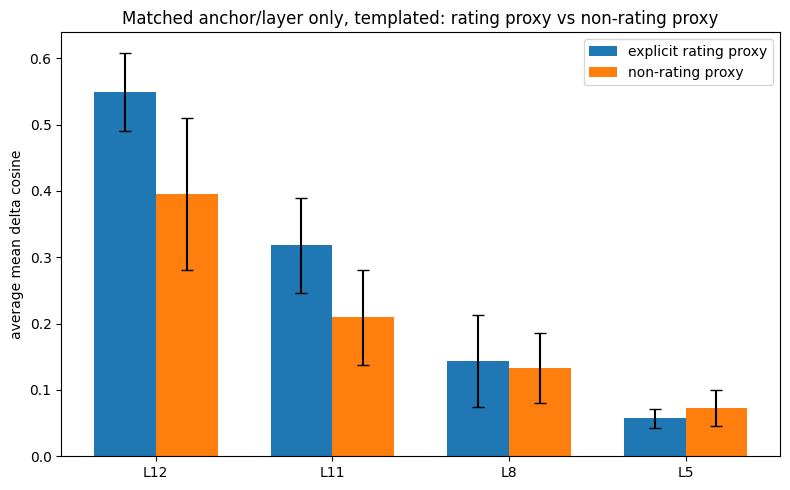

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_rating_proxy,1667,L12,6.657912,2.055341,0.395425,0.114602
1,rating_proxy,10,L12,8.111835,1.327045,0.549801,0.058894
2,non_rating_proxy,1667,L11,8.395541,1.585758,0.209617,0.071748
3,rating_proxy,10,L11,10.359403,1.613002,0.317830,0.071749
4,non_rating_proxy,1667,L8,3.414695,1.586442,0.132958,0.052565
5,rating_proxy,10,L8,4.125551,1.613289,0.143469,0.069586
6,non_rating_proxy,1667,L5,1.687905,0.606143,0.072655,0.026836
7,rating_proxy,10,L5,1.150211,0.200134,0.057373,0.014603


In [59]:
df_tpl_first_l12 = run_anchor_analysis(df_first_token, token_df, anchor_layer=12, context="tpl")
df_tpl_first_l11 = run_anchor_analysis(df_first_token, token_df, anchor_layer=11, context="tpl")
df_tpl_first_l8  = run_anchor_analysis(df_first_token, token_df, anchor_layer=8,  context="tpl")
df_tpl_first_l5  = run_anchor_analysis(df_first_token, token_df, anchor_layer=5,  context="tpl")

tpl_first_anchor_dfs = {
    12: df_tpl_first_l12,
    11: df_tpl_first_l11,
     8: df_tpl_first_l8,
     5: df_tpl_first_l5,
}

summary_tpl_first_matched = plot_matched_anchor_deltas(tpl_first_anchor_dfs, context="tpl")
summary_tpl_first_matched

DF_Sum

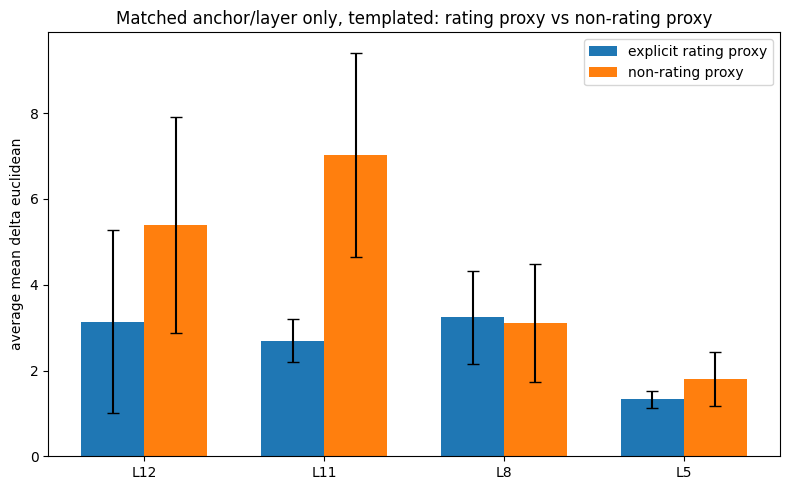

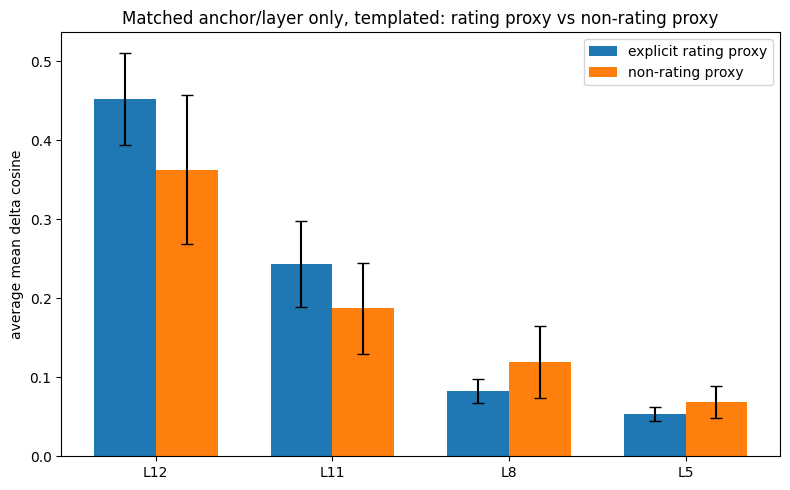

,group,count,layer,mean_delta_euclidean,std_delta_euclidean,mean_delta_cosine,std_delta_cosine
0,non_rating_proxy,1667,L12,5.398620,2.519943,0.362521,0.094490
1,rating_proxy,10,L12,3.141067,2.136794,0.452487,0.058353
2,non_rating_proxy,1667,L11,7.027211,2.388415,0.187257,0.057757
3,rating_proxy,10,L11,2.699226,0.503071,0.243230,0.053817
4,non_rating_proxy,1667,L8,3.110068,1.378488,0.119349,0.045208
5,rating_proxy,10,L8,3.239355,1.076410,0.082462,0.014684
6,non_rating_proxy,1667,L5,1.805220,0.626075,0.068699,0.020573
7,rating_proxy,10,L5,1.327002,0.195806,0.053704,0.008503


In [60]:
df_tpl_sum_l12 = run_anchor_analysis(df_sum, token_df, anchor_layer=12, context="tpl")
df_tpl_sum_l11 = run_anchor_analysis(df_sum, token_df, anchor_layer=11, context="tpl")
df_tpl_sum_l8  = run_anchor_analysis(df_sum, token_df, anchor_layer=8,  context="tpl")
df_tpl_sum_l5  = run_anchor_analysis(df_sum, token_df, anchor_layer=5,  context="tpl")

tpl_sum_anchor_dfs = {
    12: df_tpl_sum_l12,
    11: df_tpl_sum_l11,
     8: df_tpl_sum_l8,
     5: df_tpl_sum_l5,
}

summary_tpl_sum_matched = plot_matched_anchor_deltas(tpl_sum_anchor_dfs, context="tpl")
summary_tpl_sum_matched

---
## New method: genuinely contiguous salient n-grams

The original FP-growth method treats the top salient tokens in each review as
an unordered transaction. Sorting an itemset afterward gives it an order, but
does not prove that its tokens were adjacent.

This method instead uses the original BERT token positions stored in
`topk_vocab`. It retains a sequence only when:

1. every constituent token belongs to the top-*k* salient tokens;
2. the token positions are consecutive in the model input;
3. the same ordered token sequence reaches the minimum document support.

Support is document-level: an n-gram contributes at most once per sampled
review.


In [61]:
def extract_contiguous_salient_ngrams(
    salient_token_info,
    tokenizer,
    ngram_lengths=(2, 3),
    min_count=5,
):
    """
    Extract genuinely contiguous n-grams from the salient-token positions.

    Parameters
    ----------
    salient_token_info:
        Output created by build_salience_vocab_matrix_from_indices().
    tokenizer:
        The tokenizer used by the fine-tuned model.
    ngram_lengths:
        Contiguous sequence lengths to retain.
    min_count:
        Minimum number of sampled reviews containing the n-gram.

    Returns
    -------
    pandas.DataFrame
        One row per ordered contiguous n-gram.
    """
    number_of_documents = len(salient_token_info)

    document_counts = Counter()
    document_saliency_values = defaultdict(list)

    for example in salient_token_info:
        topk = sorted(
            example["topk_vocab"],
            key=lambda item: int(item["position"]),
        )

        # Store at most one saliency value per n-gram per document.
        ngram_saliency_in_document = {}

        for n in ngram_lengths:
            if len(topk) < n:
                continue

            for start in range(len(topk) - n + 1):
                window = topk[start:start + n]

                positions = [
                    int(item["position"])
                    for item in window
                ]

                is_contiguous = all(
                    right - left == 1
                    for left, right in zip(
                        positions,
                        positions[1:],
                    )
                )

                if not is_contiguous:
                    continue

                ordered_ids = tuple(
                    int(item["token_id"])
                    for item in window
                )

                mean_saliency = float(np.mean([
                    float(item["saliency_norm"])
                    for item in window
                ]))

                # If the same n-gram occurs more than once in one review,
                # retain its strongest occurrence but count the review once.
                previous = ngram_saliency_in_document.get(
                    ordered_ids,
                    -np.inf,
                )
                ngram_saliency_in_document[ordered_ids] = max(
                    previous,
                    mean_saliency,
                )

        for ordered_ids, mean_saliency in ngram_saliency_in_document.items():
            document_counts[ordered_ids] += 1
            document_saliency_values[ordered_ids].append(mean_saliency)

    rows = []

    for ordered_ids, count in document_counts.items():
        if count < min_count:
            continue

        ordered_tokens = tokenizer.convert_ids_to_tokens(
            list(ordered_ids)
        )
        support = count / number_of_documents
        saliency_score = float(np.mean(
            document_saliency_values[ordered_ids]
        ))

        rows.append({
            "ordered_ids": list(ordered_ids),
            "ordered_tokens": ordered_tokens,
            "ngram_text": tokenizer.convert_tokens_to_string(
                ordered_tokens
            ),
            "length": len(ordered_ids),
            "count": count,
            "support": support,
            "saliency_score": saliency_score,
            "score": support * saliency_score,
        })

    result = pd.DataFrame(rows)

    if result.empty:
        return pd.DataFrame(columns=[
            "ordered_ids",
            "ordered_tokens",
            "ngram_text",
            "length",
            "count",
            "support",
            "saliency_score",
            "score",
        ])

    return result.sort_values(
        ["score", "support"],
        ascending=False,
    ).reset_index(drop=True)


In [62]:
MIN_CONTIGUOUS_COUNT = 5
NGRAM_LENGTHS = (2, 3)

actual_ngrams_neg_5 = extract_contiguous_salient_ngrams(
    salient_token_info_neg,
    tokenizer,
    ngram_lengths=NGRAM_LENGTHS,
    min_count=MIN_CONTIGUOUS_COUNT,
)

actual_ngrams_neg_10 = extract_contiguous_salient_ngrams(
    salient_token_info_neg_10,
    tokenizer,
    ngram_lengths=NGRAM_LENGTHS,
    min_count=MIN_CONTIGUOUS_COUNT,
)

actual_ngrams_neg_5 = add_amazon_candidate_group(
    actual_ngrams_neg_5
)
actual_ngrams_neg_10 = add_amazon_candidate_group(
    actual_ngrams_neg_10
)

print("Top-5 salient-token setup:")
print("  actual contiguous n-grams:", len(actual_ngrams_neg_5))

print("Top-10 salient-token setup:")
print("  actual contiguous n-grams:", len(actual_ngrams_neg_10))


Top-5 salient-token setup:
  actual contiguous n-grams: 20
Top-10 salient-token setup:
  actual contiguous n-grams: 81


### Explicit Amazon rating proxies among all actual n-grams

This table shows every contiguous n-gram that meets the support threshold and
is classified as an explicit rating-value proxy. These form the proposed
shortcut-candidate group; the remaining n-grams form the comparison group.


In [63]:
print(
    actual_ngrams_neg_10["candidate_group"]
    .value_counts()
)

actual_rating_proxy_ngrams = (
    actual_ngrams_neg_10[
        actual_ngrams_neg_10["is_rating_proxy"]
    ]
    .sort_values(
        ["score", "support"],
        ascending=False,
    )
    .reset_index(drop=True)
)

actual_rating_proxy_ngrams[
    [
        "candidate_text",
        "ordered_tokens",
        "length",
        "count",
        "support",
        "saliency_score",
        "score",
    ]
]


candidate_group
non_rating_proxy    73
rating_proxy         8
Name: count, dtype: int64


,candidate_text,ordered_tokens,length,count,support,saliency_score,score
0,2 stars,"[2, stars]",2,13,0.0052,0.463083,0.002408
1,one star,"[one, star]",2,16,0.0064,0.344003,0.002202
2,two stars,"[two, stars]",2,11,0.0044,0.478783,0.002107
3,1 star,"[1, star]",2,14,0.0056,0.346674,0.001941
4,5 stars,"[5, stars]",2,10,0.0040,0.350703,0.001403
5,no stars,"[no, stars]",2,8,0.0032,0.381122,0.001220
6,zero stars,"[zero, stars]",2,5,0.0020,0.455295,0.000911
7,5 star,"[5, star]",2,5,0.0020,0.345549,0.000691


### Actual contiguous bigrams

In [64]:
actual_ngrams_neg_10[
    actual_ngrams_neg_10["length"] == 2
].sort_values(
    ["support", "saliency_score"],
    ascending=False,
).head(40)


,ordered_ids,ordered_tokens,ngram_text,length,count,support,saliency_score,score,candidate_text,is_rating_proxy,candidate_group
0,"[3532, 3737]","[poor, quality]",poor quality,2,22,0.0088,0.374445,0.003295,poor quality,False,non_rating_proxy
2,"[2025, 4276]","[not, worth]",not worth,2,22,0.0088,0.322054,0.002834,not worth,False,non_rating_proxy
3,"[4487, 11488]","[di, ##ssa]",dissa,2,18,0.0072,0.352670,0.002539,dissa,False,non_rating_proxy
9,"[2115, 2769]","[your, money]",your money,2,17,0.0068,0.284026,0.001931,your money,False,non_rating_proxy
1,"[2023, 9121]","[this, toy]",this toy,2,16,0.0064,0.480385,0.003074,this toy,False,non_rating_proxy
5,"[2028, 2732]","[one, star]",one star,2,16,0.0064,0.344003,0.002202,one star,True,rating_proxy
7,"[11488, 8400]","[##ssa, ##point]",##ssapoint,2,14,0.0056,0.354767,0.001987,##ssapoint,False,non_rating_proxy
8,"[1015, 2732]","[1, star]",1 star,2,14,0.0056,0.346674,0.001941,1 star,True,rating_proxy
15,"[5949, 2115]","[waste, your]",waste your,2,14,0.0056,0.299818,0.001679,waste your,False,non_rating_proxy
4,"[1016, 3340]","[2, stars]",2 stars,2,13,0.0052,0.463083,0.002408,2 stars,True,rating_proxy


### Actual contiguous trigrams

In [65]:
actual_ngrams_neg_10[
    actual_ngrams_neg_10["length"] == 3
].sort_values(
    ["support", "saliency_score"],
    ascending=False,
).head(40)


,ordered_ids,ordered_tokens,ngram_text,length,count,support,saliency_score,score,candidate_text,is_rating_proxy,candidate_group
10,"[4487, 11488, 8400]","[di, ##ssa, ##point]",dissapoint,3,14,0.0056,0.334388,0.001873,dissapoint,False,non_rating_proxy
21,"[5949, 2115, 2769]","[waste, your, money]",waste your money,3,10,0.0040,0.334106,0.001336,waste your money,False,non_rating_proxy
54,"[4487, 3736, 8400]","[di, ##sa, ##point]",disapoint,3,6,0.0024,0.324813,0.000780,disapoint,False,non_rating_proxy
56,"[1012, 2200, 15640]","[., very, disappointing]",. very disappointing,3,5,0.0020,0.362573,0.000725,. very disappointing,False,non_rating_proxy
57,"[4895, 18866, 3085]","[un, ##watch, ##able]",unwatchable,3,5,0.0020,0.360679,0.000721,unwatchable,False,non_rating_proxy
68,"[11488, 8400, 3672]","[##ssa, ##point, ##ment]",##ssapointment,3,5,0.0020,0.322184,0.000644,##ssapointment,False,non_rating_proxy


### Candidate table for subsequent experiments

`actual_ngram_candidates` can be passed to the same hidden-state extraction
functions used in Experiment 1 because it contains `ordered_ids`,
`ordered_tokens`, `support`, `saliency_score`, and `score`.


In [66]:
actual_ngram_candidates = (
    actual_ngrams_neg_10
    .sort_values("score", ascending=False)
    .head(100)
    .copy()
)

# The classifier has already been applied to the complete n-gram table,
# but applying it again makes this cell independently robust.
actual_ngram_candidates = add_amazon_candidate_group(
    actual_ngram_candidates
)

print(
    actual_ngram_candidates["candidate_group"]
    .value_counts()
)

display(
    actual_ngram_candidates[
        actual_ngram_candidates["is_rating_proxy"]
    ][
        [
            "candidate_text",
            "ordered_tokens",
            "length",
            "count",
            "support",
            "saliency_score",
            "score",
        ]
    ]
    .sort_values("score", ascending=False)
    .head(50)
)

actual_ngram_candidates.head(20)


candidate_group
non_rating_proxy    73
rating_proxy         8
Name: count, dtype: int64


,candidate_text,ordered_tokens,length,count,support,saliency_score,score
4,2 stars,"[2, stars]",2,13,0.0052,0.463083,0.002408
5,one star,"[one, star]",2,16,0.0064,0.344003,0.002202
6,two stars,"[two, stars]",2,11,0.0044,0.478783,0.002107
8,1 star,"[1, star]",2,14,0.0056,0.346674,0.001941
20,5 stars,"[5, stars]",2,10,0.0040,0.350703,0.001403
23,no stars,"[no, stars]",2,8,0.0032,0.381122,0.001220
41,zero stars,"[zero, stars]",2,5,0.0020,0.455295,0.000911
58,5 star,"[5, star]",2,5,0.0020,0.345549,0.000691


,ordered_ids,ordered_tokens,ngram_text,length,count,support,saliency_score,score,candidate_text,is_rating_proxy,candidate_group
0,"[3532, 3737]","[poor, quality]",poor quality,2,22,0.0088,0.374445,0.003295,poor quality,False,non_rating_proxy
1,"[2023, 9121]","[this, toy]",this toy,2,16,0.0064,0.480385,0.003074,this toy,False,non_rating_proxy
2,"[2025, 4276]","[not, worth]",not worth,2,22,0.0088,0.322054,0.002834,not worth,False,non_rating_proxy
3,"[4487, 11488]","[di, ##ssa]",dissa,2,18,0.0072,0.352670,0.002539,dissa,False,non_rating_proxy
4,"[1016, 3340]","[2, stars]",2 stars,2,13,0.0052,0.463083,0.002408,2 stars,True,rating_proxy
5,"[2028, 2732]","[one, star]",one star,2,16,0.0064,0.344003,0.002202,one star,True,rating_proxy
6,"[2048, 3340]","[two, stars]",two stars,2,11,0.0044,0.478783,0.002107,two stars,True,rating_proxy
7,"[11488, 8400]","[##ssa, ##point]",##ssapoint,2,14,0.0056,0.354767,0.001987,##ssapoint,False,non_rating_proxy
8,"[1015, 2732]","[1, star]",1 star,2,14,0.0056,0.346674,0.001941,1 star,True,rating_proxy
9,"[2115, 2769]","[your, money]",your money,2,17,0.0068,0.284026,0.001931,your money,False,non_rating_proxy


### Representation-shift experiment on actual n-grams

In [67]:
actual_ngram_ids = actual_ngram_candidates["ordered_ids"].tolist()
layers = (5, 8, 11, 12)

# Pretrained BERT
actual_pt_iso, actual_pt_logits_iso = extract_itemset_hidden_states(
    pt_bert,
    tokenizer,
    actual_ngram_ids,
    device,
    layers=layers,
    context_mode="isolated",
)

actual_pt_tpl, actual_pt_logits_tpl = extract_itemset_hidden_states(
    pt_bert,
    tokenizer,
    actual_ngram_ids,
    device,
    layers=layers,
    context_mode="template",
)

# Fine-tuned Amazon Polarity BERT
actual_ft_iso, actual_ft_logits_iso = extract_itemset_hidden_states(
    ft_bert,
    tokenizer,
    actual_ngram_ids,
    device,
    layers=layers,
    context_mode="isolated",
)

actual_ft_tpl, actual_ft_logits_tpl = extract_itemset_hidden_states(
    ft_bert,
    tokenizer,
    actual_ngram_ids,
    device,
    layers=layers,
    context_mode="template",
)

for layer in layers:
    actual_ngram_candidates[f"pt_iso_l{layer}"] = list(
        actual_pt_iso[layer]
    )
    actual_ngram_candidates[f"pt_tpl_l{layer}"] = list(
        actual_pt_tpl[layer]
    )
    actual_ngram_candidates[f"ft_iso_l{layer}"] = list(
        actual_ft_iso[layer]
    )
    actual_ngram_candidates[f"ft_tpl_l{layer}"] = list(
        actual_ft_tpl[layer]
    )

actual_ngram_candidates["ft_iso_logits"] = list(
    actual_ft_logits_iso
)
actual_ngram_candidates["ft_tpl_logits"] = list(
    actual_ft_logits_tpl
)

actual_ngram_candidates.head()


,ordered_ids,ordered_tokens,ngram_text,length,count,support,saliency_score,score,candidate_text,is_rating_proxy,...,pt_iso_l11,pt_tpl_l11,ft_iso_l11,ft_tpl_l11,pt_iso_l12,pt_tpl_l12,ft_iso_l12,ft_tpl_l12,ft_iso_logits,ft_tpl_logits
0,"[3532, 3737]","[poor, quality]",poor quality,2,22,0.0088,0.374445,0.003295,poor quality,False,...,"[[-0.6582995, -0.34614167, -0.5149537, 0.43739...","[[-0.046658807, 0.056461424, -0.76607054, 0.27...","[[0.6025194, 1.4732887, 0.39120823, -0.4426606...","[[0.39587486, 1.4936501, 0.2519207, -0.2925731...","[[-0.573245, -0.0024041906, -0.4836857, 0.1618...","[[-0.02439433, 0.013218988, -0.5287452, 0.1370...","[[0.842723, 1.3904446, 0.14396977, -0.00345219...","[[0.61929685, 1.4468265, -0.003985282, 0.10915...","[4.148242, -3.9428065]","[4.0577636, -3.952619]"
1,"[2023, 9121]","[this, toy]",this toy,2,16,0.0064,0.480385,0.003074,this toy,False,...,"[[-0.079651214, 0.07678346, 0.25496495, 0.0753...","[[0.05349237, -0.4817706, 1.089946, -0.5141598...","[[-0.52222514, 0.39282328, 0.6551055, -0.03363...","[[-0.3929261, 0.5312341, 1.407586, -0.85673237...","[[-0.37415504, -0.0984503, 0.19148749, 0.01087...","[[-0.08137485, -0.40716973, 1.1686866, -0.5771...","[[-0.112694435, 0.03495968, 0.26801467, -0.065...","[[0.036094278, 0.043837637, 0.71326584, -0.426...","[-0.72467136, 0.56788355]","[-1.4577118, 1.4964688]"
2,"[2025, 4276]","[not, worth]",not worth,2,22,0.0088,0.322054,0.002834,not worth,False,...,"[[0.03692086, -0.0754198, -0.3122787, 0.359409...","[[-0.09344318, -0.17276576, -0.27125728, 0.222...","[[0.4860694, 1.7169783, 0.08714421, -0.4923771...","[[0.3745257, 1.5660915, 0.10350089, -0.4091795...","[[-0.0151455095, -0.044532485, -0.20476979, 0....","[[-0.08424664, -0.32025594, -0.15801734, 0.099...","[[0.6531525, 1.3758624, 0.025745366, 0.0110749...","[[0.5391013, 1.4521788, -0.076355025, 0.068101...","[4.070881, -3.922205]","[3.9426458, -3.9396427]"
3,"[4487, 11488]","[di, ##ssa]",dissa,2,18,0.0072,0.352670,0.002539,dissa,False,...,"[[0.21448681, -0.8572439, -0.008413486, 0.3043...","[[-0.17987013, -0.40803933, -0.009806797, 0.20...","[[0.19386348, 1.6609873, -0.0010972992, -0.476...","[[0.03122822, 1.4469583, 0.11602025, -0.221354...","[[0.1712405, -0.6644701, -0.27956492, 0.011139...","[[-0.11711155, -0.5048848, 0.080046944, 0.1617...","[[0.50853896, 1.3374065, -0.07994865, 0.138387...","[[0.38657892, 1.3992087, -0.0921358, 0.2194442...","[3.743505, -3.481531]","[3.816677, -3.7263453]"
4,"[1016, 3340]","[2, stars]",2 stars,2,13,0.0052,0.463083,0.002408,2 stars,True,...,"[[-0.047549512, 0.05983063, 0.077144295, 0.211...","[[-0.08668965, 0.141533, 0.39775056, -0.561606...","[[0.36716843, 1.5791074, 0.11580299, -0.268645...","[[0.23657106, 1.5710862, 0.14856559, -0.143863...","[[-0.0123045035, -0.060765244, -0.010504164, 0...","[[-0.14949271, -0.41269508, 0.2105463, -0.1937...","[[0.5622064, 1.3550786, -0.072399884, 0.066255...","[[0.43574098, 1.3443308, -0.10419719, 0.178178...","[3.8243086, -3.4153273]","[3.7091267, -3.4520183]"


In [68]:
actual_shift_table = actual_ngram_candidates[
    [
        "ordered_ids",
        "ordered_tokens",
        "ngram_text",
        "length",
        "count",
        "support",
        "saliency_score",
        "score",
        "candidate_text",
        "is_rating_proxy",
        "candidate_group",
    ]
].copy()

for layer in (5, 8, 11, 12):
    actual_shift_table[f"cos_shift_iso_l{layer}"] = [
        cos_shift(pt, ft)
        for pt, ft in zip(
            actual_ngram_candidates[f"pt_iso_l{layer}"],
            actual_ngram_candidates[f"ft_iso_l{layer}"],
        )
    ]

    actual_shift_table[f"euc_iso_l{layer}"] = [
        euc_dist(pt, ft)
        for pt, ft in zip(
            actual_ngram_candidates[f"pt_iso_l{layer}"],
            actual_ngram_candidates[f"ft_iso_l{layer}"],
        )
    ]

    actual_shift_table[f"cos_shift_tpl_l{layer}"] = [
        cos_shift(pt, ft)
        for pt, ft in zip(
            actual_ngram_candidates[f"pt_tpl_l{layer}"],
            actual_ngram_candidates[f"ft_tpl_l{layer}"],
        )
    ]

    actual_shift_table[f"euc_tpl_l{layer}"] = [
        euc_dist(pt, ft)
        for pt, ft in zip(
            actual_ngram_candidates[f"pt_tpl_l{layer}"],
            actual_ngram_candidates[f"ft_tpl_l{layer}"],
        )
    ]

actual_shift_table.sort_values(
    "score",
    ascending=False,
).head(20)


,ordered_ids,ordered_tokens,ngram_text,length,count,support,saliency_score,score,candidate_text,is_rating_proxy,...,cos_shift_tpl_l8,euc_tpl_l8,cos_shift_iso_l11,euc_iso_l11,cos_shift_tpl_l11,euc_tpl_l11,cos_shift_iso_l12,euc_iso_l12,cos_shift_tpl_l12,euc_tpl_l12
0,"[3532, 3737]","[poor, quality]",poor quality,2,22,0.0088,0.374445,0.003295,poor quality,False,...,0.297139,12.256166,0.922233,26.678213,0.907652,26.950928,0.956383,20.410170,0.948437,20.625530
1,"[2023, 9121]","[this, toy]",this toy,2,16,0.0064,0.480385,0.003074,this toy,False,...,0.236341,11.237286,0.313890,13.367220,0.360790,15.340539,0.464412,10.391785,0.604856,13.516653
2,"[2025, 4276]","[not, worth]",not worth,2,22,0.0088,0.322054,0.002834,not worth,False,...,0.370120,13.861242,0.945059,25.764975,0.947969,26.208675,0.981120,20.997009,1.014924,21.647341
3,"[4487, 11488]","[di, ##ssa]",dissa,2,18,0.0072,0.352670,0.002539,dissa,False,...,0.431907,15.187602,0.937223,24.843542,0.896632,25.204807,1.049693,22.152899,0.977789,21.364725
4,"[1016, 3340]","[2, stars]",2 stars,2,13,0.0052,0.463083,0.002408,2 stars,True,...,0.311116,12.151030,0.950954,26.408926,0.903505,25.698038,1.040980,21.909420,1.022934,21.750034
5,"[2028, 2732]","[one, star]",one star,2,16,0.0064,0.344003,0.002202,one star,True,...,0.349792,13.348772,0.922302,26.709288,0.861299,25.659760,1.020963,21.474960,0.988335,21.721514
6,"[2048, 3340]","[two, stars]",two stars,2,11,0.0044,0.478783,0.002107,two stars,True,...,0.316964,12.578195,0.942967,26.912624,0.869964,26.183409,1.047796,22.264858,0.980651,21.077694
7,"[11488, 8400]","[##ssa, ##point]",##ssapoint,2,14,0.0056,0.354767,0.001987,##ssapoint,False,...,0.318331,13.261456,0.200356,11.907366,0.297405,14.606196,0.370604,8.415770,0.461430,10.374506
8,"[1015, 2732]","[1, star]",1 star,2,14,0.0056,0.346674,0.001941,1 star,True,...,0.335234,12.652298,0.897945,25.372036,0.837723,24.018953,1.030084,21.205290,1.023478,21.984612
9,"[2115, 2769]","[your, money]",your money,2,17,0.0068,0.284026,0.001931,your money,False,...,0.253704,11.443112,0.592992,17.313343,0.343460,13.683247,0.899500,19.533113,0.603461,14.557885
